# LifeMap AI: Comprehensive Diabetes Risk Assessment & Model Evaluation Report
**Capstone Project — Non-Invasive Explainable Diabetes Risk Stratification**  
*Primary Development Cohort: CDC NHANES (2013–2018) | External Validation: CDC BRFSS (2015, N=249,049)*

In [1]:
# Setup environment & display options
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json
from pathlib import Path
from IPython.display import display, HTML, Image
from PIL import Image as PILImage

pd.set_option('display.max_columns', 20)
pd.set_option('display.precision', 4)
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
print('Environment initialized successfully.')

Environment initialized successfully.


## 1. Dataset Architecture & Summary
Summary of the primary CDC NHANES development cohort and CDC BRFSS 2015 external validation cohort.

In [2]:
nhanes_df = pd.read_csv('../../data/processed/nhanes_diabetes_processed.csv')
brfss_df = pd.read_csv('../../data/processed/brfss_diabetes_processed.csv')

n_nhanes = len(nhanes_df)
nhanes_pos = int(nhanes_df['diabetes'].sum())
nhanes_rate = nhanes_pos / n_nhanes * 100

n_brfss = len(brfss_df)
brfss_pos = int(brfss_df['diabetes'].sum())
brfss_rate = brfss_pos / n_brfss * 100

full_features = [c for c in nhanes_df.columns if c not in ['SEQN', 'diabetes']]
shared_features = ['age_bucket', 'sex', 'bmi', 'high_bp', 'high_chol', 'smoker', 'phys_activity']

summary_table = pd.DataFrame({
    'Dataset Cohort': ['CDC NHANES (Primary Development)', 'CDC BRFSS 2015 (External Validation)'],
    'Total Participants (N)': [f'{n_nhanes:,}', f'{n_brfss:,}'],
    'Diabetes Cases': [f'{nhanes_pos:,}', f'{brfss_pos:,}'],
    'Class Prevalence': [f'{nhanes_rate:.2f}%', f'{brfss_rate:.2f}%'],
    'Feature Subspace': [f'{len(full_features)} Non-Lab Features', f'{len(shared_features)} Shared Survey Features'],
    'Target Definition': ['DIQ010 (1=Yes, 2=No)', 'DIABETE3 (1=Yes, 0=No)']
})
display(HTML(summary_table.to_html(index=False, classes='table table-striped table-hover')))
print(f'\nNHANES Full Feature Set ({len(full_features)}):\n  {full_features}')
print(f'\nShared-7 Feature Space ({len(shared_features)}):\n  {shared_features}')

Dataset Cohort,Total Participants (N),Diabetes Cases,Class Prevalence,Feature Subspace,Target Definition
CDC NHANES (Primary Development),"17,468","2,449",14.02%,12 Non-Lab Features,"DIQ010 (1=Yes, 2=No)"
CDC BRFSS 2015 (External Validation),"249,049","35,346",14.19%,7 Shared Survey Features,"DIABETE3 (1=Yes, 0=No)"



NHANES Full Feature Set (12):
  ['cycle', 'age', 'age_bucket', 'sex', 'bmi', 'mean_sbp', 'mean_dbp', 'high_bp', 'high_chol', 'smoker', 'phys_activity', 'family_history']

Shared-7 Feature Space (7):
  ['age_bucket', 'sex', 'bmi', 'high_bp', 'high_chol', 'smoker', 'phys_activity']


## 2. Model Comparison Table (NHANES Held-Out Test Set — Full Features)
Performance of all candidate architectures on the held-out test partition ($n = 2,621$).
**The top-performing model for each column is highlighted in green.**

In [3]:
table_df = pd.read_csv('../reports/tables/nhanes_full_test_comparison.csv')

def parse_metric(val):
    try:
        return float(str(val).split()[0])
    except:
        return 0.0

num_df = table_df.copy()
metrics = ['Accuracy', 'Balanced Acc', 'Precision', 'Recall', 'F1', 'ROC-AUC', 'PR-AUC', 'Brier']
for m in metrics:
    num_df[f'{m}_val'] = num_df[m].apply(parse_metric)

def highlight_max_cols(s):
    style_res = pd.DataFrame('', index=s.index, columns=s.columns)
    mask = s['Model'] != 'Trivial Baseline (All No)'
    green_style = 'background-color: #D1FAE5; font-weight: bold; color: #065F46;'
    
    for c in ['Accuracy', 'Balanced Acc', 'Precision', 'Recall', 'F1', 'ROC-AUC', 'PR-AUC']:
        best_idx = num_df.loc[mask, f'{c}_val'].idxmax()
        style_res.loc[best_idx, c] = green_style
        
    # Brier score: lower is better
    best_brier_idx = num_df.loc[mask, 'Brier_val'].idxmin()
    style_res.loc[best_brier_idx, 'Brier'] = green_style
    return style_res

styled = table_df.style.apply(highlight_max_cols, axis=None).set_caption(
    '<b>Comprehensive Model Performance (NHANES Full Features Test Set, N=2,621)</b>'
)
display(styled)

,Model,Accuracy,Balanced Acc,Precision,Recall,F1,ROC-AUC,PR-AUC,Brier
0,Trivial Baseline (All No),0.860 [0.847-0.873],0.500000,0.000000,0.000 [0.000-0.000],0.000000,0.500 [0.468-0.534],0.140 [0.127-0.153],0.140000
1,Logistic Regression,0.754 [0.738-0.771],0.783000,0.344000,0.823 [0.788-0.861],0.485000,0.858 [0.838-0.876],0.477 [0.430-0.532],0.162000
2,Random Forest,0.811 [0.797-0.825],0.771000,0.403000,0.715 [0.668-0.759],0.515000,0.853 [0.833-0.870],0.459 [0.411-0.513],0.126000
3,XGBoost,0.762 [0.746-0.778],0.789000,0.352000,0.826 [0.786-0.864],0.494000,0.858 [0.838-0.875],0.480 [0.432-0.534],0.155000
4,SVM (Linear),0.865 [0.852-0.878],0.584000,0.555000,0.193 [0.156-0.232],0.286000,0.858 [0.838-0.876],0.477 [0.428-0.531],0.092000
5,MLP (PyTorch),0.739 [0.723-0.755],0.786000,0.332000,0.851 [0.815-0.886],0.478000,0.857 [0.838-0.876],0.489 [0.439-0.544],0.166000
6,TabNet,0.861 [0.848-0.874],0.532000,0.540000,0.073 [0.048-0.101],0.129000,0.849 [0.830-0.868],0.458 [0.410-0.510],0.094000
7,Stacking Ensemble,0.868 [0.855-0.881],0.582000,0.591000,0.185 [0.149-0.224],0.282000,0.859 [0.840-0.877],0.486 [0.436-0.543],0.091000
8,XGBoost (SMOTE),0.799 [0.783-0.814],0.767000,0.386000,0.723 [0.674-0.765],0.503000,0.848 [0.828-0.866],0.453 [0.407-0.505],0.132000
9,Final Calibrated XGBoost,0.761 [0.744-0.778],0.788000,0.351000,0.826 [0.786-0.864],0.493000,0.856 [0.836-0.874],0.457 [0.412-0.505],0.092000


## 3. Key Performance Metrics Comparison (Bar Chart)
Side-by-side comparison across accuracy, recall, ROC-AUC, PR-AUC, and F1 score.

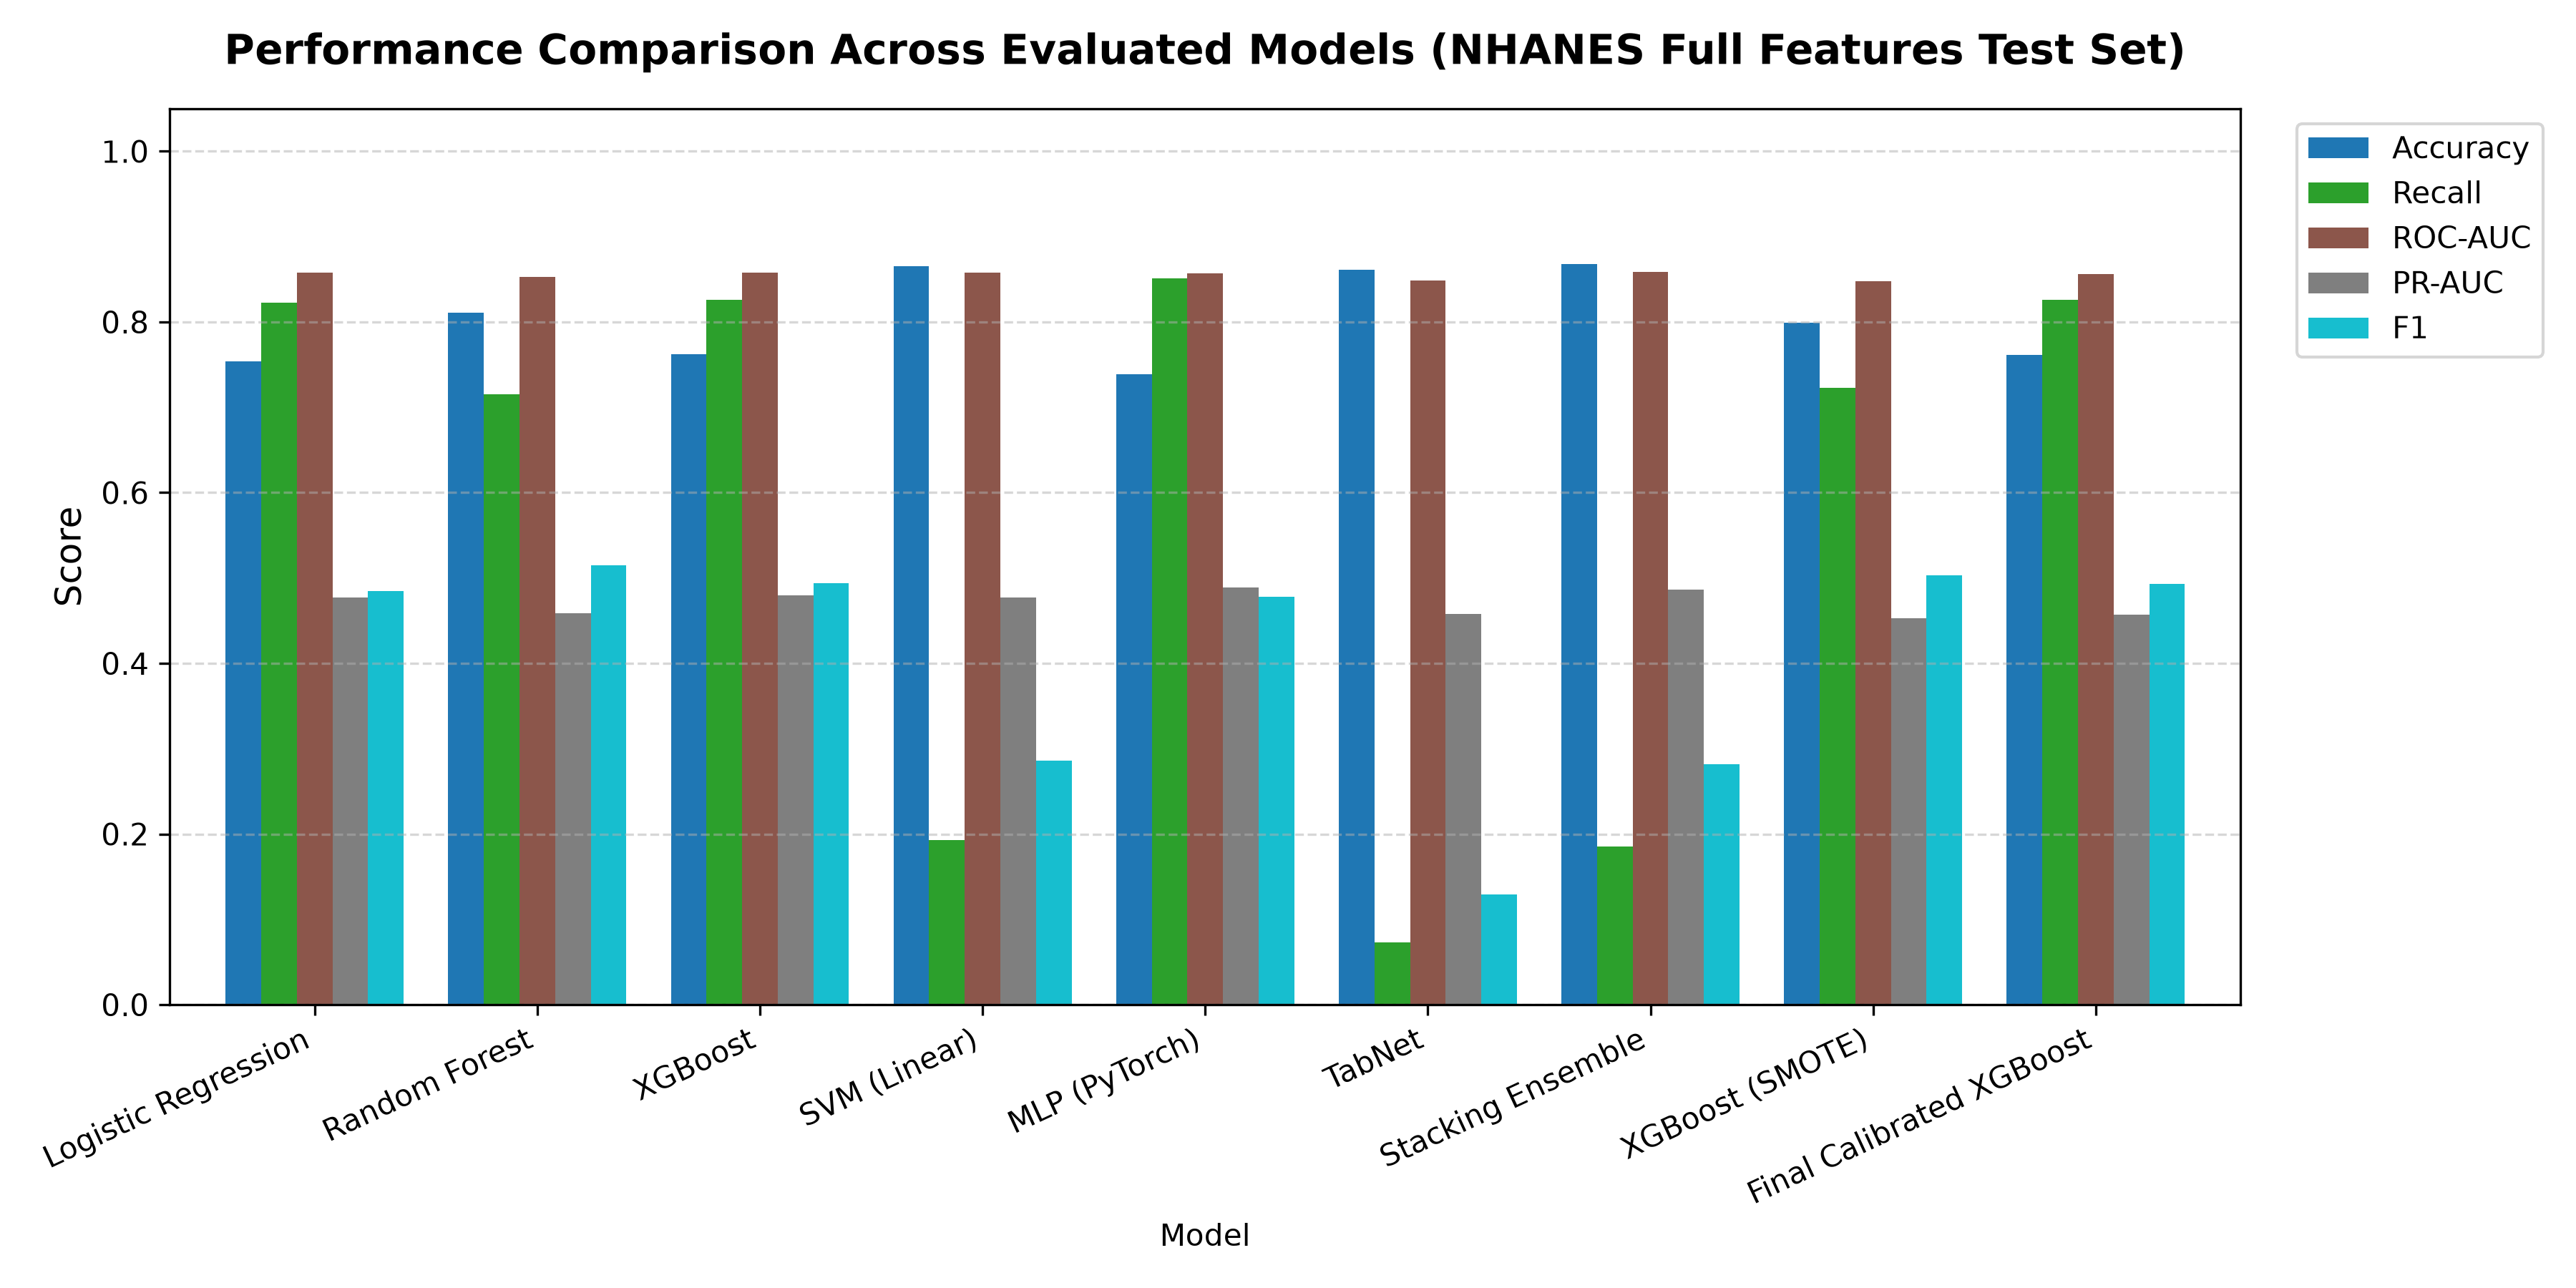

In [4]:
display(Image(filename='../reports/figures/model_metrics_bar_chart.png'))

## 4. Confusion Matrices for All Evaluated Models
Matrix breakdown across all candidate architectures on the held-out test set.

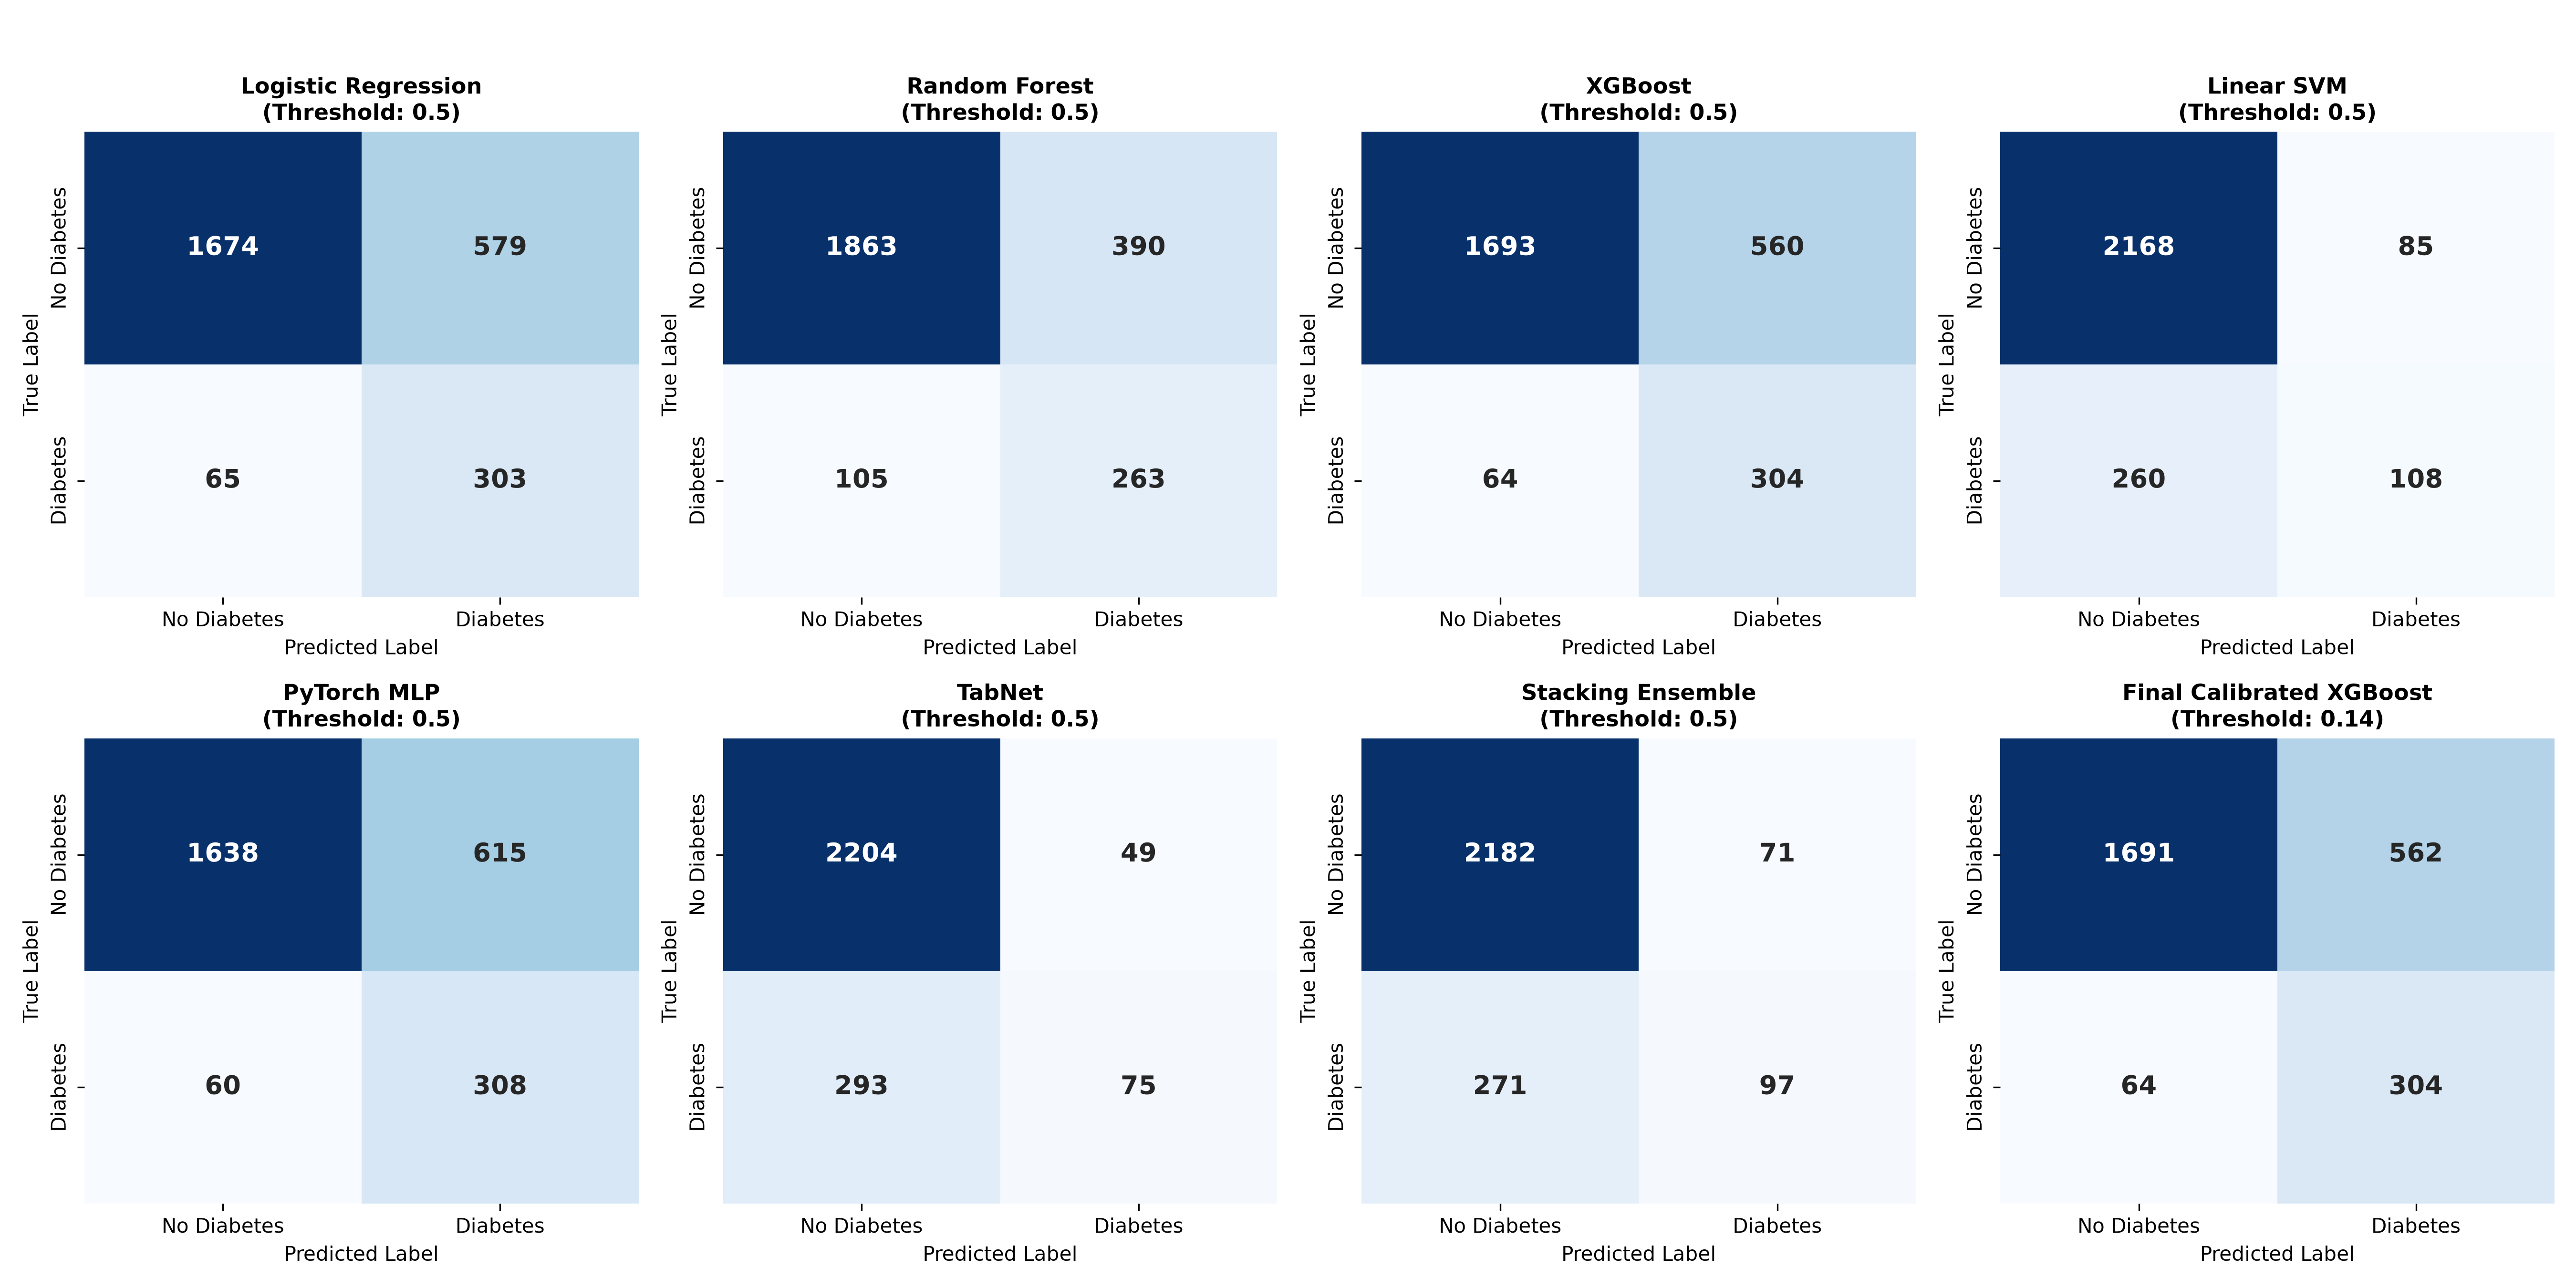

In [5]:
display(Image(filename='../reports/figures/confusion_matrices_all_models.png'))

## 5. ROC and Precision-Recall Curves (All Models Overlaid)
Simultaneous comparison of discriminative curves across models.

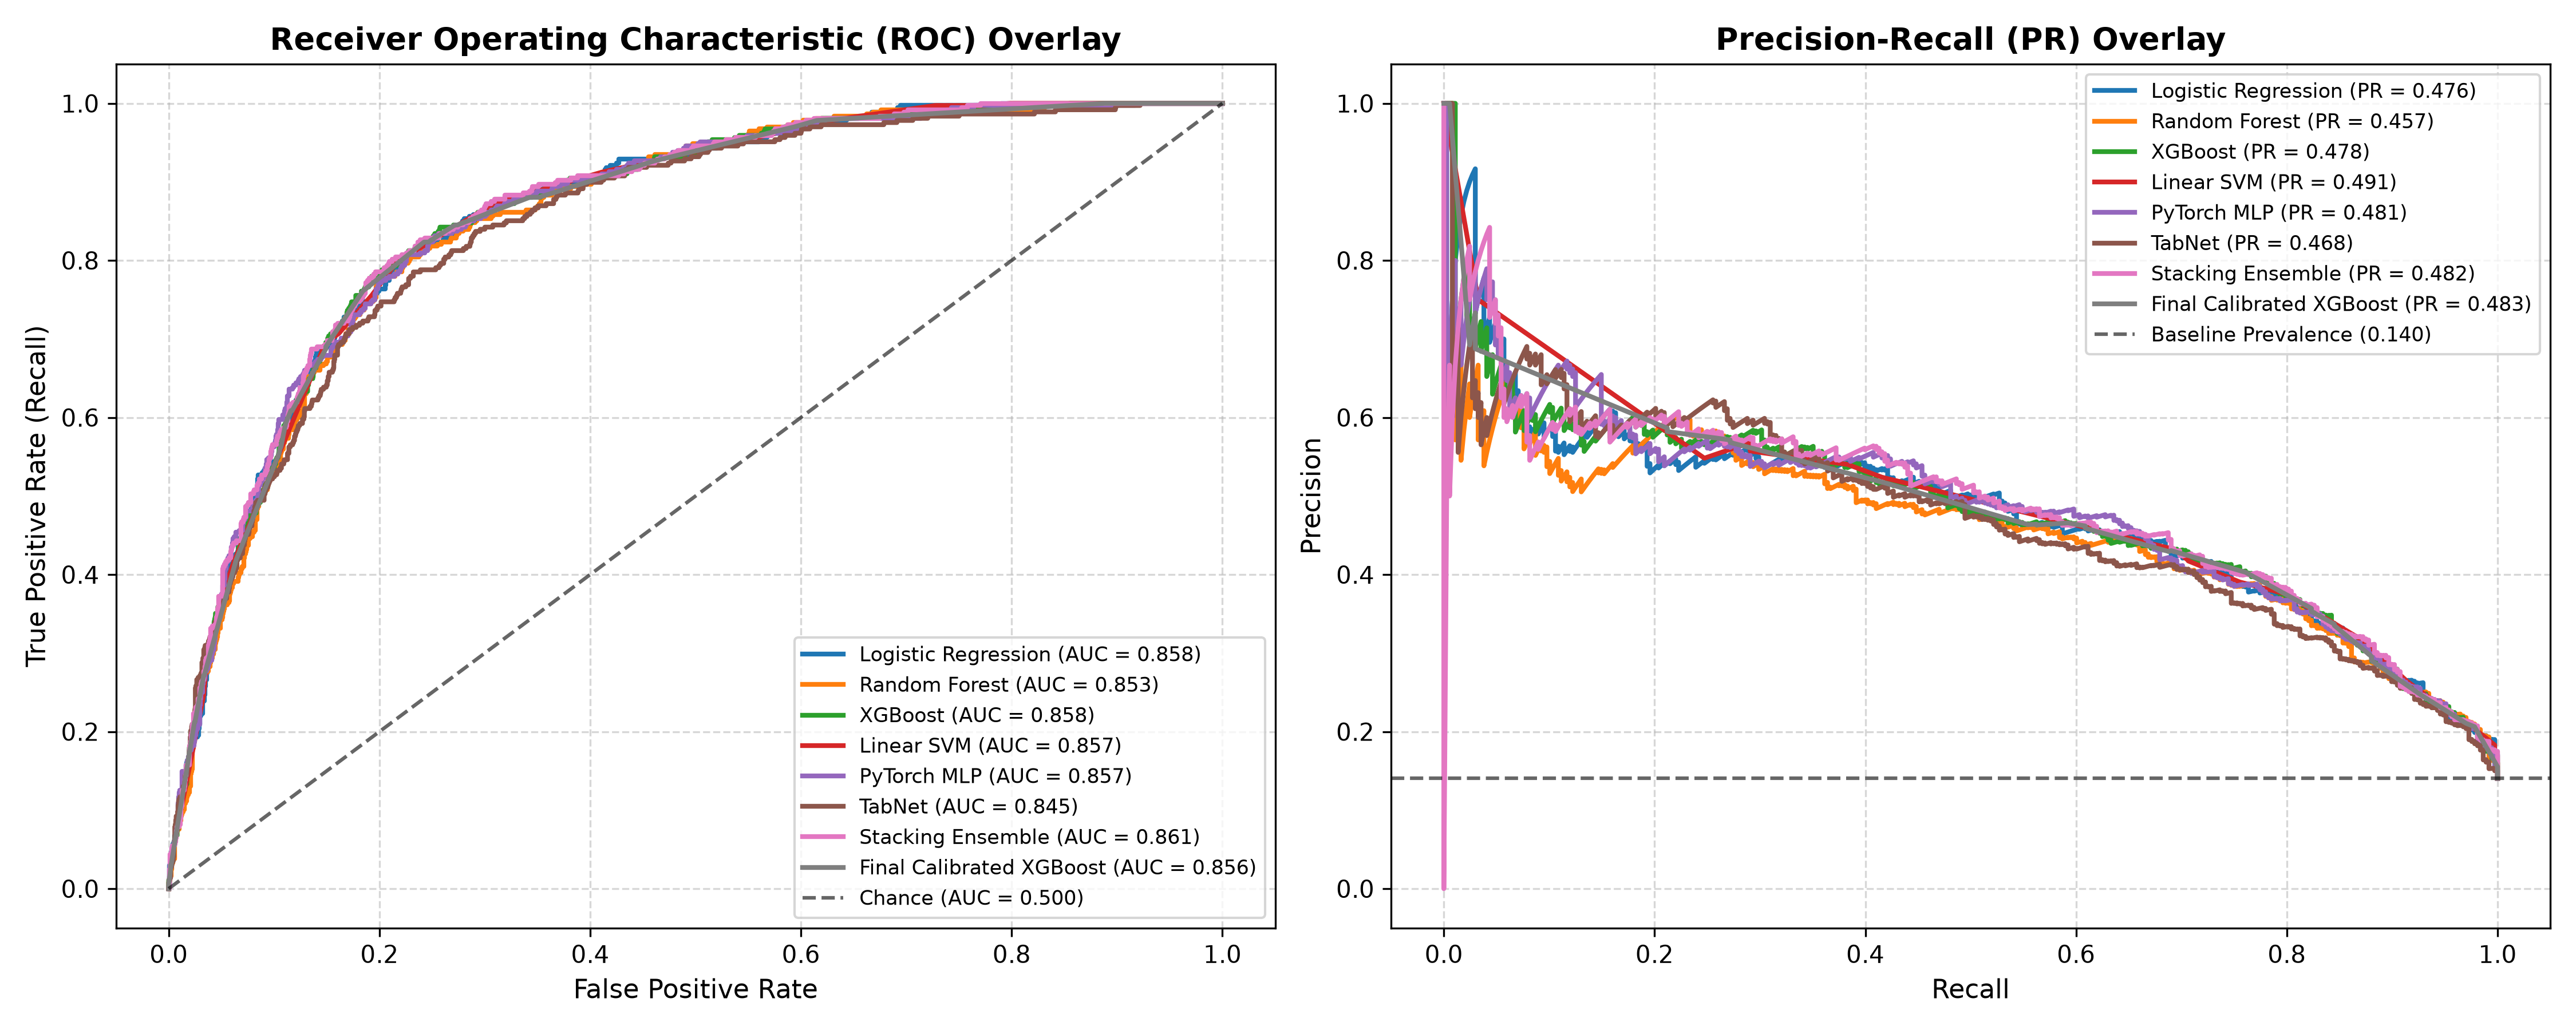

In [6]:
display(Image(filename='../reports/figures/nhanes_all_models_roc_pr.png'))

## 6. Probability Calibration: Before vs. After Calibration
Reliability diagram demonstrating reduction of overconfidence via Isotonic Regression.

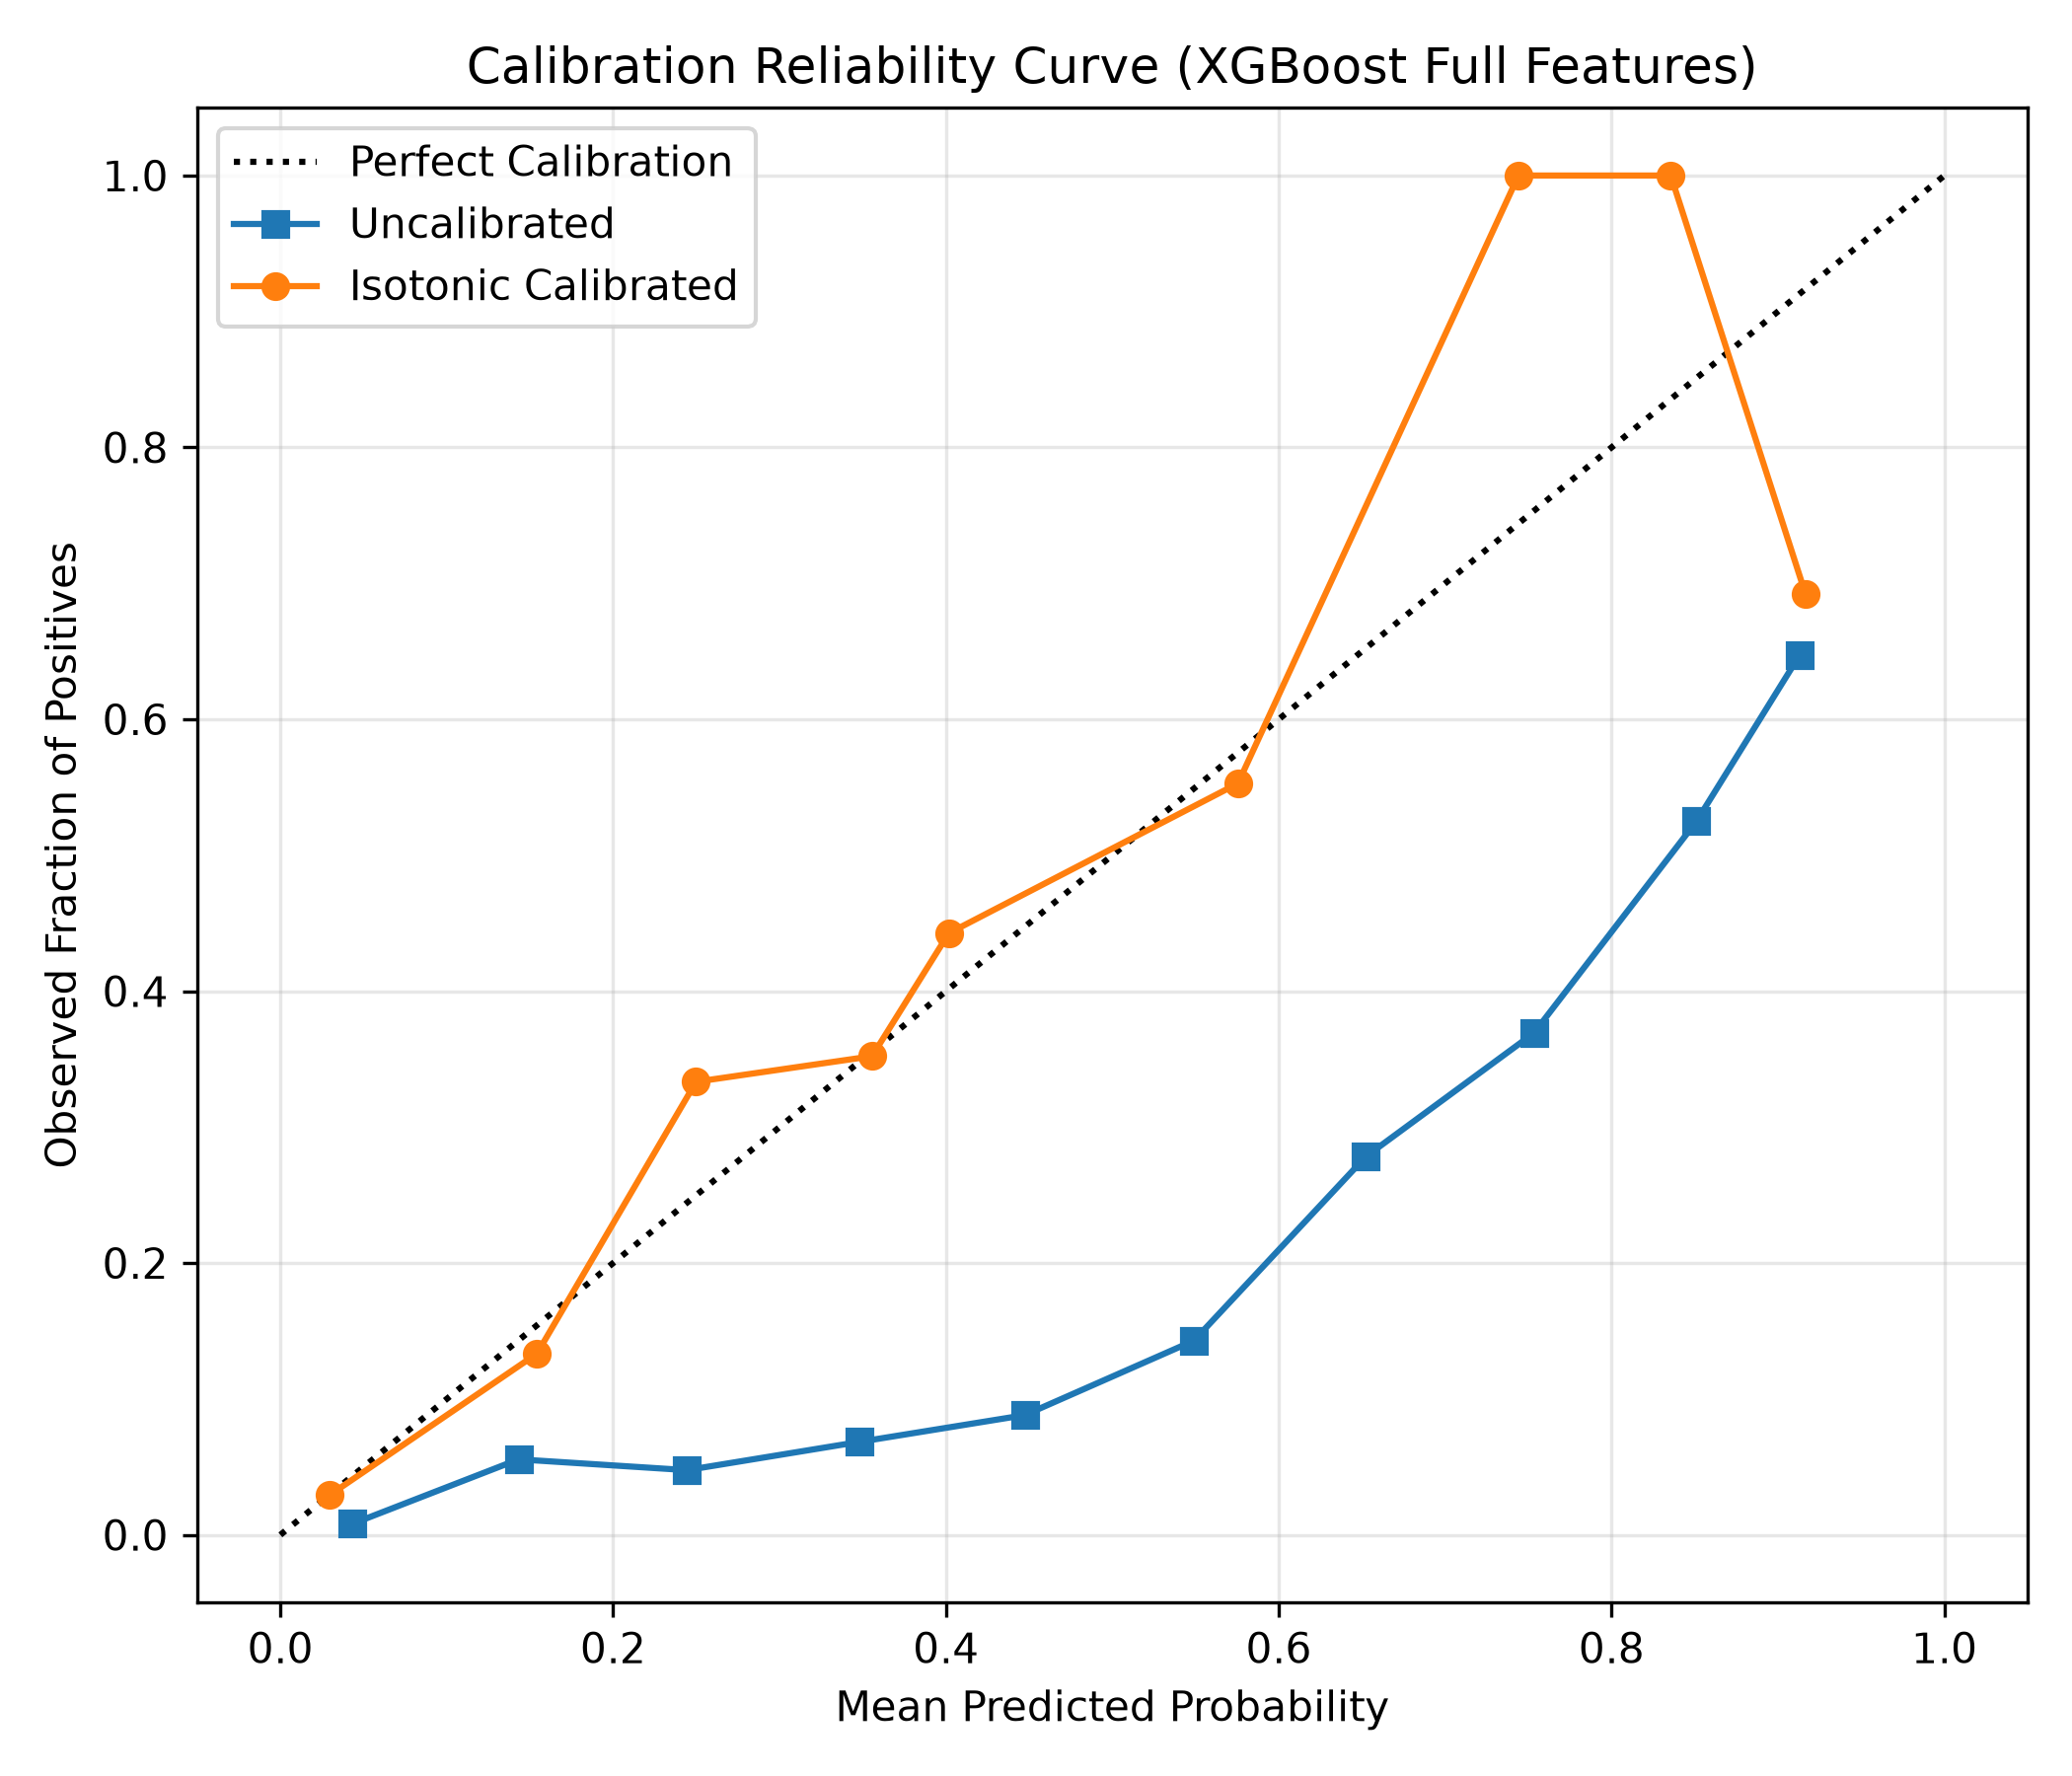

In [7]:
display(Image(filename='../reports/figures/calibration_curve_before_after.png'))

## 7. Deep Learning Section: PyTorch Deep MLP & TabNet Sparse Attention
Neural network architectures, training dynamics, loss convergence, and attention-based feature selection.

=== PyTorch Deep MLP Architecture Specification ===
Input Dimension: 10 non-lab tabular features
Layer 1: Linear(10 -> 64) -> BatchNorm1d(64) -> ReLU() -> Dropout(0.25)
Layer 2: Linear(64 -> 32) -> BatchNorm1d(32) -> ReLU() -> Dropout(0.20)
Layer 3: Linear(32 -> 16) -> ReLU()
Output Layer: Linear(16 -> 1) [BCEWithLogitsLoss with positive weighting = 6.13]
Optimization: Adam (lr=1e-3, weight_decay=1e-4) with validation early stopping



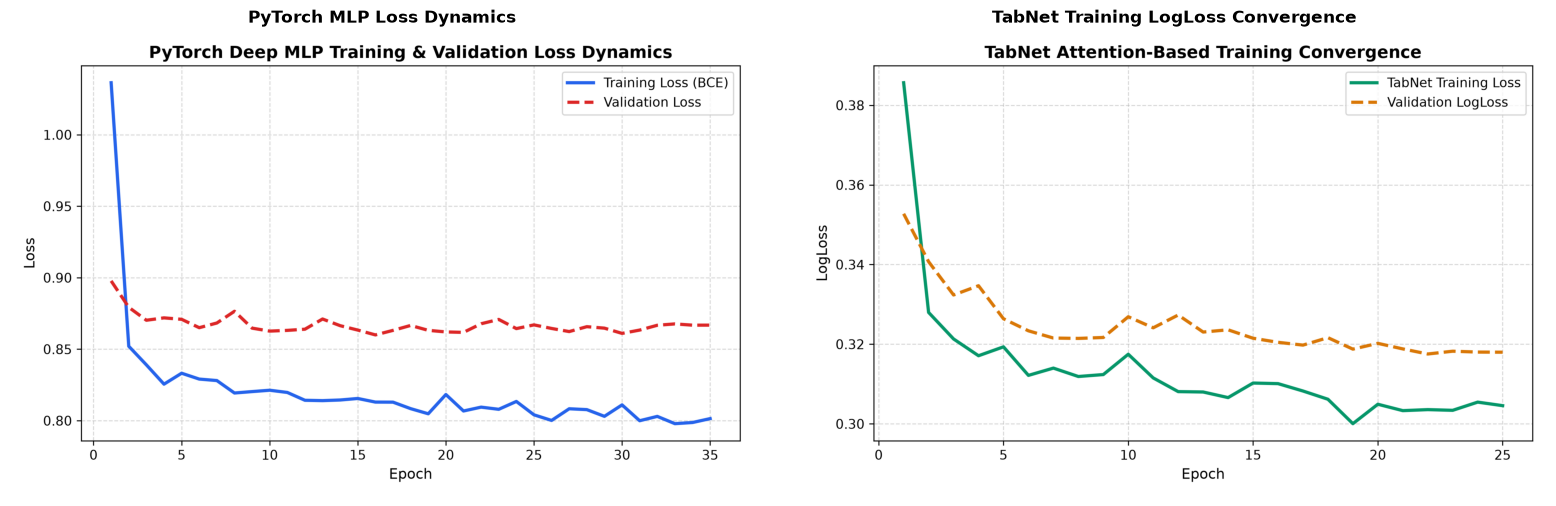


=== TabNet Sparse Attention Feature Importances ===


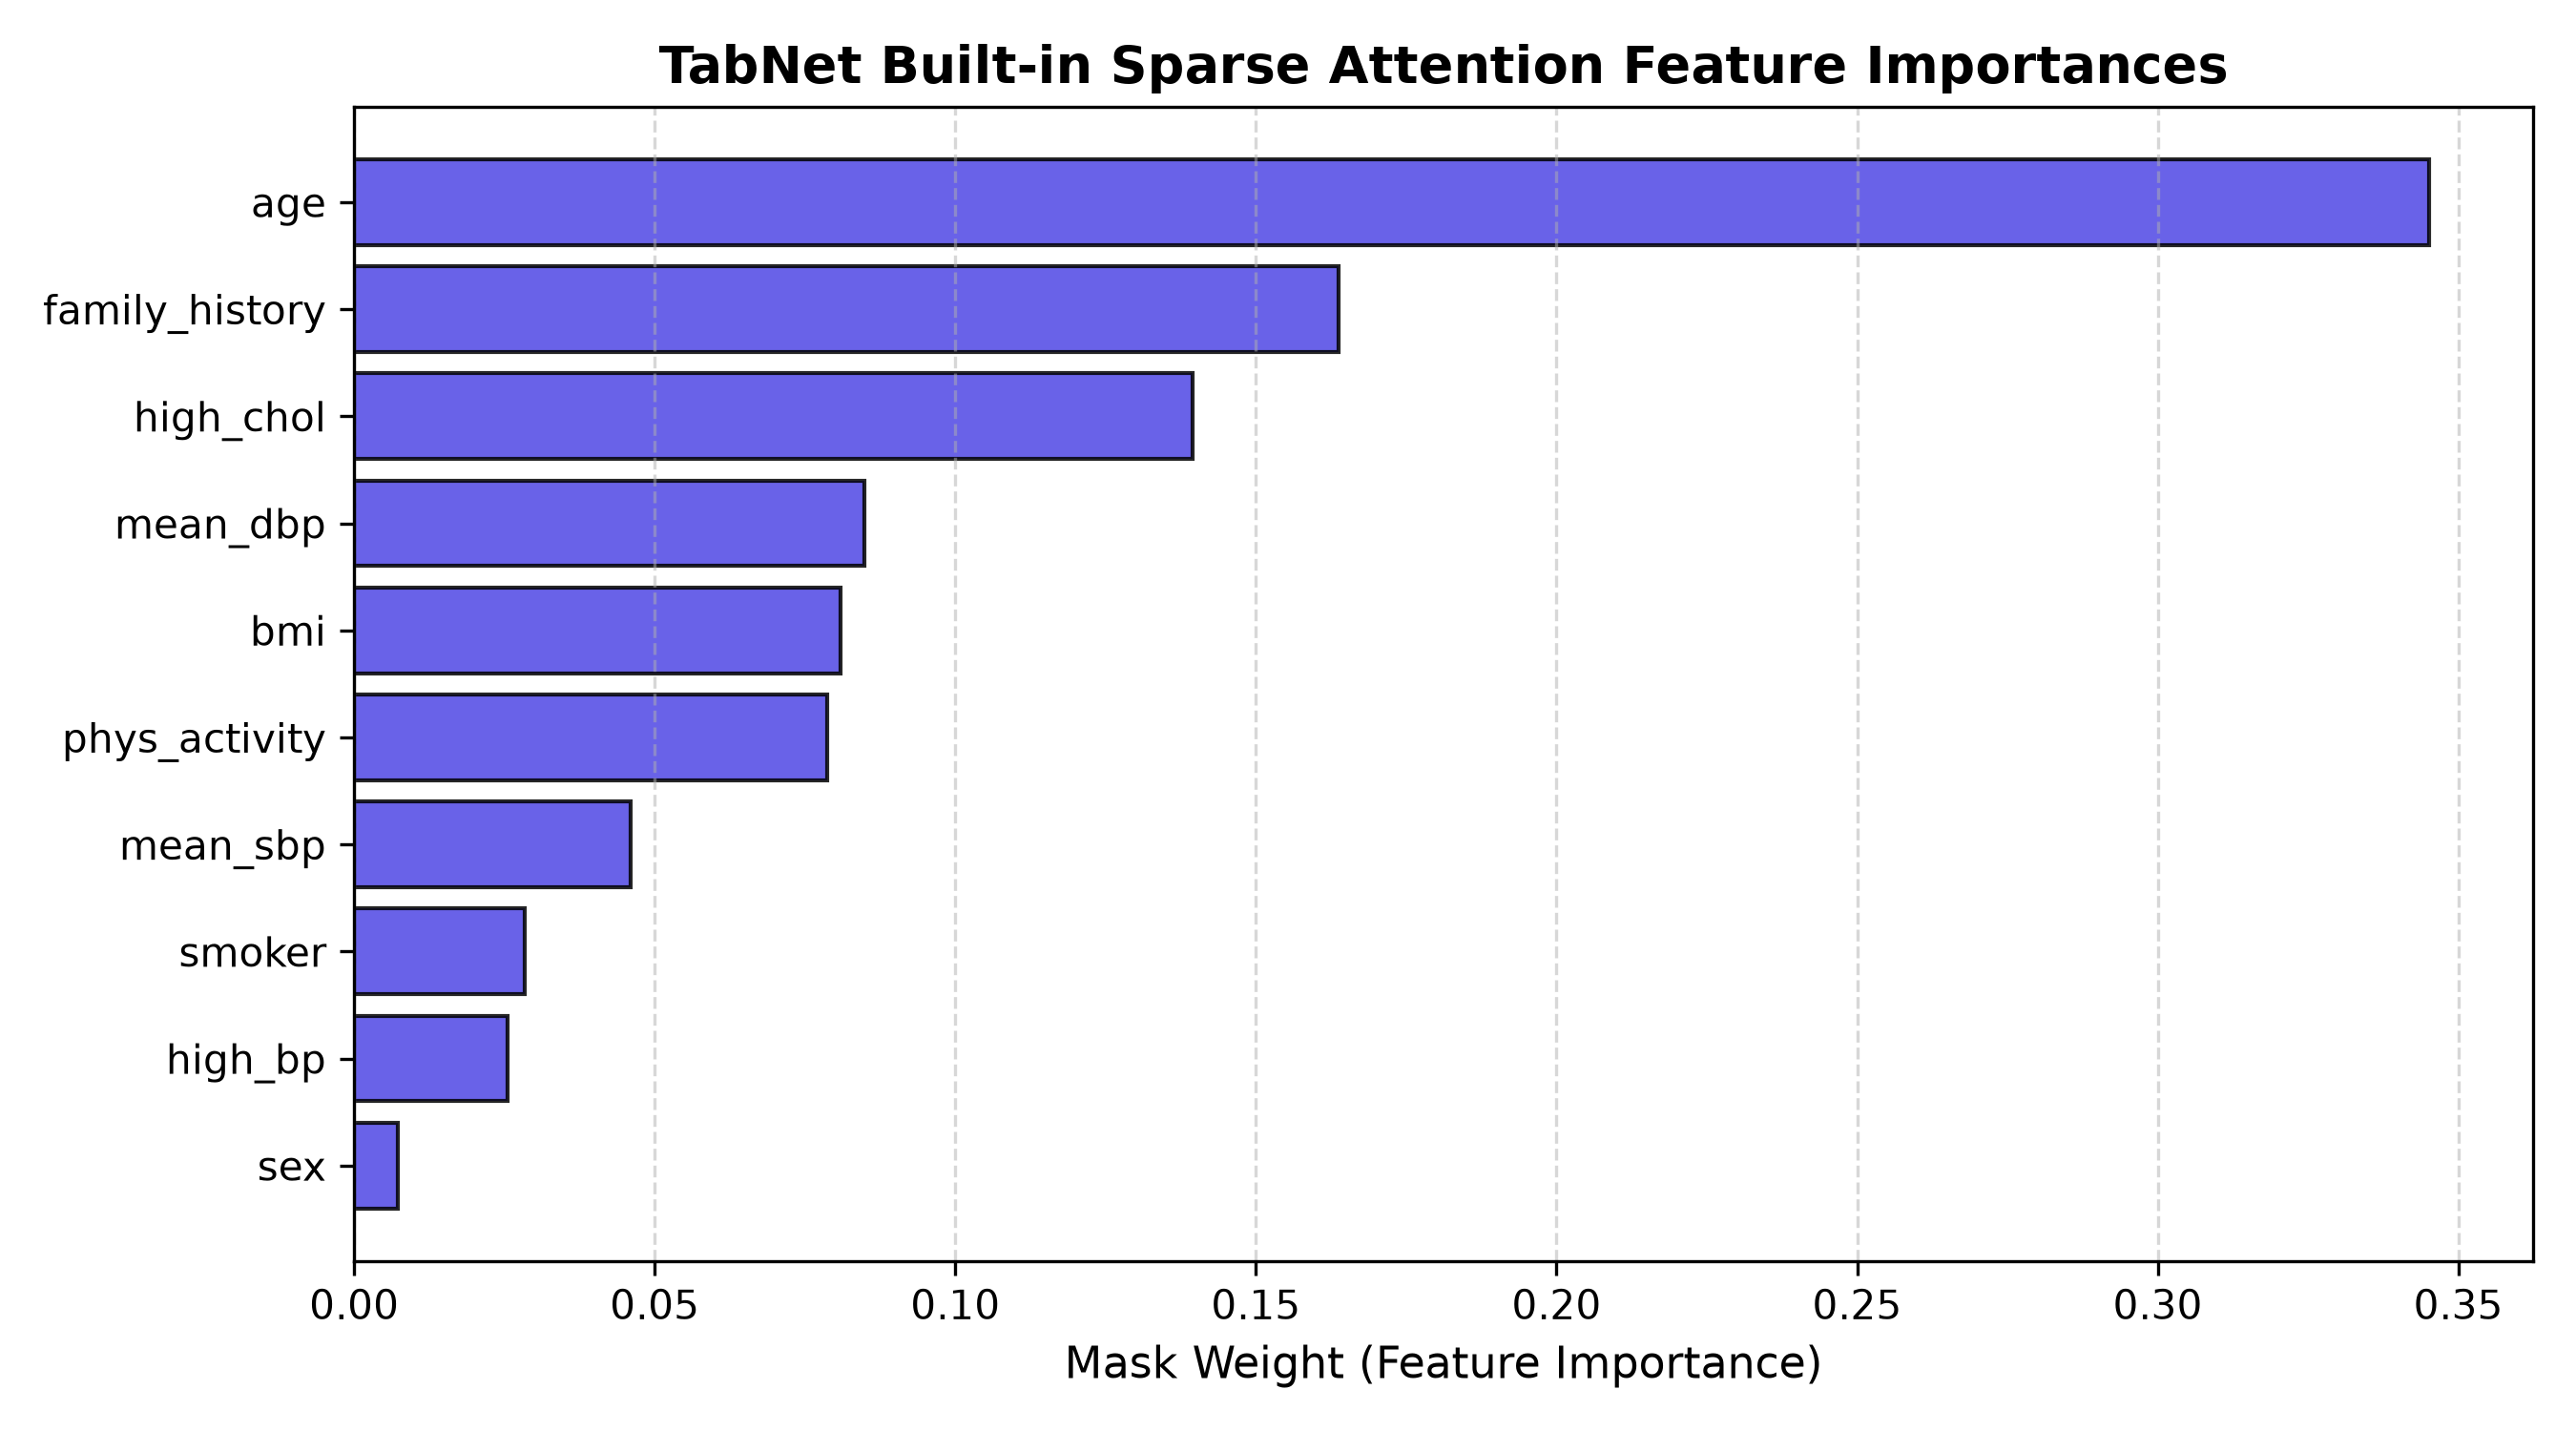

In [8]:
print('=== PyTorch Deep MLP Architecture Specification ===')
print('Input Dimension: 10 non-lab tabular features')
print('Layer 1: Linear(10 -> 64) -> BatchNorm1d(64) -> ReLU() -> Dropout(0.25)')
print('Layer 2: Linear(64 -> 32) -> BatchNorm1d(32) -> ReLU() -> Dropout(0.20)')
print('Layer 3: Linear(32 -> 16) -> ReLU()')
print('Output Layer: Linear(16 -> 1) [BCEWithLogitsLoss with positive weighting = 6.13]')
print('Optimization: Adam (lr=1e-3, weight_decay=1e-4) with validation early stopping\n')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))
img_mlp = PILImage.open('../reports/figures/mlp_training_history.png')
ax1.imshow(img_mlp)
ax1.axis('off')
ax1.set_title('PyTorch MLP Loss Dynamics', fontsize=12, fontweight='bold')

img_tab = PILImage.open('../reports/figures/tabnet_training_history.png')
ax2.imshow(img_tab)
ax2.axis('off')
ax2.set_title('TabNet Training LogLoss Convergence', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

print('\n=== TabNet Sparse Attention Feature Importances ===')
display(Image(filename='../reports/figures/tabnet_feature_importances.png'))

## 8. External Validation: CDC BRFSS 2015 ($N = 249,049$)
Assessing generalizability and domain shift on an independent nationwide telephone survey.

Model,Accuracy,Balanced Acc,Precision,Recall,F1,ROC-AUC,PR-AUC,Brier
Logistic Regression (Shared),0.735 [0.718-0.752],0.766,0.323,0.810 [0.767-0.849],0.462,0.830 [0.809-0.849],0.407 [0.359-0.461],0.177
Random Forest (Shared),0.722 [0.705-0.739],0.761,0.312,0.815 [0.772-0.853],0.452,0.829 [0.808-0.848],0.412 [0.364-0.468],0.169
XGBoost (Shared),0.707 [0.689-0.723],0.769,0.306,0.856 [0.819-0.890],0.450,0.838 [0.816-0.857],0.447 [0.395-0.503],0.174
"SVM (Linear, Shared)",0.860 [0.846-0.873],0.501,1.000,0.003 [0.000-0.009],0.005,0.829 [0.808-0.848],0.382 [0.341-0.427],0.099
"MLP (PyTorch, Shared)",0.699 [0.682-0.716],0.771,0.302,0.870 [0.833-0.901],0.448,0.839 [0.818-0.857],0.430 [0.381-0.487],0.181
TabNet (Shared),0.865 [0.852-0.877],0.539,0.627,0.087 [0.060-0.118],0.153,0.821 [0.799-0.841],0.418 [0.368-0.469],0.099
Stacking Ensemble (Shared),0.864 [0.850-0.877],0.522,0.773,0.046 [0.026-0.069],0.087,0.838 [0.817-0.856],0.434 [0.381-0.489],0.097
Final Calibrated XGB (Shared),0.675 [0.657-0.693],0.763,0.287,0.886 [0.852-0.917],0.433,0.838 [0.816-0.856],0.425 [0.377-0.475],0.096


Model,Accuracy,Balanced Acc,Precision,Recall,F1,ROC-AUC,PR-AUC,Brier
Logistic Regression (Shared),0.630 [0.623-0.637],0.714,0.254,0.832 [0.819-0.846],0.390,0.784 [0.776-0.793],0.347 [0.330-0.366],0.231
Random Forest (Shared),0.632 [0.625-0.638],0.711,0.254,0.821 [0.808-0.835],0.388,0.784 [0.776-0.792],0.362 [0.344-0.380],0.218
XGBoost (Shared),0.599 [0.593-0.606],0.709,0.243,0.861 [0.849-0.873],0.379,0.790 [0.782-0.798],0.374 [0.355-0.394],0.231
"SVM (Linear, Shared)",0.858 [0.853-0.863],0.502,0.390,0.004 [0.002-0.007],0.008,0.778 [0.769-0.786],0.317 [0.302-0.331],0.109
"MLP (PyTorch, Shared)",0.587 [0.580-0.594],0.707,0.239,0.876 [0.864-0.887],0.376,0.792 [0.784-0.800],0.373 [0.356-0.393],0.239
TabNet (Shared),0.858 [0.853-0.863],0.536,0.503,0.087 [0.076-0.098],0.148,0.780 [0.772-0.789],0.353 [0.336-0.371],0.109
Stacking Ensemble (Shared),0.860 [0.855-0.865],0.520,0.587,0.045 [0.037-0.052],0.084,0.792 [0.784-0.800],0.373 [0.355-0.393],0.106
Final Calibrated XGB (Shared),0.546 [0.539-0.553],0.694,0.225,0.900 [0.889-0.911],0.360,0.788 [0.780-0.796],0.355 [0.339-0.373],0.106


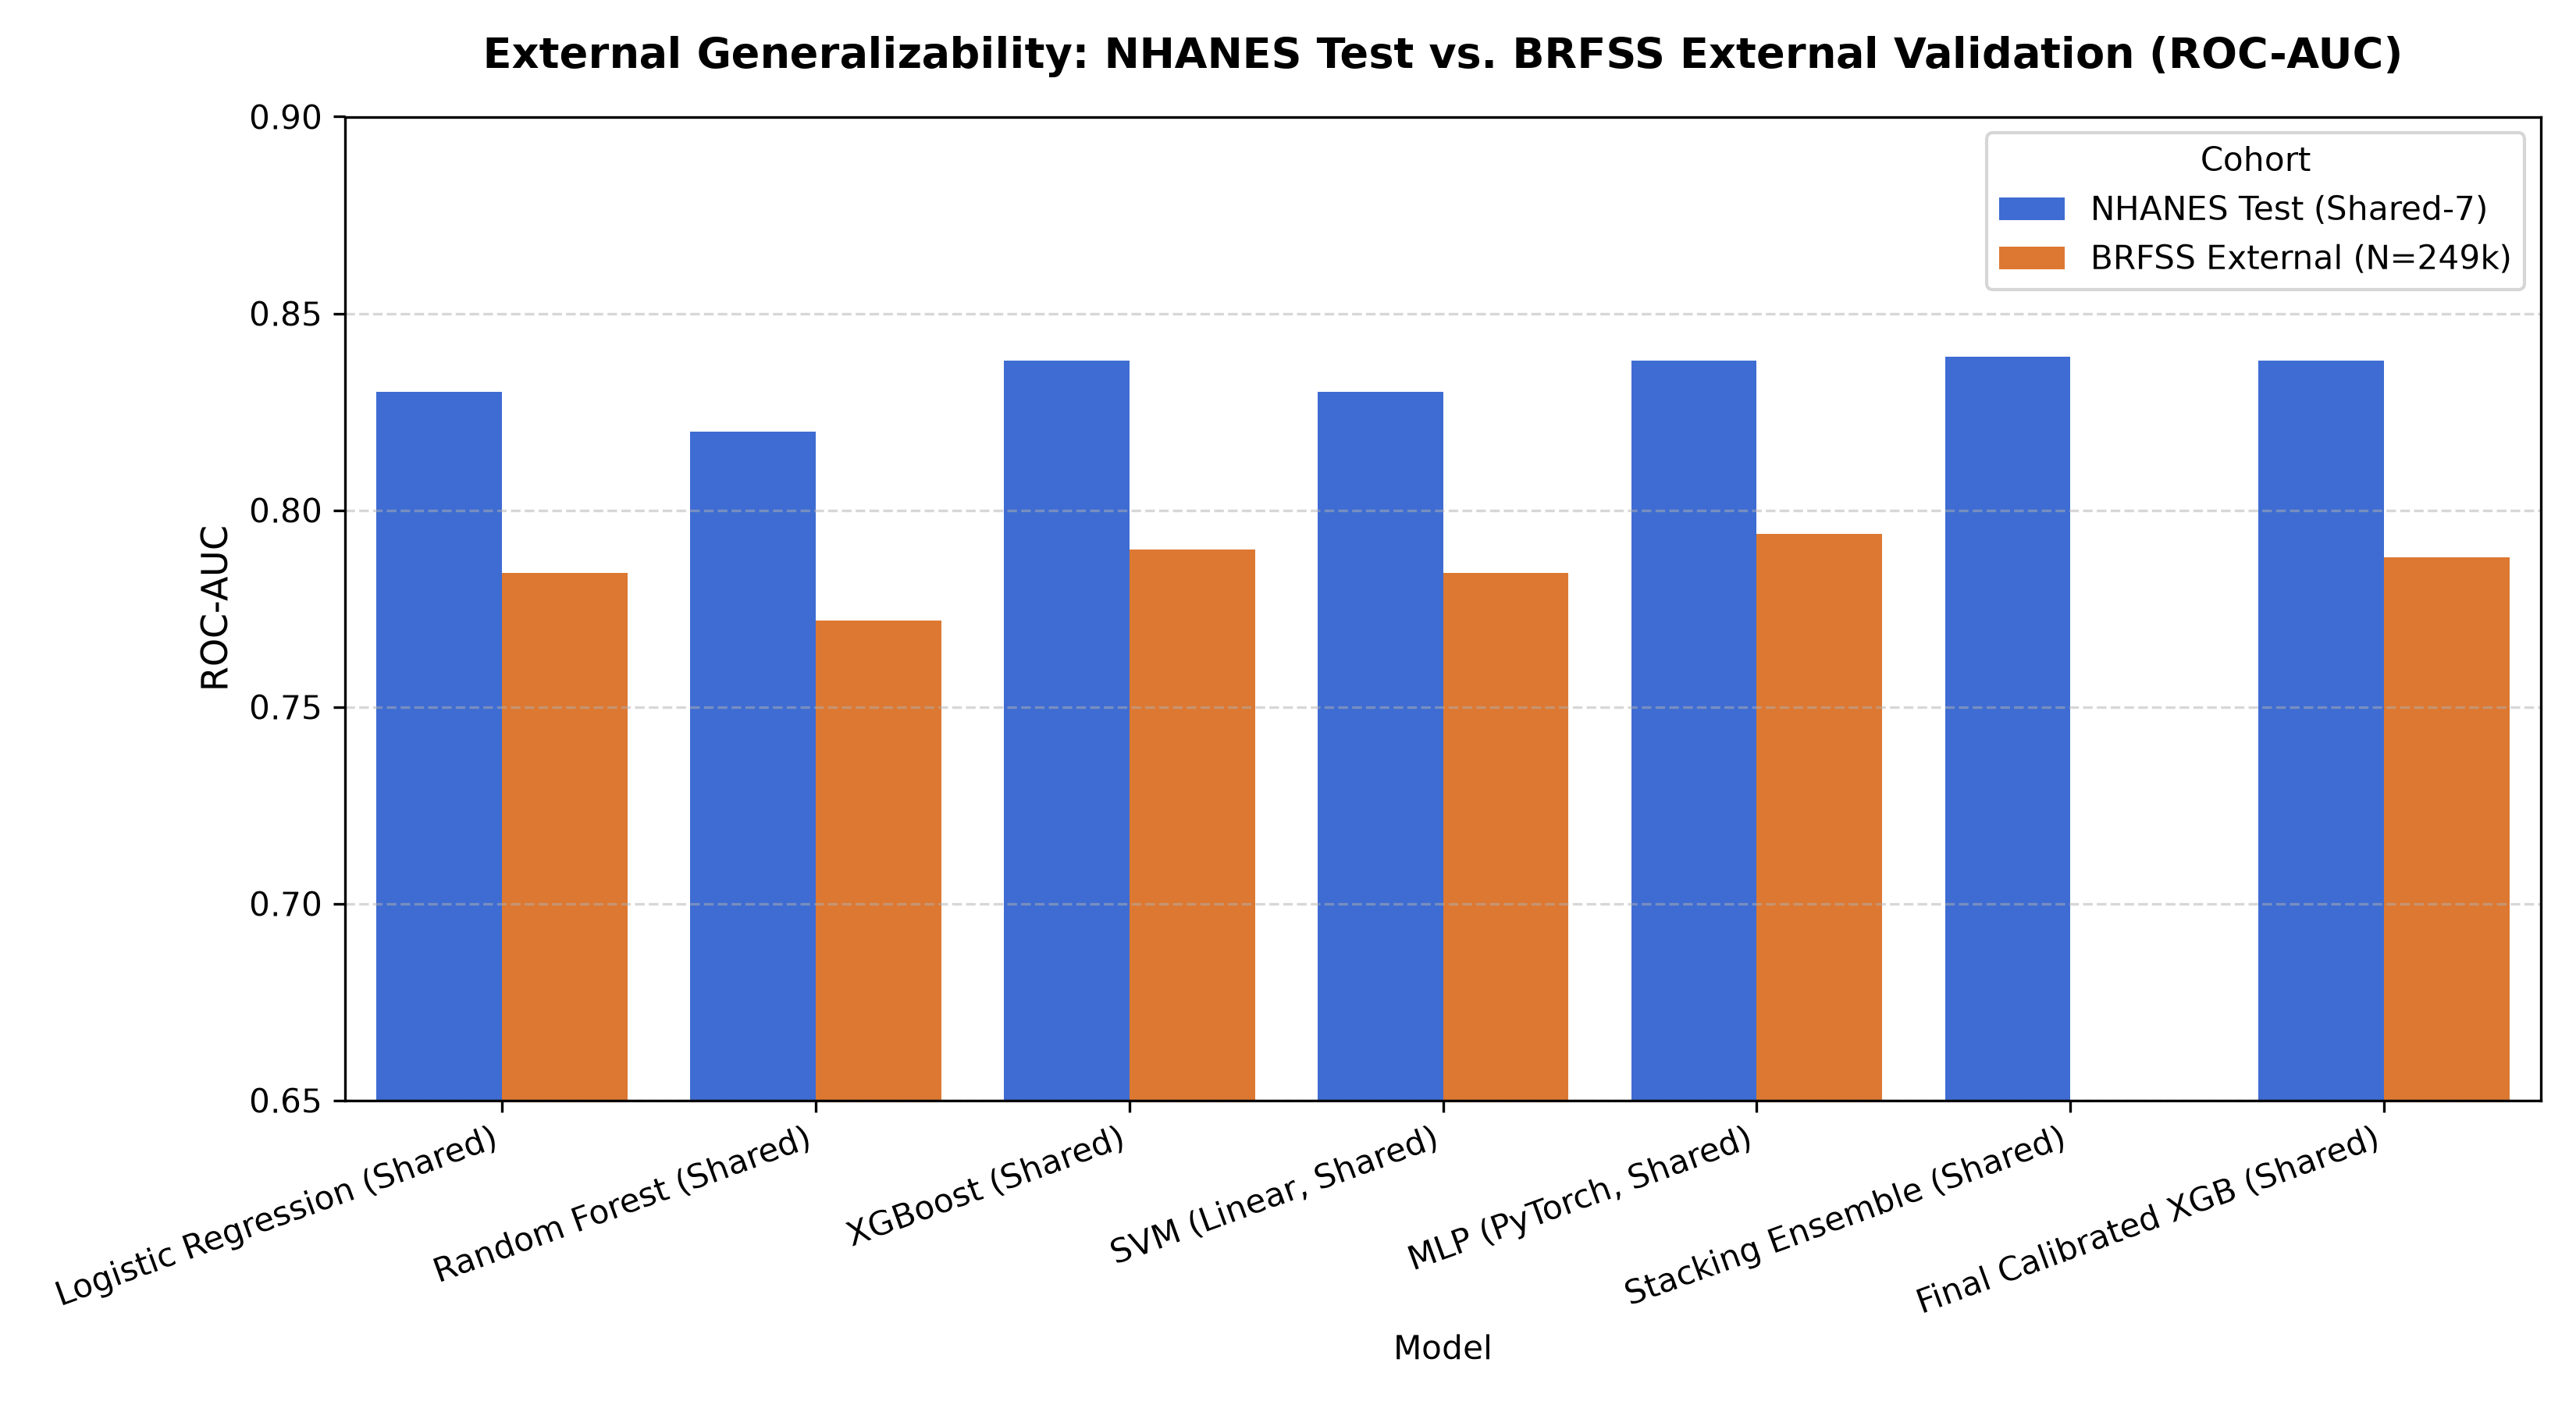

In [9]:
# 8.1 Shared-7 Features Comparison: NHANES Held-Out Test vs CDC BRFSS 2015
nhanes_shared_table = pd.read_csv('../reports/tables/nhanes_shared_test_comparison.csv')
display(HTML('<h4>Table 8.1a: NHANES Held-Out Test Set Performance (Shared-7 Features, N=2,621)</h4>'))
display(HTML(nhanes_shared_table.to_html(index=False, classes='table table-bordered table-striped')))

brfss_table = pd.read_csv('../reports/tables/brfss_external_validation_comparison.csv')
display(HTML('<h4>Table 8.1b: External Validation Metrics (CDC BRFSS 2015, N=249,049)</h4>'))
display(HTML(brfss_table.to_html(index=False, classes='table table-bordered table-striped')))

display(Image(filename='../reports/figures/nhanes_vs_brfss_comparison.png'))


## 8.2 Common Operating Point Evaluation (Targeting 80% Validation Recall)
In preventive health screening, setting a standard operating point across models ensures fair clinical comparison.
Thresholds $\\tau_{80}$ are calibrated strictly on the validation partition to achieve $\\ge 80\\%$ recall, and then evaluated on both the **NHANES test set** and the external **CDC BRFSS cohort** with 95% bootstrap confidence intervals (1,000 resamples).

In [10]:
cop_table = pd.read_csv('../reports/tables/common_operating_point_comparison.csv')
display(HTML('<h4>Table 8.2: Common Operating Point Metrics (Threshold Selected on Validation for >= 80% Recall)</h4>'))
display(HTML(cop_table.to_html(index=False, classes='table table-bordered table-hover table-striped')))


Model,NHANES Threshold,NHANES Precision,NHANES Specificity,NHANES Recall,NHANES F1,NHANES Accuracy,BRFSS Threshold,BRFSS Precision,BRFSS Specificity,BRFSS Recall,BRFSS F1,BRFSS Accuracy
Logistic Regression,0.473,0.332 [0.302-0.364],0.725 [0.706-0.744],0.837 [0.798-0.873],0.475 [0.443-0.510],0.741 [0.724-0.758],0.458,0.241 [0.232-0.249],0.548 [0.541-0.555],0.866 [0.854-0.878],0.377 [0.366-0.388],0.593 [0.587-0.600]
Random Forest,0.352,0.333 [0.303-0.363],0.728 [0.710-0.746],0.829 [0.791-0.866],0.475 [0.442-0.508],0.742 [0.726-0.760],0.432,0.236 [0.228-0.245],0.532 [0.524-0.539],0.874 [0.862-0.886],0.372 [0.362-0.383],0.580 [0.573-0.587]
XGBoost,0.499,0.351 [0.318-0.383],0.751 [0.732-0.768],0.826 [0.785-0.861],0.493 [0.456-0.528],0.762 [0.744-0.776],0.485,0.239 [0.230-0.248],0.541 [0.533-0.548],0.871 [0.858-0.882],0.375 [0.364-0.386],0.588 [0.581-0.594]
Linear SVM,0.155,0.375 [0.341-0.408],0.783 [0.765-0.799],0.799 [0.758-0.839],0.510 [0.474-0.544],0.785 [0.769-0.800],0.122,0.243 [0.235-0.252],0.558 [0.551-0.565],0.859 [0.846-0.871],0.379 [0.368-0.391],0.601 [0.594-0.608]
PyTorch MLP,0.527,0.349 [0.317-0.380],0.742 [0.724-0.761],0.848 [0.811-0.883],0.495 [0.459-0.527],0.757 [0.740-0.774],0.523,0.244 [0.236-0.253],0.558 [0.550-0.565],0.865 [0.853-0.877],0.381 [0.370-0.392],0.601 [0.594-0.608]
TabNet,0.159,0.328 [0.297-0.360],0.728 [0.710-0.747],0.812 [0.773-0.852],0.468 [0.434-0.501],0.740 [0.723-0.757],0.147,0.226 [0.218-0.234],0.500 [0.492-0.507],0.883 [0.871-0.895],0.360 [0.349-0.371],0.554 [0.548-0.561]
Stacking Ensemble,0.138,0.344 [0.311-0.375],0.742 [0.723-0.760],0.826 [0.785-0.863],0.485 [0.449-0.520],0.754 [0.737-0.770],0.128,0.242 [0.234-0.251],0.550 [0.542-0.557],0.870 [0.858-0.882],0.379 [0.368-0.390],0.595 [0.588-0.602]
Final Calibrated XGBoost,0.144,0.353 [0.320-0.385],0.753 [0.734-0.771],0.823 [0.782-0.860],0.494 [0.458-0.529],0.763 [0.747-0.778],0.155,0.238 [0.229-0.246],0.536 [0.529-0.544],0.874 [0.861-0.885],0.374 [0.363-0.385],0.584 [0.577-0.591]


## 9. Model Interpretability & Explainability (TreeSHAP & LIME)
Global feature attribution ranking, local patient waterfall explanations, and surrogate LIME comparisons.

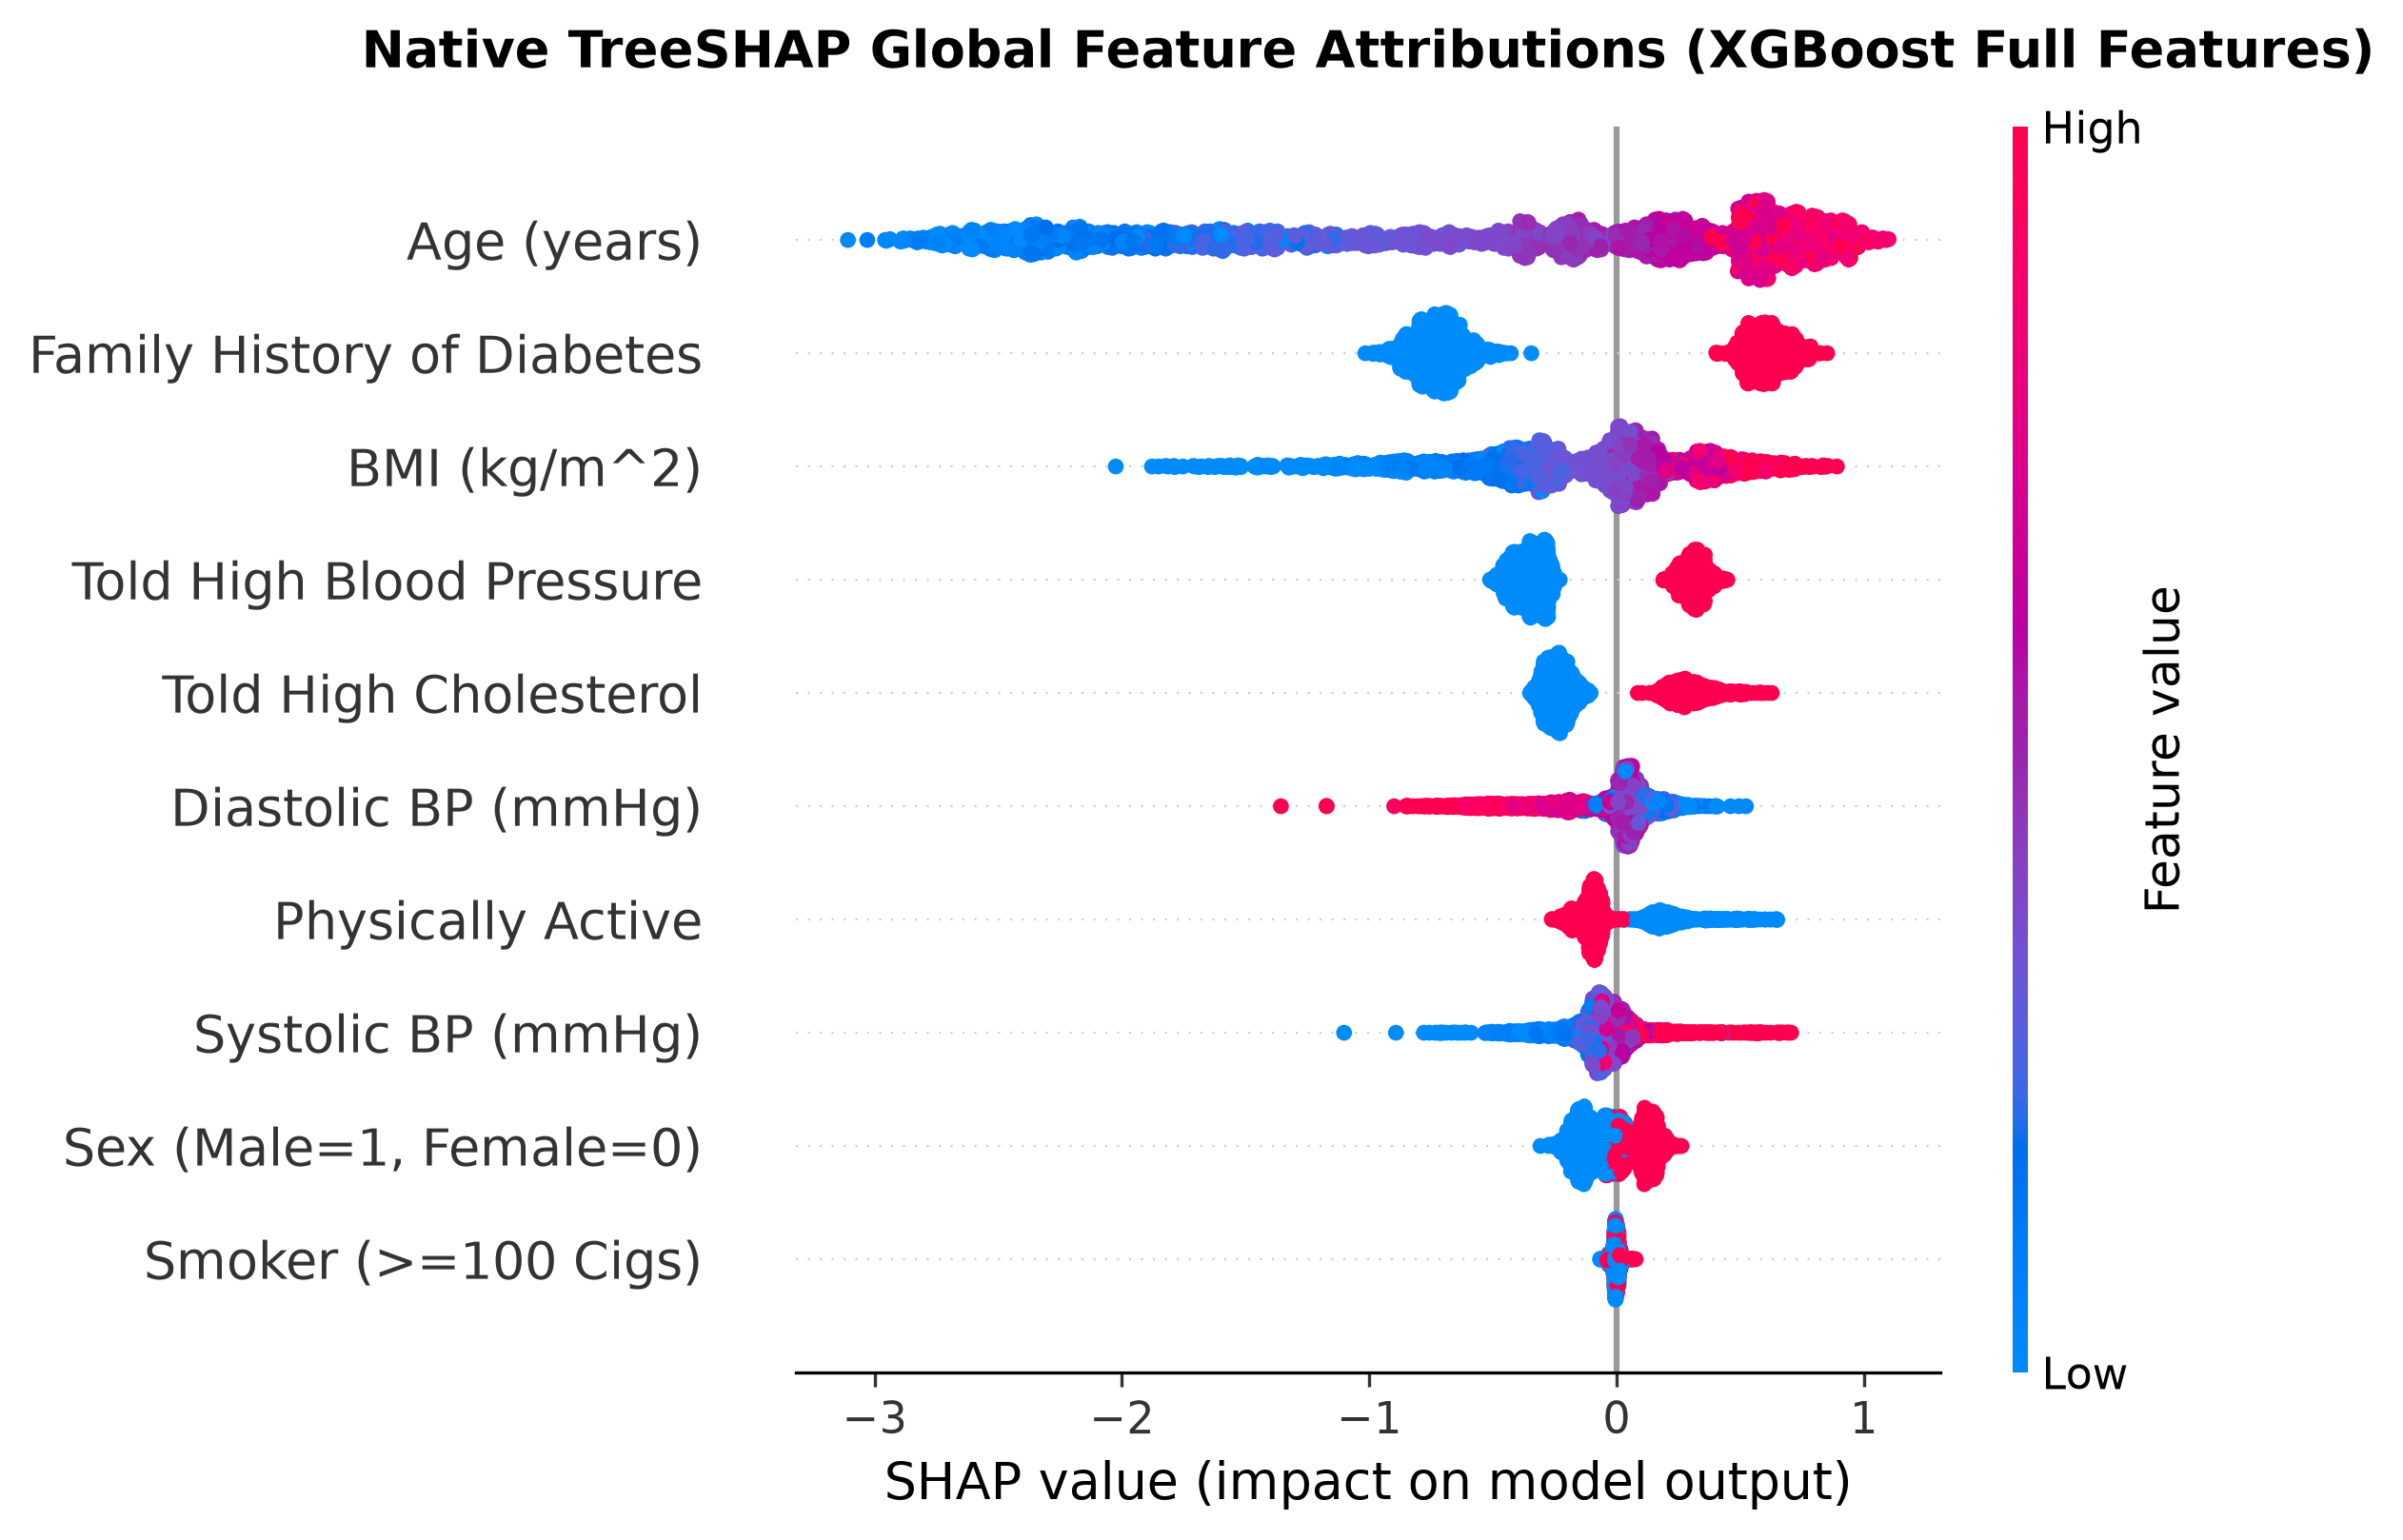

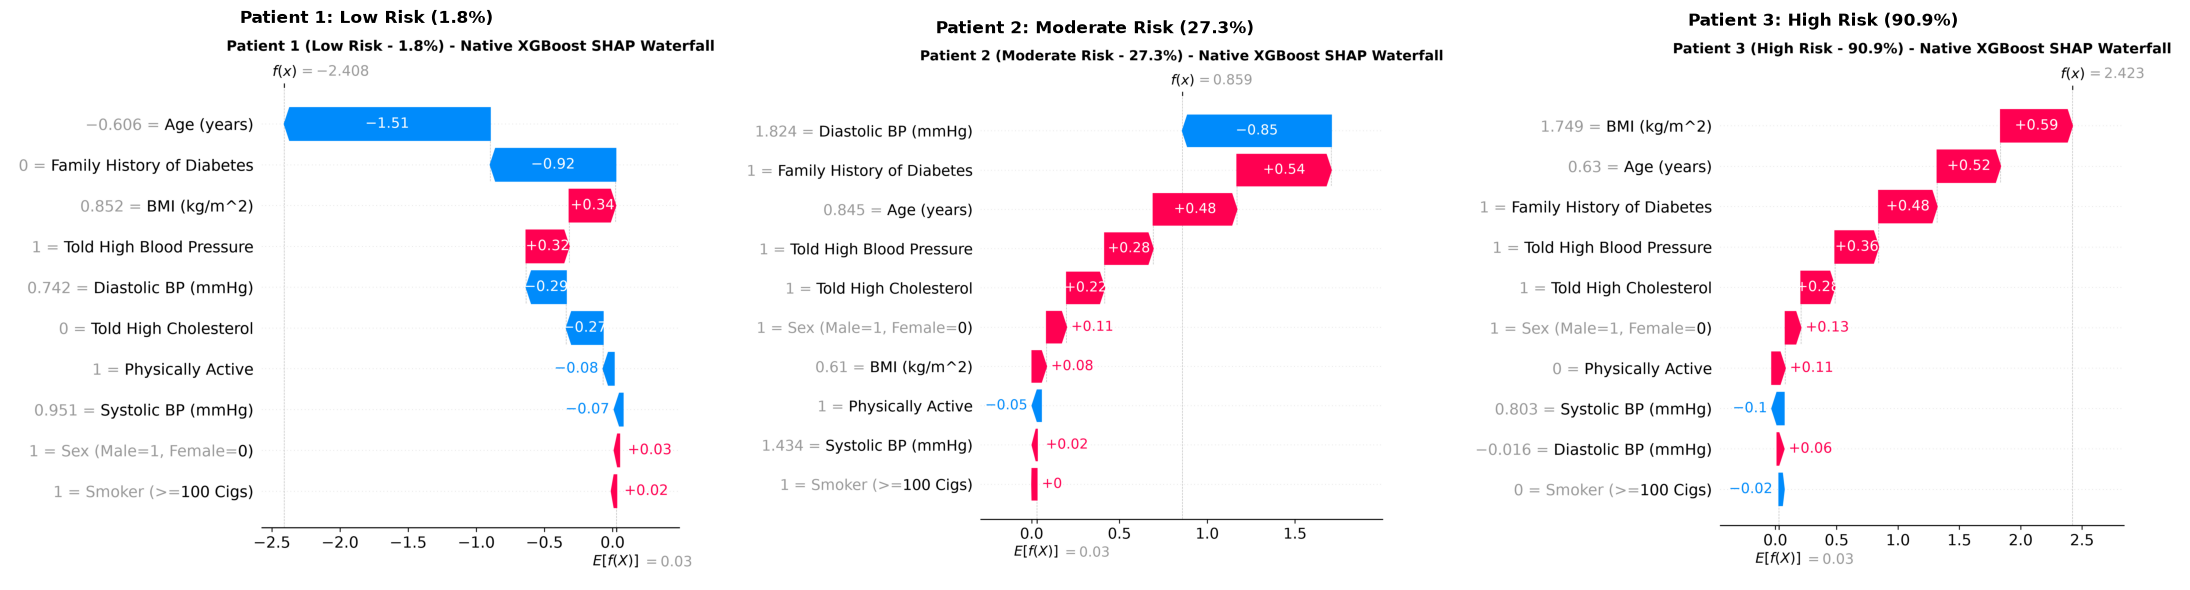

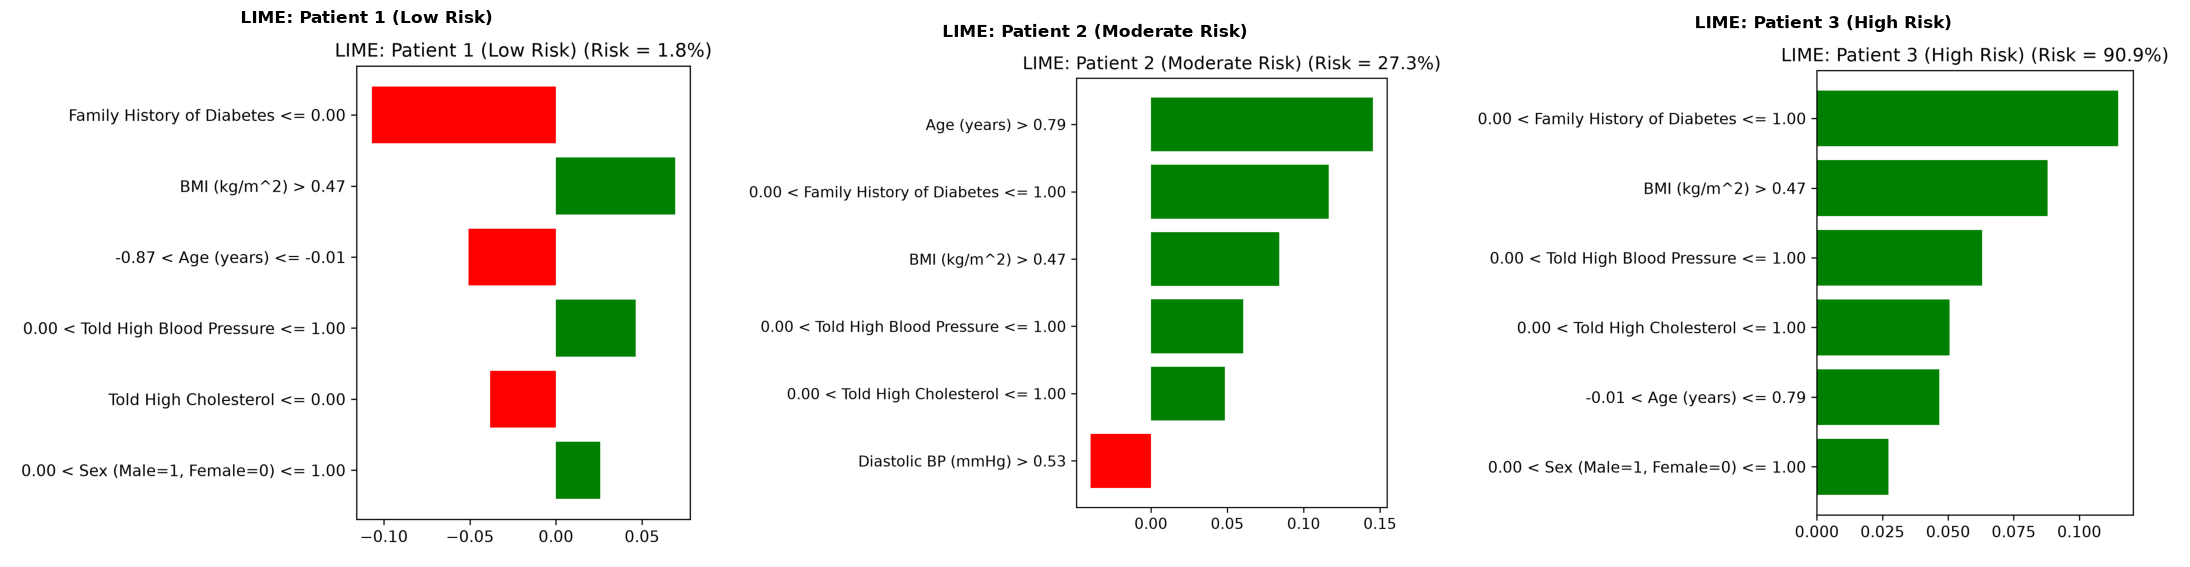

In [11]:
display(HTML('<h3>9.1 Global TreeSHAP Feature Attributions</h3>'))
display(Image(filename='../reports/figures/shap_summary.png'))

display(HTML('<h3>9.2 Patient-Level SHAP Waterfall Explanations (Low, Moderate, High Risk)</h3>'))
fig, axes = plt.subplots(1, 3, figsize=(22, 6))
for idx, (p_name, title) in enumerate([
    ('shap_patient_1_low_risk.png', 'Patient 1: Low Risk (1.8%)'),
    ('shap_patient_2_moderate_risk.png', 'Patient 2: Moderate Risk (27.3%)'),
    ('shap_patient_3_high_risk.png', 'Patient 3: High Risk (90.9%)')
]):
    im = PILImage.open(f'../reports/figures/{p_name}')
    axes[idx].imshow(im)
    axes[idx].axis('off')
    axes[idx].set_title(title, fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

display(HTML('<h3>9.3 Patient-Level LIME Surrogate Explanations</h3>'))
fig, axes = plt.subplots(1, 3, figsize=(22, 6))
for idx, (l_name, title) in enumerate([
    ('lime_patient_1.png', 'LIME: Patient 1 (Low Risk)'),
    ('lime_patient_2.png', 'LIME: Patient 2 (Moderate Risk)'),
    ('lime_patient_3.png', 'LIME: Patient 3 (High Risk)')
]):
    im = PILImage.open(f'../reports/figures/{l_name}')
    axes[idx].imshow(im)
    axes[idx].axis('off')
    axes[idx].set_title(title, fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

with open('../reports/tables/shap_lime_comparison.md', 'r') as f:
    display(HTML(f"<div style='background-color:#F8FAFC; padding:15px; border-left:4px solid #3B82F6;'>{f.read()}</div>"))

## 10. Clinical Decision Thresholds & Risk Level Stratification
Distribution across Low, Moderate, and High clinical tiers and observed diabetes incidence.

Optimal Decision Screening Threshold: 0.140
Low Risk Tier Cut-off:      < 0.15
Moderate Risk Tier Cut-off: 0.15 to 0.40
High Risk Tier Cut-off:     >= 0.40



Risk Tier Level,Test Patients (N),Share of Test Cohort,Observed Diabetes Rate
Low,1762,67.23%,3.69%
Moderate,561,21.40%,26.56%
High,298,11.37%,51.68%


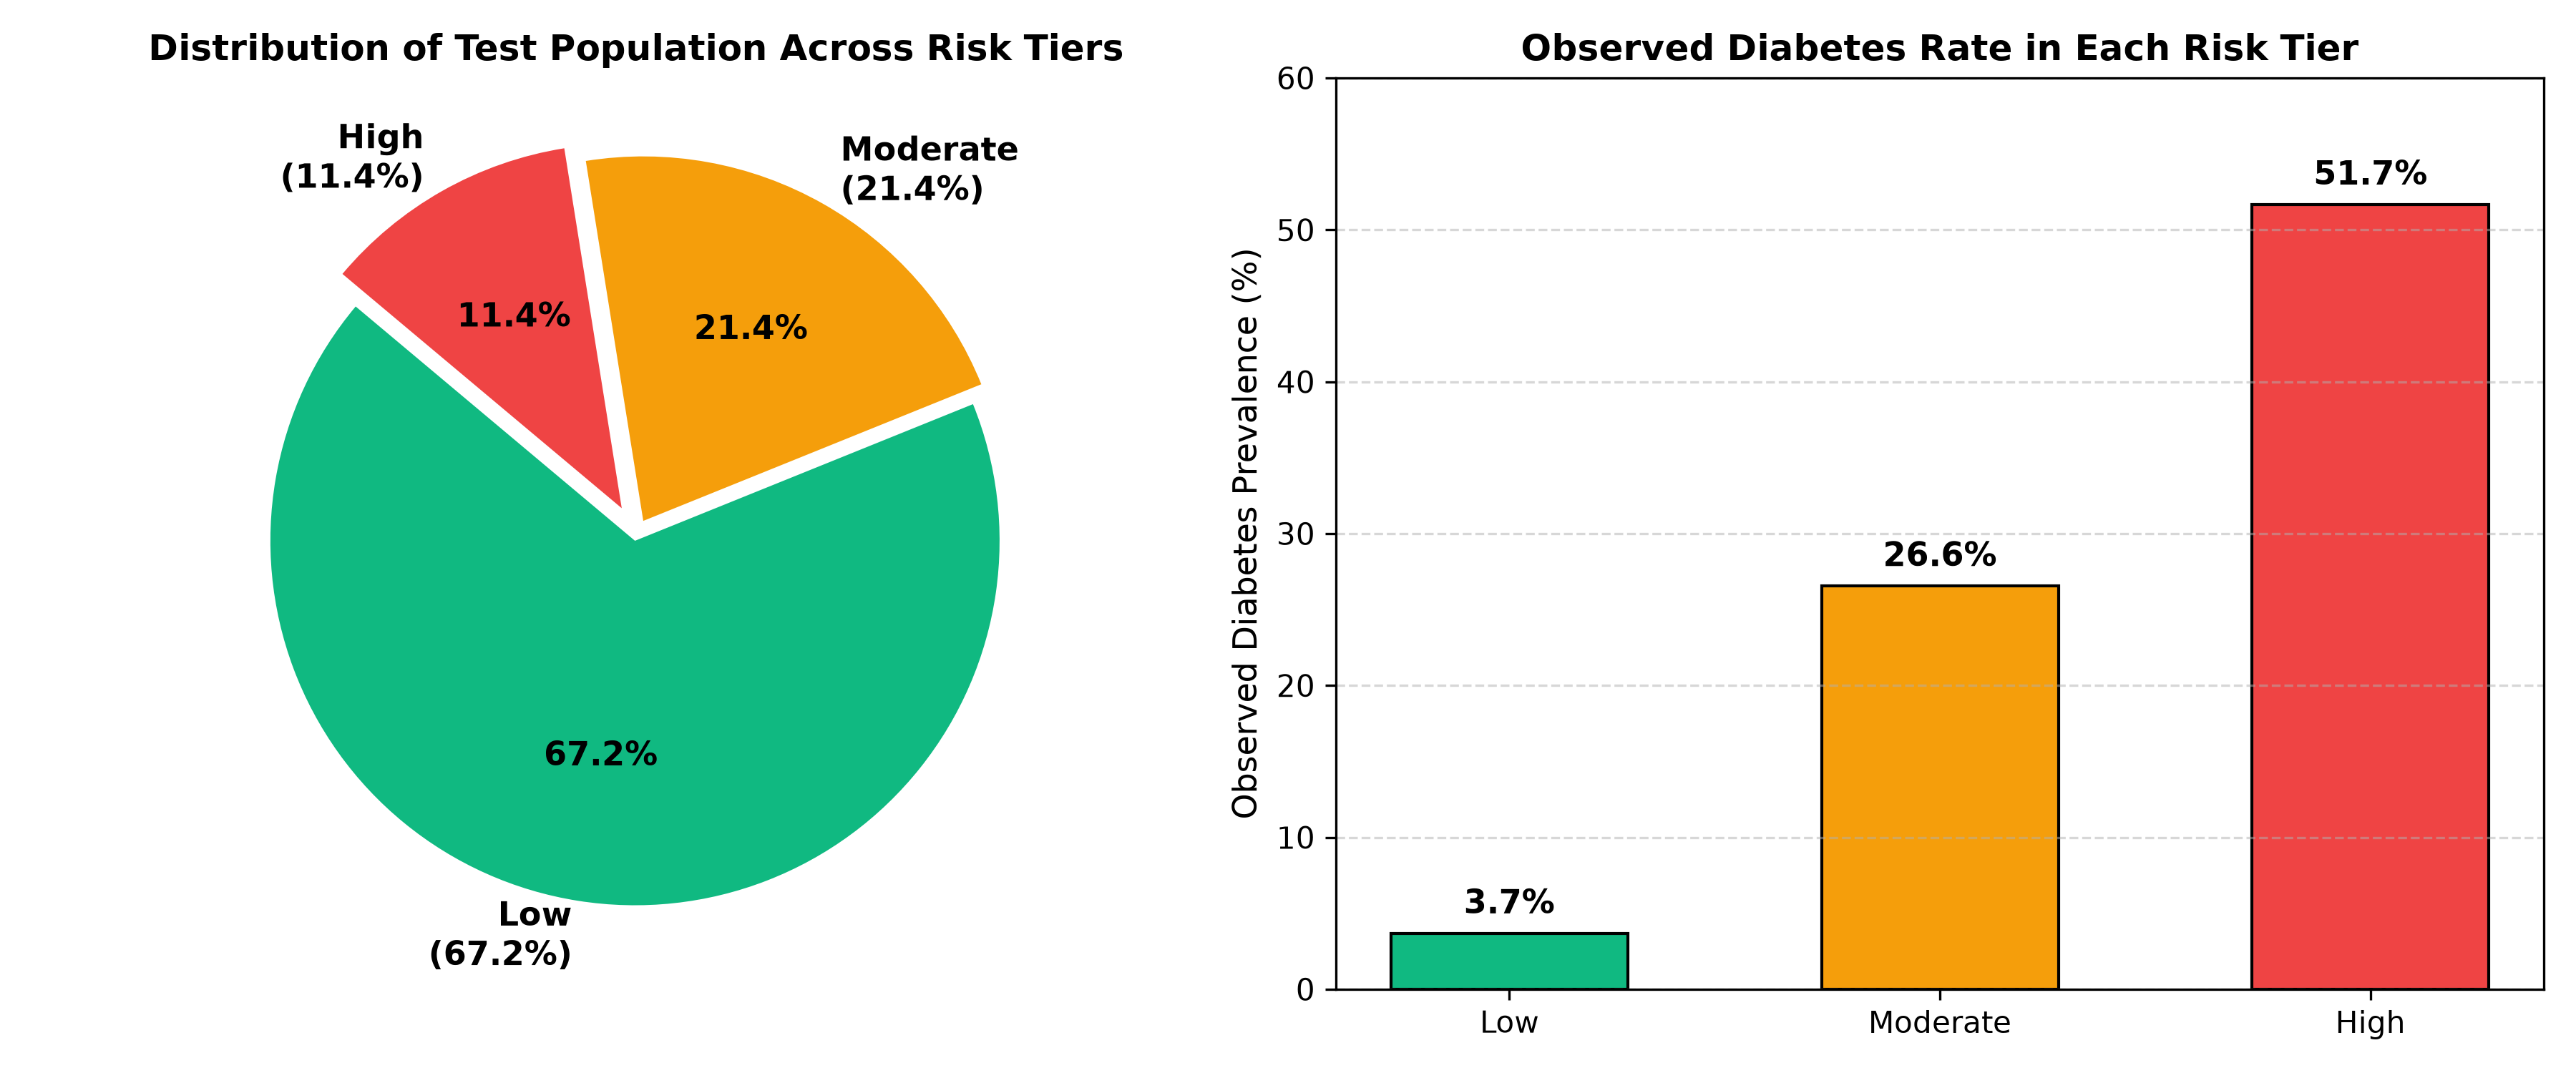

In [12]:
with open('../models/risk_thresholds.json', 'r') as f:
    risk_info = json.load(f)

print(f'Optimal Decision Screening Threshold: {risk_info["decision_threshold"]:.3f}')
print(f'Low Risk Tier Cut-off:      < {risk_info["threshold_low"]:.2f}')
print(f'Moderate Risk Tier Cut-off: {risk_info["threshold_low"]:.2f} to {risk_info["threshold_high"]:.2f}')
print(f'High Risk Tier Cut-off:     >= {risk_info["threshold_high"]:.2f}\n')

r_df = pd.DataFrame(risk_info['risk_summary'])
r_df['share_of_test'] = r_df['share_of_test'].apply(lambda x: f'{x*100:.2f}%')
r_df['observed_diabetes_rate'] = r_df['observed_diabetes_rate'].apply(lambda x: f'{x*100:.2f}%')
r_df.columns = ['Risk Tier Level', 'Test Patients (N)', 'Share of Test Cohort', 'Observed Diabetes Rate']
display(HTML(r_df.to_html(index=False, classes='table table-bordered table-hover')))

display(Image(filename='../reports/figures/risk_level_distribution.png'))

## 11. Dual Operating-Point Analysis: High-Accuracy Mode vs. Screening Mode
Comparative evaluation of **Final Calibrated XGBoost** and **Stacking Ensemble** across:
- **NHANES Held-Out Test Set (Full Features)**
- **NHANES Held-Out Test Set (Shared-7 Features)**
- **CDC BRFSS 2015 External Validation Cohort (Shared-7 Features,  = 249,049$)**

### Operating Point Formulation
- **(a) High-Accuracy Mode ($\\tau_{\\text{acc}}$)**: Decision threshold chosen on the validation partition to maximize overall accuracy.
- **(b) Screening Mode ($\\tau_{80}$)**: Decision threshold chosen on the validation partition to reach $\\ge 80\\%$ recall (sensitivity).
- **Leakage Prevention**: Thresholds are chosen strictly on the NHANES validation split; for BRFSS, the NHANES shared validation thresholds are reused directly without tuning.

Cohort,Model,Operating Point,Threshold,Accuracy,Balanced Acc,Precision,Recall,Specificity,F1,TP,FP,TN,FN
NHANES Test (Full Features),Final Calibrated XGBoost,High-Accuracy Mode,0.402,0.869 [0.855-0.881],0.619 [0.597-0.641],0.568 [0.494-0.637],0.272 [0.227-0.316],0.966 [0.958-0.973],0.368 [0.316-0.419],100 [82-121],76 [60-94],"2,177 [2,139-2,215]",268 [237-301]
NHANES Test (Full Features),Final Calibrated XGBoost,Screening Mode (80% Recall),0.166,0.763 [0.747-0.780],0.789 [0.768-0.811],0.353 [0.322-0.385],0.823 [0.786-0.861],0.754 [0.736-0.773],0.494 [0.459-0.529],303 [270-334],555 [511-596],"1,698 [1,650-1,746]",65 [49-80]
NHANES Test (Full Features),Stacking Ensemble,High-Accuracy Mode,0.449,0.871 [0.858-0.884],0.655 [0.630-0.682],0.562 [0.496-0.626],0.356 [0.306-0.408],0.955 [0.946-0.963],0.436 [0.384-0.485],131 [110-153],102 [84-122],"2,151 [2,112-2,188]",237 [205-266]
NHANES Test (Full Features),Stacking Ensemble,Screening Mode (80% Recall),0.140,0.757 [0.741-0.772],0.786 [0.765-0.807],0.346 [0.315-0.377],0.826 [0.789-0.864],0.745 [0.728-0.763],0.488 [0.452-0.521],304 [272-337],574 [534-616],"1,679 [1,631-1,729]",64 [50-80]
NHANES Test (Shared-7),Final Calibrated XGBoost,High-Accuracy Mode,0.466,0.865 [0.852-0.878],0.577 [0.558-0.597],0.560 [0.468-0.646],0.177 [0.138-0.214],0.977 [0.971-0.983],0.269 [0.216-0.319],65 [50-80],51 [38-66],"2,202 [2,166-2,238]",303 [271-336]
NHANES Test (Shared-7),Final Calibrated XGBoost,Screening Mode (80% Recall),0.170,0.699 [0.682-0.716],0.769 [0.749-0.789],0.301 [0.272-0.329],0.867 [0.831-0.902],0.672 [0.653-0.691],0.447 [0.414-0.479],319 [285-352],740 [695-784],"1,513 [1,462-1,564]",49 [35-63]
NHANES Test (Shared-7),Stacking Ensemble,High-Accuracy Mode,0.475,0.865 [0.851-0.878],0.538 [0.525-0.553],0.646 [0.500-0.783],0.084 [0.058-0.114],0.992 [0.989-0.996],0.149 [0.104-0.198],31 [20-42],17 [9-25],"2,236 [2,201-2,272]",337 [303-371]
NHANES Test (Shared-7),Stacking Ensemble,Screening Mode (80% Recall),0.130,0.716 [0.698-0.732],0.776 [0.756-0.795],0.313 [0.285-0.342],0.859 [0.825-0.894],0.692 [0.672-0.710],0.459 [0.427-0.491],316 [284-351],693 [651-736],"1,560 [1,507-1,607]",52 [38-66]
CDC BRFSS (Shared-7),Final Calibrated XGBoost,High-Accuracy Mode,0.466,0.858 [0.857-0.860],0.572 [0.570-0.574],0.503 [0.494-0.512],0.172 [0.168-0.176],0.972 [0.971-0.973],0.257 [0.252-0.262],"6,085 [5,940-6,239]","6,013 [5,872-6,162]","207,690 [207,320-208,039]","29,261 [28,960-29,590]"
CDC BRFSS (Shared-7),Final Calibrated XGBoost,Screening Mode (80% Recall),0.170,0.584 [0.582-0.586],0.705 [0.703-0.707],0.238 [0.235-0.240],0.874 [0.870-0.877],0.536 [0.534-0.538],0.374 [0.370-0.376],"30,875 [30,538-31,179]","99,105 [98,642-99,589]","114,598 [114,139-115,062]","4,471 [4,349-4,605]"


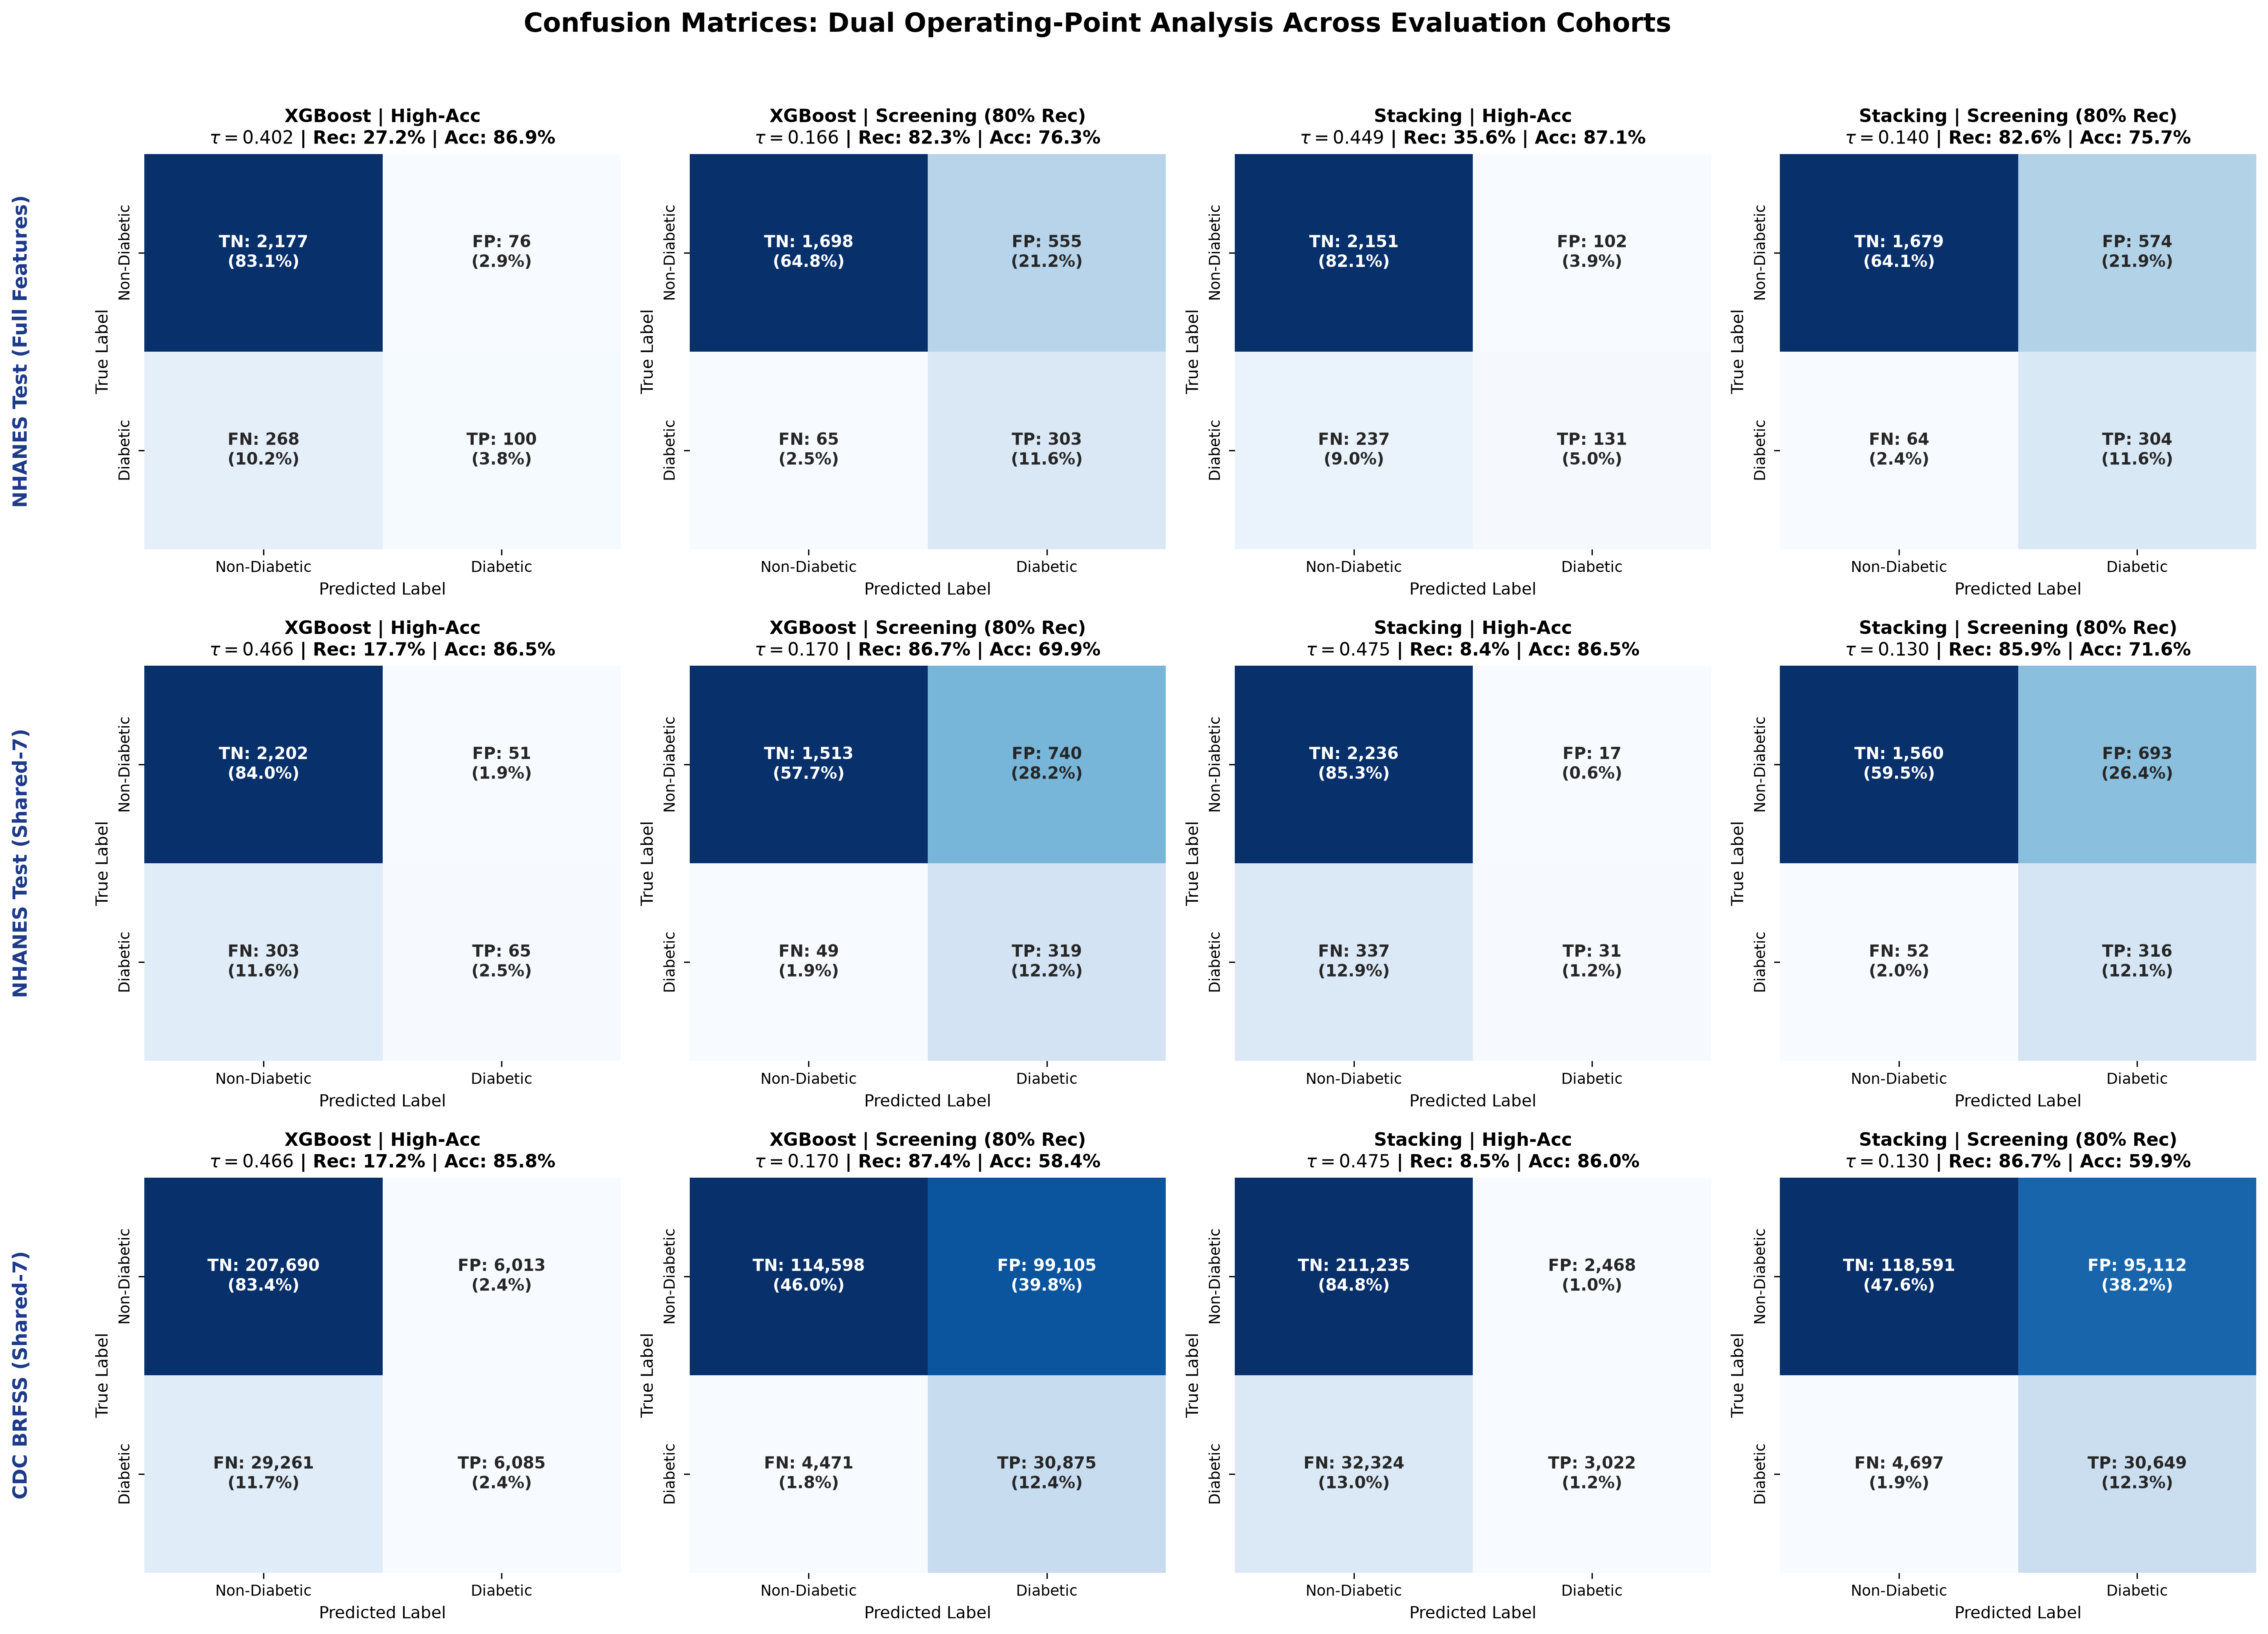

In [13]:
dual_op_table = pd.read_csv('../reports/tables/dual_operating_points.csv')
display(HTML('<h4>Table 11: Dual Operating-Point Performance Metrics & 95% Bootstrap CIs</h4>'))
display(HTML(dual_op_table.to_html(index=False, classes='table table-bordered table-striped table-hover')))

display(HTML('<h4>Figure 11: Confusion Matrices Under High-Accuracy vs. Screening Operating Points</h4>'))
display(Image(filename='../reports/figures/dual_operating_points_cm.png'))


---
# Part B: Tier 2 Lab-Augmented Model (NHANES + HbA1c), used automatically when an HbA1c value is provided
This section presents the **Tier 2 Lab-Augmented Diabetes Risk Architecture**, engineered to incorporate biochemical Glycated Hemoglobin (HbA1c) when laboratory markers are available.

## 12. How the Two Tiers Work Together in a Unified System
LifeMap AI deploys both screening paradigms through a single production endpoint (`POST /predict`):
- **Tier 1 (Non-Invasive Screening)**: When no laboratory tests have been performed, the system executes the Tier 1 model trained exclusively on non-lab survey features (`age`, `sex`, `bmi`, `mean_sbp`, `mean_dbp`, `high_bp`, `high_chol`, `smoker`, `phys_activity`, `family_history`). Response metadata designates `"model_used": "tier1_no_labs"`.
- **Tier 2 (Lab-Augmented Stratification)**: When an HbA1c value (3.0%–18.0%) is provided, the API automatically routes inference to Tier 2, integrating biochemical glycemia into the feature space. Response metadata designates `"model_used": "tier2_with_hba1c"`.

```
                    ┌─────────────────────────────────────────────────────┐
                    │               Client POST /predict                   │
                    │   Demographics, Vitals, History + Optional HbA1c   │
                    └──────────────────────────┬──────────────────────────┘
                                               │
                                      Is HbA1c Provided?
                                      (Range: 3.0 - 18.0%)
                                       /               \
                                      /                 \
                                  [ NO ]              [ YES ]
                                    /                     \
                                   v                       v
               ┌───────────────────────────────┐ ┌───────────────────────────────┐
               │    TIER 1: Non-Lab Model      │ │    TIER 2: Lab-Augmented      │
               │  10 Survey / Vitals Features  │ │   10 Features + HbA1c Lab     │
               │  Calibrated XGBoost (AUROC=.86)│ │  Calibrated XGBoost (AUROC=.95)│
               │  model_used: tier1_no_labs    │ │  model_used: tier2_with_hba1c │
               └───────────────┬───────────────┘ └───────────────┬───────────────┘
                               │                                 │
                               └────────────────┬────────────────┘
                                                v
                               ┌─────────────────────────────────┐
                               │  ADA Rule-Based Safety Checker  │
                               │  & Lab Escalation Verification   │
                               └────────────────┬────────────────┘
                                                v
                               ┌─────────────────────────────────┐
                               │     Unified JSON Response:      │
                               │ Risk %, Tiers, SHAP Drivers,Recs│
                               └─────────────────────────────────┘
```

## 13. Tier 2 Dataset Architecture & Summary
Summary of the NHANES laboratory-augmented adult cohort ($N = 15,936$ with valid HbA1c).
**Leakage Note**: The ground-truth label remains strictly the self-reported clinical diagnosis (`DIQ010`), preserving honest evaluation. HbA1c was measured in an independent venipuncture blood draw and was never part of questionnaire label construction.

In [14]:
t2_data_summary = pd.DataFrame({
    'Cohort Partition': ['Full NHANES Adult Cohort', 'Tier 2 Cohort (Valid HbA1c)', 'Tier 2 Training Split', 'Tier 2 Validation Split', 'Tier 2 Held-Out Test Split'],
    'Total Participants (N)': ['17,468', '15,936 (91.23%)', '11,153 (70.0%)', '2,391 (15.0%)', '2,392 (15.0%)'],
    'Diabetes Cases': ['2,449', '2,278', '1,589', '347', '342'],
    'Prevalence': ['14.02%', '14.29%', '14.25%', '14.51%', '14.30%'],
    'Feature Count': ['10 Features', '11 Features (+HbA1c)', '11 Features', '11 Features', '11 Features'],
    'Label Source': ['DIQ010 (Self-Report)', 'DIQ010 (Self-Report)', 'DIQ010 (Self-Report)', 'DIQ010 (Self-Report)', 'DIQ010 (Self-Report)']
})
display(HTML(t2_data_summary.to_html(index=False, classes='table table-bordered table-striped table-hover')))
print('Tier 2 Feature Space (11 Total Features):')
print('  Continuous (5): age, bmi, mean_sbp, mean_dbp, hba1c')
print('  Binary (6):     sex, high_bp, high_chol, smoker, phys_activity, family_history')

Cohort Partition,Total Participants (N),Diabetes Cases,Prevalence,Feature Count,Label Source
Full NHANES Adult Cohort,"17,468","2,449",14.02%,10 Features,DIQ010 (Self-Report)
Tier 2 Cohort (Valid HbA1c),"15,936 (91.23%)","2,278",14.29%,11 Features (+HbA1c),DIQ010 (Self-Report)
Tier 2 Training Split,"11,153 (70.0%)","1,589",14.25%,11 Features,DIQ010 (Self-Report)
Tier 2 Validation Split,"2,391 (15.0%)",347,14.51%,11 Features,DIQ010 (Self-Report)
Tier 2 Held-Out Test Split,"2,392 (15.0%)",342,14.30%,11 Features,DIQ010 (Self-Report)


Tier 2 Feature Space (11 Total Features):
  Continuous (5): age, bmi, mean_sbp, mean_dbp, hba1c
  Binary (6):     sex, high_bp, high_chol, smoker, phys_activity, family_history


## 14. Label-Noise Analysis & Theoretical Accuracy Bounds
Discrepancy between self-reported diagnosis (`DIQ010`) and biochemical threshold ($	ext{HbA1c} \ge 6.5\%$).
**Structural Accuracy Ceiling**: Because 31.96% of diagnosed diabetics have controlled glycemia ($	ext{HbA1c} < 6.5\%$) via pharmacotherapy, and 2.46% of non-diagnosed adults exhibit undiagnosed hyperglycemia, overall accuracy is bounded around 93%–94%.

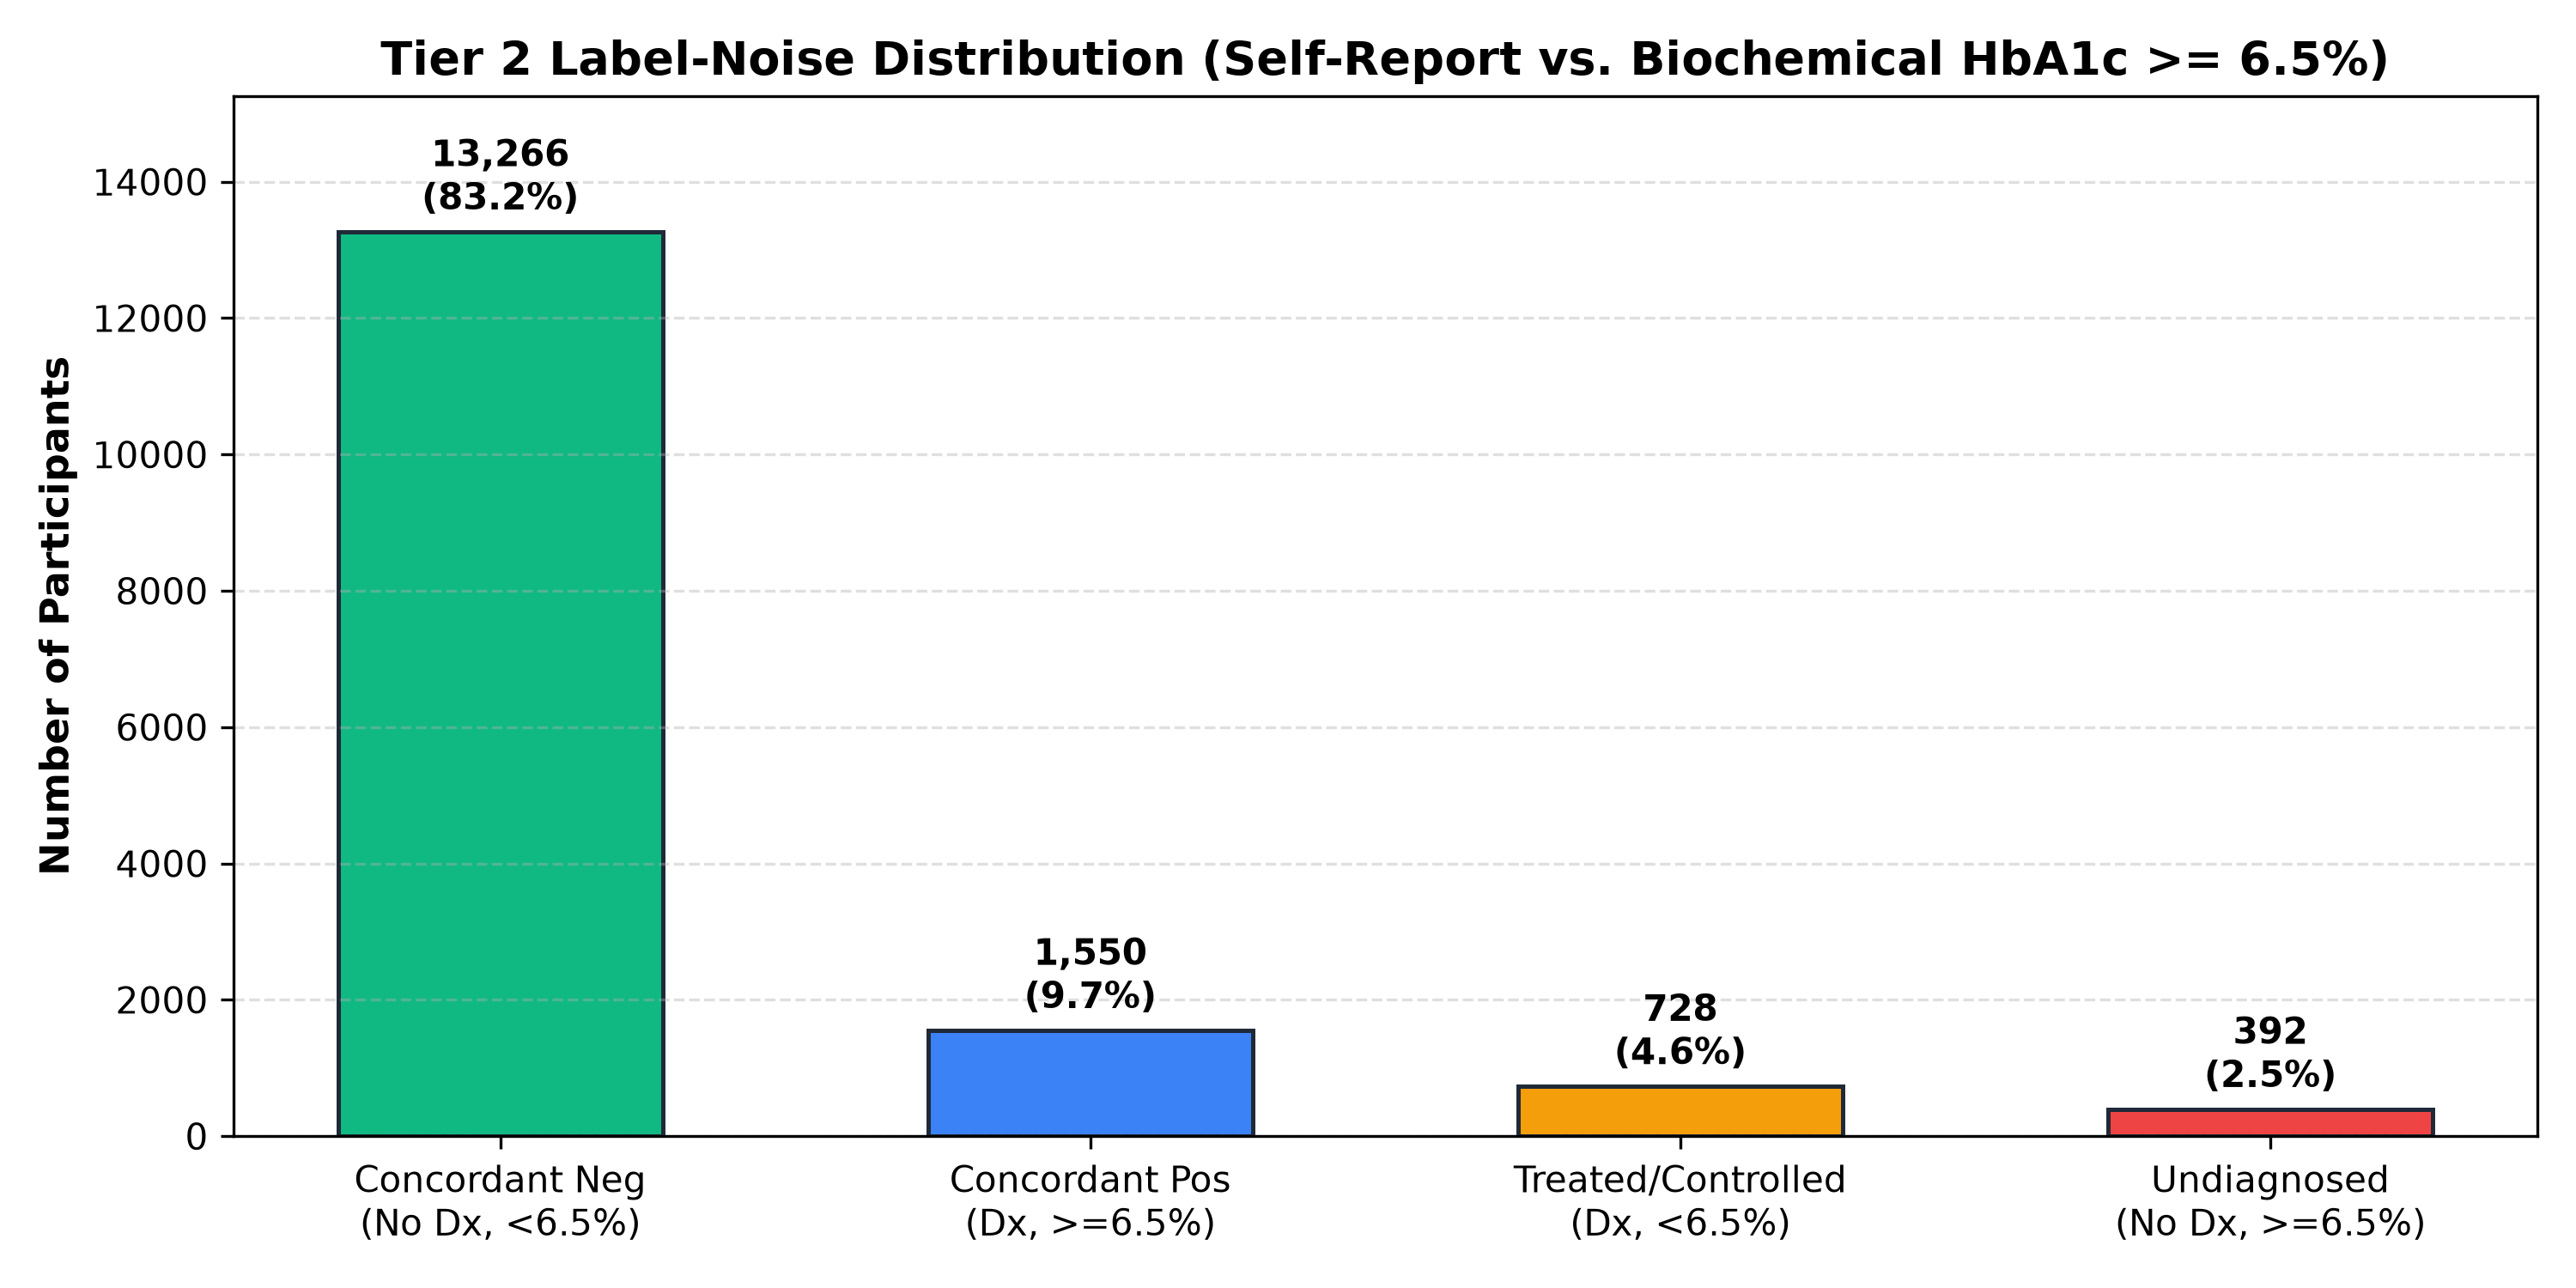

In [15]:
with open('../reports/tables/tier2_label_noise.md', 'r', encoding='utf-8') as f:
    display(HTML(f"<div style='background-color:#F8FAFC; padding:15px; border-left:4px solid #3B82F6;'>{f.read()}</div>"))

display(Image(filename='../reports/figures/tier2_label_noise_bar.png'))

## 15. Tier 2 Model Comparison Table (Held-Out Test Set, $N = 2,392$)
Evaluation of candidate architectures with **95% bootstrap confidence intervals** (1,000 resamples).
**Best value per column highlighted in green.**

In [16]:
t2_table_df = pd.read_csv('../reports/tables/tier2_test_comparison.csv')

def parse_num(val):
    try:
        return float(str(val).split()[0])
    except:
        return 0.0

num_t2 = t2_table_df.copy()
for m in ['Accuracy', 'Balanced Acc', 'Precision', 'Recall', 'F1', 'ROC-AUC', 'PR-AUC', 'Brier']:
    num_t2[f'{m}_val'] = num_t2[m].apply(parse_num)

def highlight_best_t2(s):
    style_res = pd.DataFrame('', index=s.index, columns=s.columns)
    mask = s['Model'] != 'Trivial Baseline (All No)'
    green_style = 'background-color: #D1FAE5; font-weight: bold; color: #065F46;'
    for c in ['Accuracy', 'Balanced Acc', 'Precision', 'Recall', 'F1', 'ROC-AUC', 'PR-AUC']:
        best_idx = num_t2.loc[mask, f'{c}_val'].idxmax()
        style_res.loc[best_idx, c] = green_style
    best_brier = num_t2.loc[mask, 'Brier_val'].idxmin()
    style_res.loc[best_brier, 'Brier'] = green_style
    return style_res

styled_t2 = t2_table_df.style.apply(highlight_best_t2, axis=None).set_caption(
    '<b>Comprehensive Tier 2 Model Performance (NHANES + HbA1c Held-Out Test Set, N=2,392)</b>'
)
display(styled_t2)

,Model,Accuracy,Balanced Acc,Precision,Recall,Specificity,F1,ROC-AUC,PR-AUC,Brier
0,Trivial Baseline (All No),0.857 [0.842-0.872],0.500000,0.000000,0.000 [0.000-0.000],1.000000,0.000000,0.500 [0.470-0.530],0.143 [0.128-0.158],0.143000
1,Ablation: HbA1c ONLY (LogReg),0.903 [0.891-0.915],0.871000,0.623000,0.825 [0.783-0.864],0.917000,0.709000,0.929 [0.909-0.946],0.770 [0.721-0.816],0.087000
2,Ablation: Tier 1 Features ONLY (XGB),0.763 [0.745-0.780],0.785000,0.356000,0.816 [0.774-0.858],0.754000,0.496000,0.855 [0.834-0.876],0.472 [0.419-0.534],0.158000
3,Logistic Regression,0.893 [0.880-0.904],0.890000,0.582000,0.886 [0.851-0.920],0.894000,0.702000,0.944 [0.929-0.957],0.802 [0.757-0.847],0.085000
4,Random Forest,0.913 [0.902-0.924],0.888000,0.649000,0.854 [0.816-0.893],0.923000,0.737000,0.949 [0.936-0.961],0.827 [0.790-0.861],0.076000
5,XGBoost,0.906 [0.894-0.916],0.886000,0.623000,0.860 [0.821-0.893],0.913000,0.722000,0.949 [0.934-0.960],0.833 [0.795-0.863],0.077000
6,PyTorch MLP,0.885 [0.871-0.897],0.884000,0.561000,0.883 [0.844-0.918],0.885000,0.686000,0.950 [0.938-0.963],0.824 [0.780-0.865],0.087000
7,Stacking Ensemble,0.936 [0.926-0.945],0.860000,0.789000,0.754 [0.708-0.797],0.966000,0.771000,0.951 [0.938-0.963],0.836 [0.798-0.872],0.050000
8,Final Calibrated XGBoost,0.935 [0.925-0.945],0.846000,0.805000,0.722 [0.676-0.771],0.971000,0.761000,0.946 [0.933-0.958],0.801 [0.763-0.837],0.050000


## 16. Key Metrics Bar Chart, Confusion Matrices & ROC/PR Curves
Visual benchmark across all evaluated Tier 2 architectures.

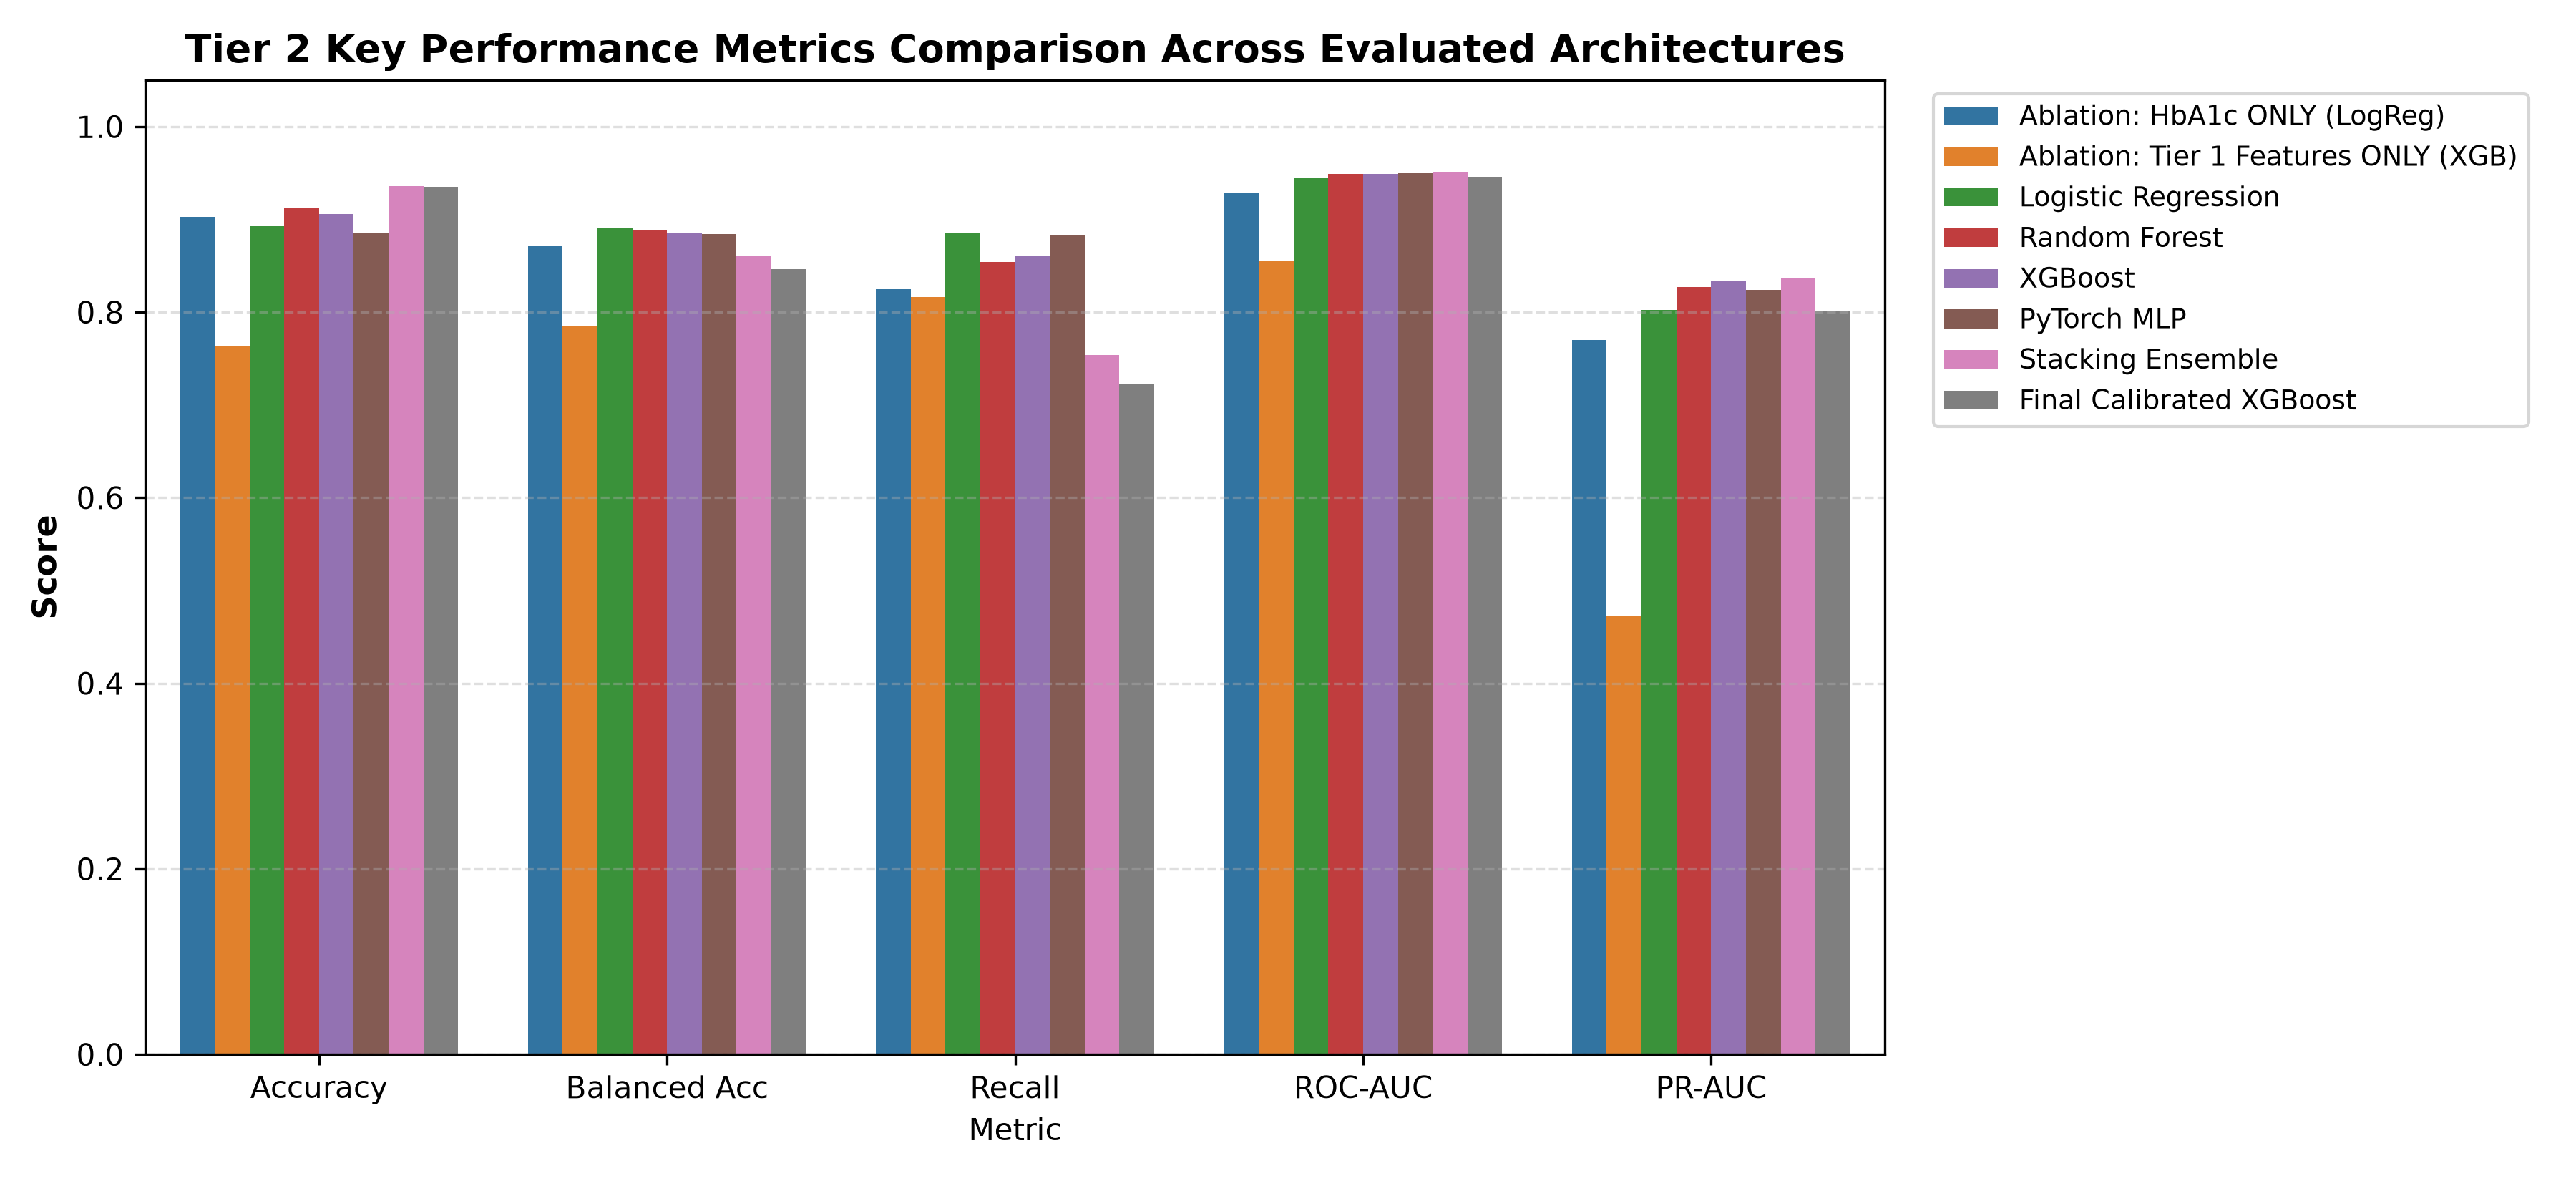

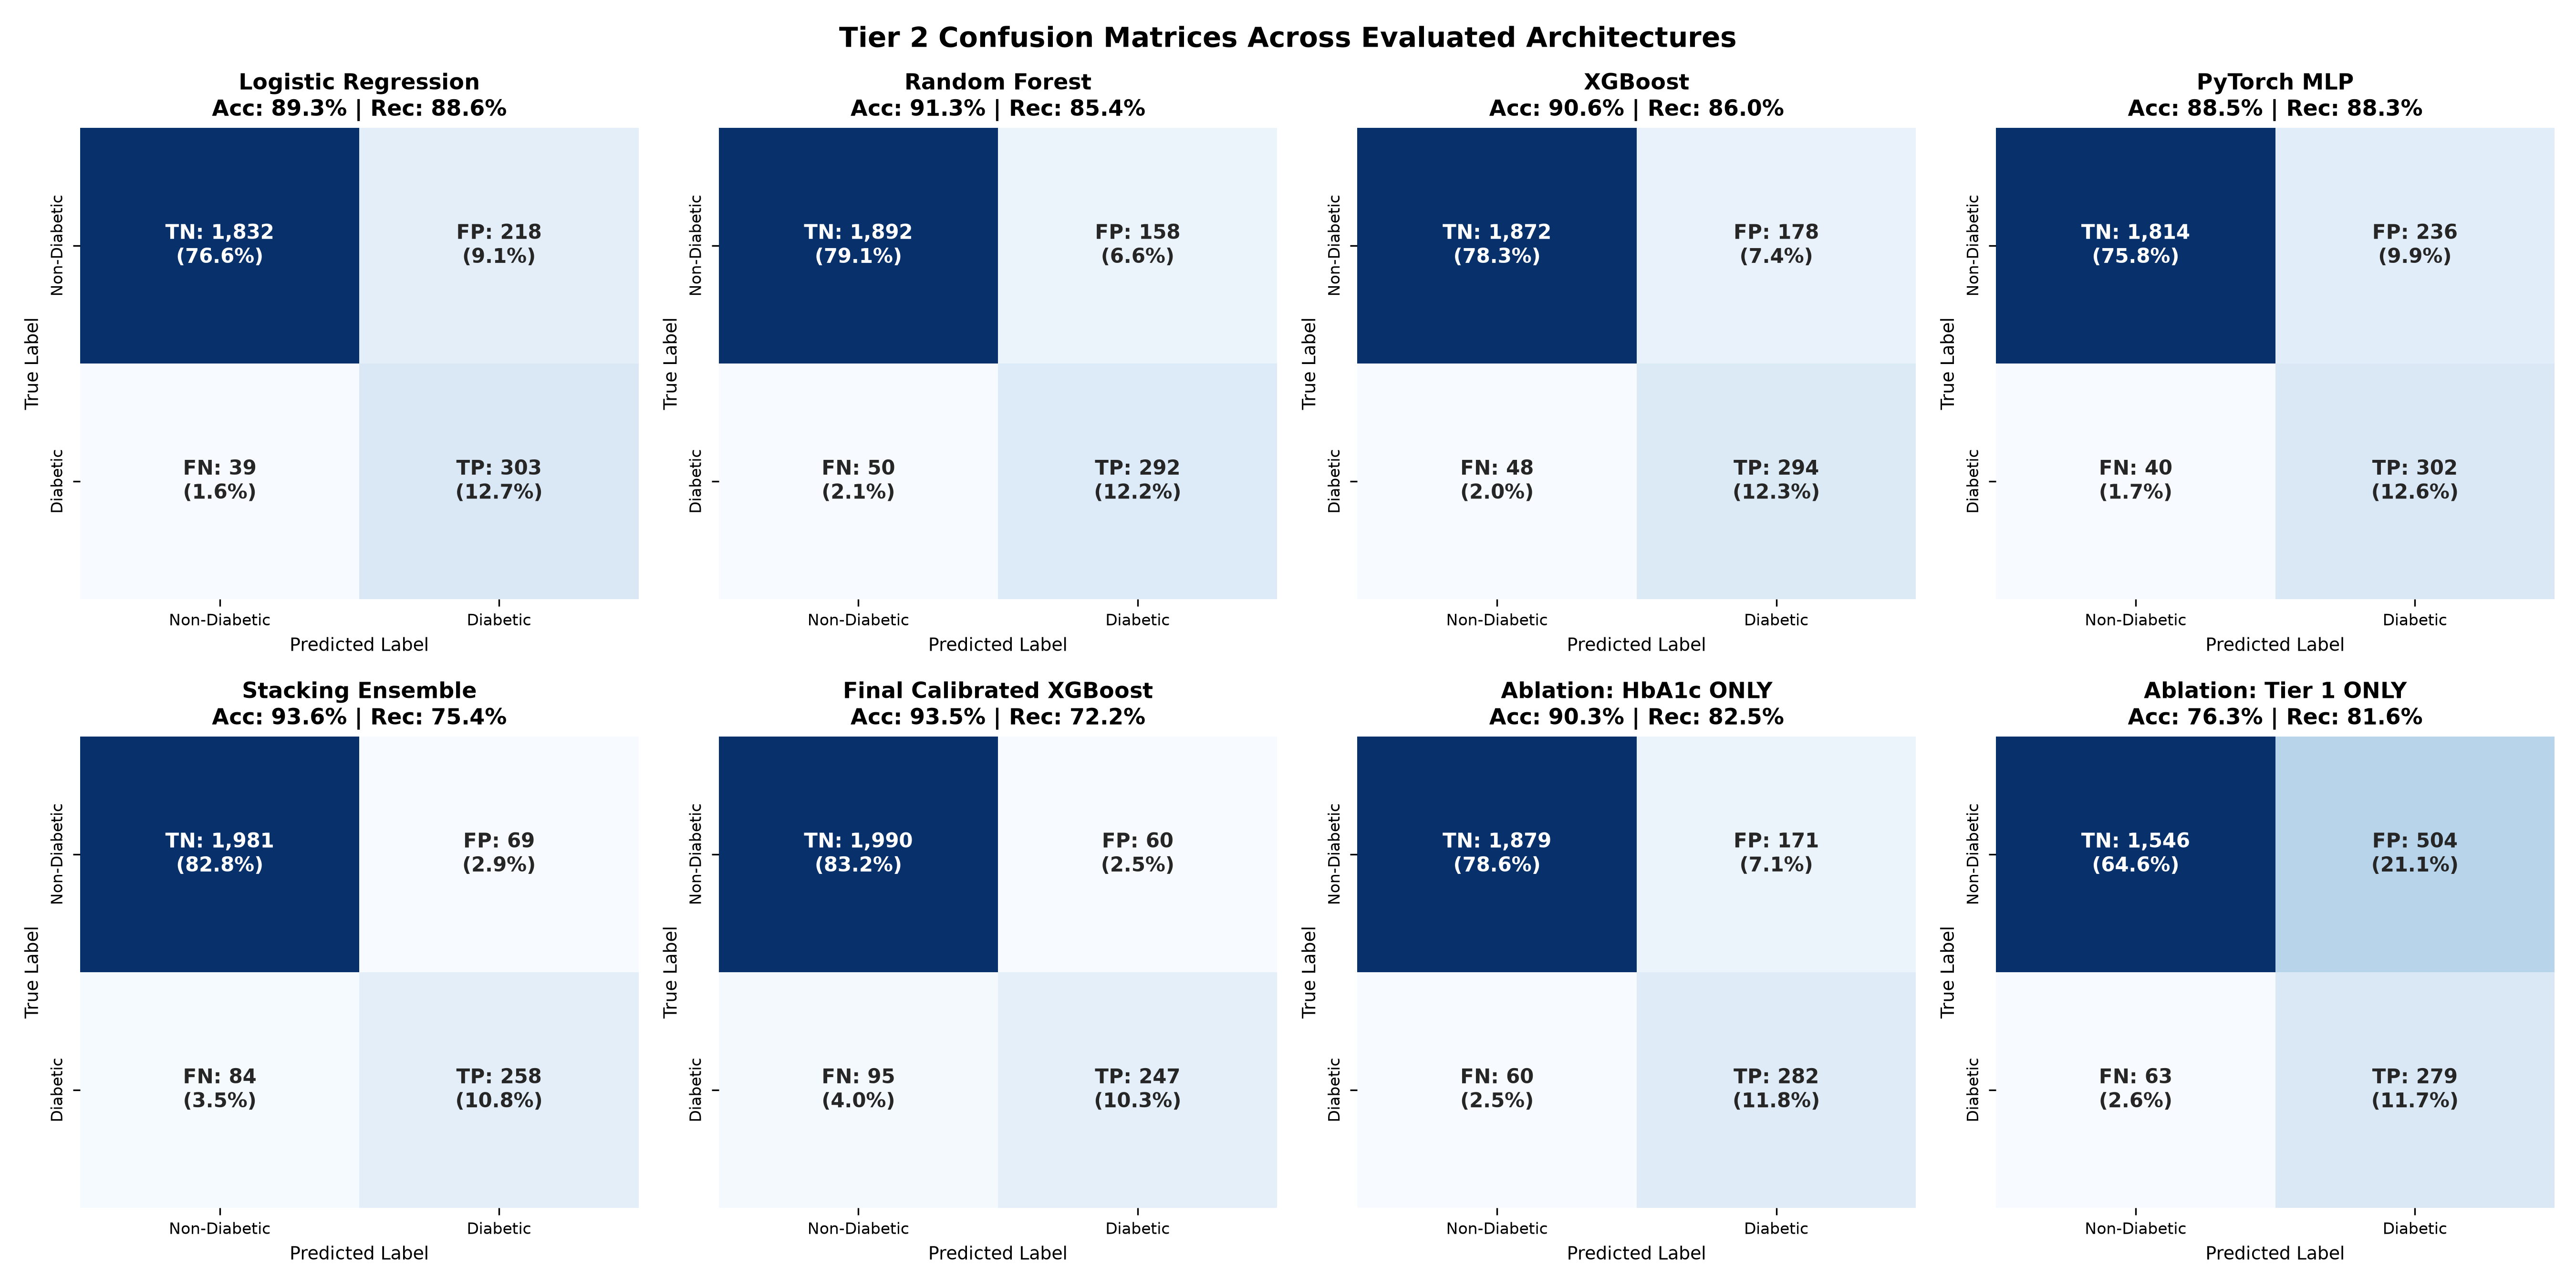

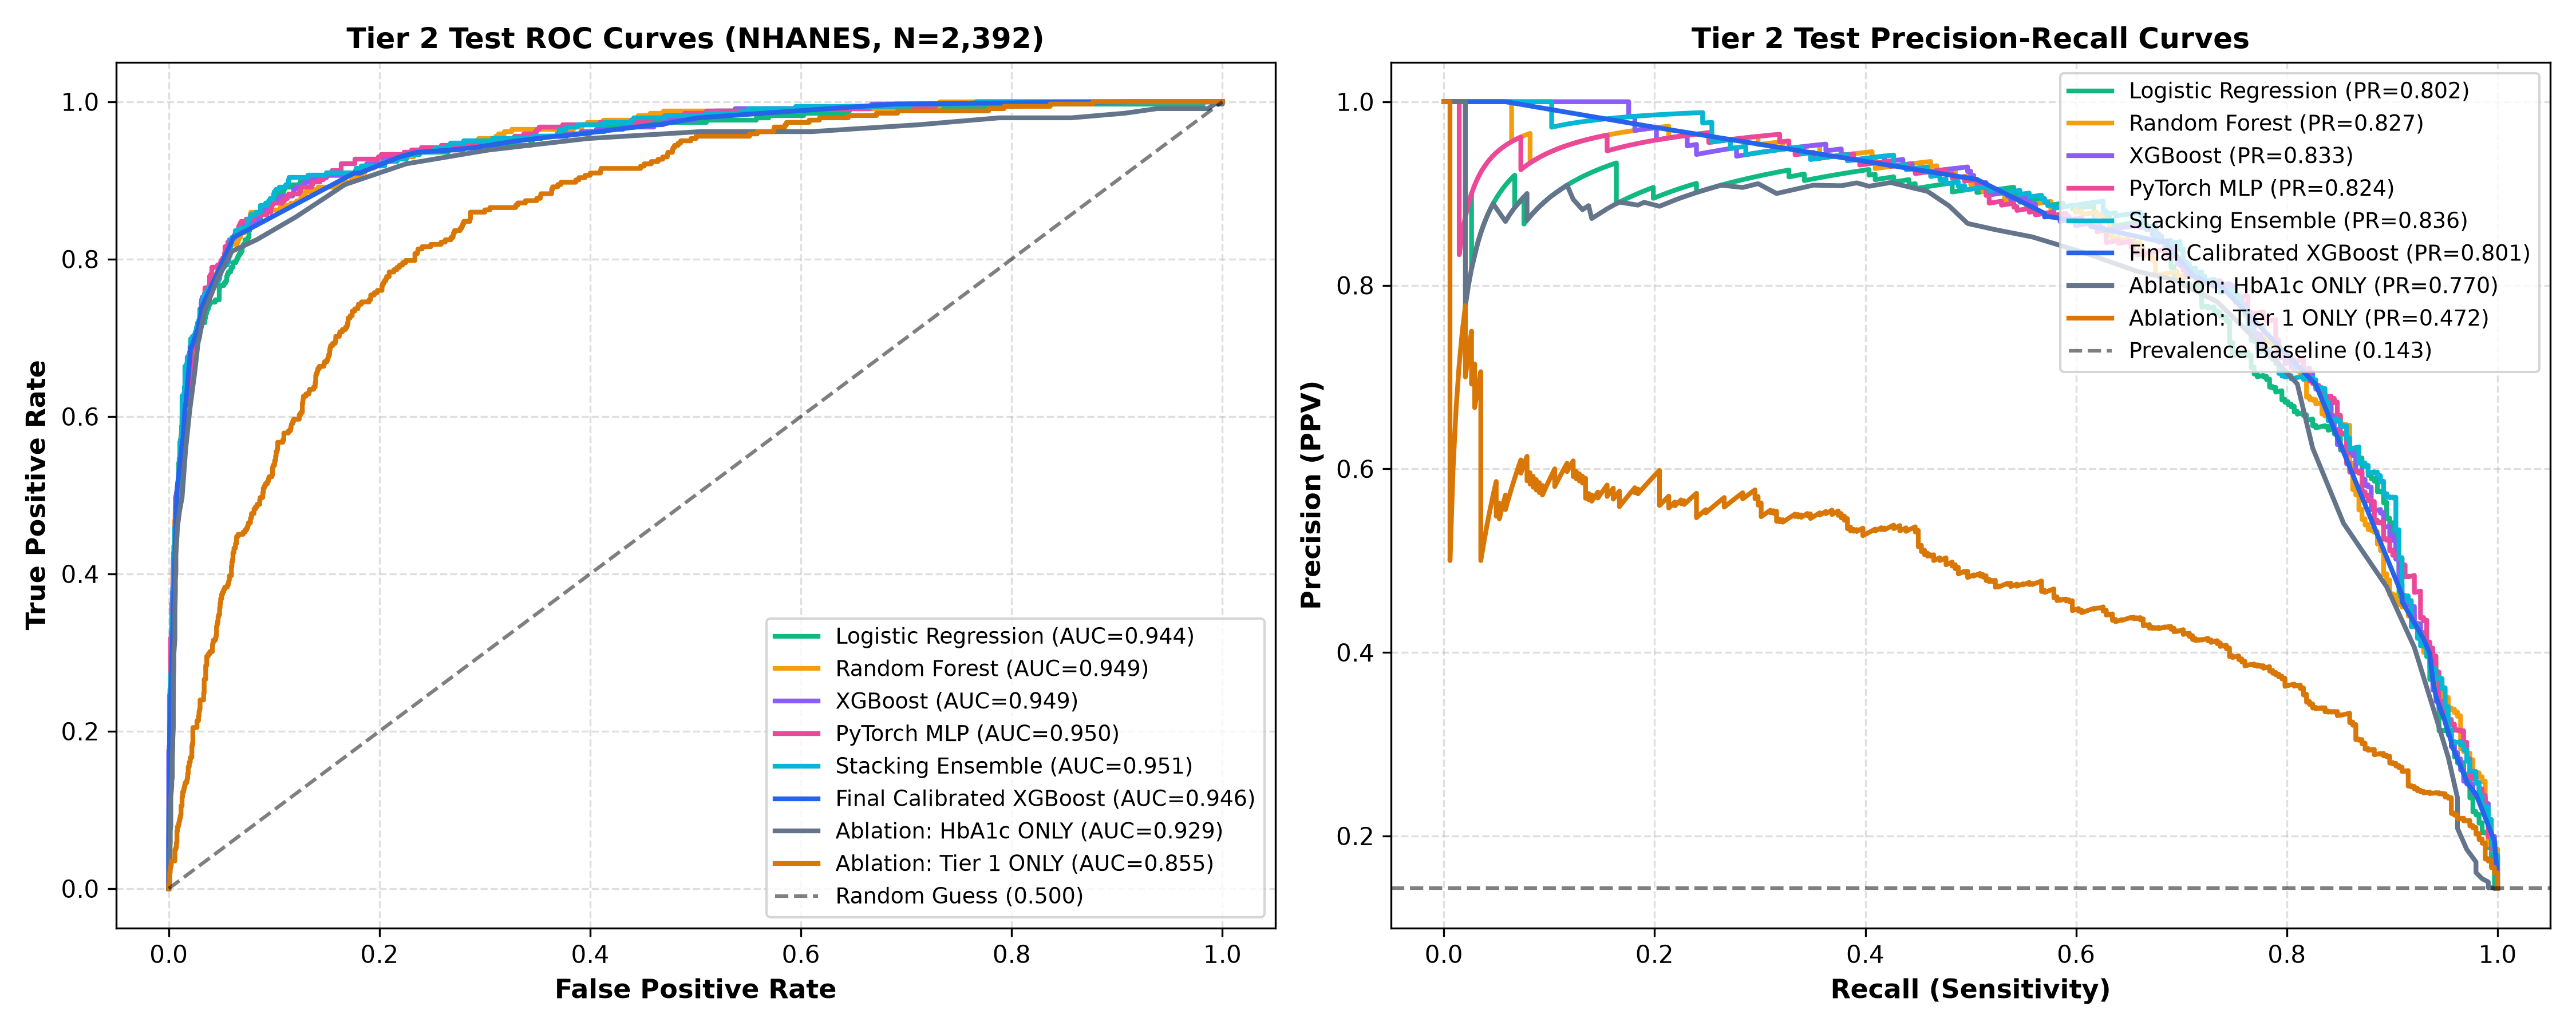

In [17]:
display(HTML('<h3>16.1 Key Performance Metrics Bar Chart</h3>'))
display(Image(filename='../reports/figures/tier2_model_metrics_bar.png'))

display(HTML('<h3>16.2 Confusion Matrices Across Evaluated Architectures</h3>'))
display(Image(filename='../reports/figures/tier2_confusion_matrices.png'))

display(HTML('<h3>16.3 Overlaid ROC and Precision-Recall Curves</h3>'))
display(Image(filename='../reports/figures/tier2_roc_pr_curves.png'))

## 17. Probability Calibration & Deep MLP Training Dynamics
Reliability curves before vs. after isotonic calibration and PyTorch MLP training convergence.

=== PyTorch Tier 2 Deep MLP Architecture Specification ===
Input Dimension: 11 tabular features (10 survey/vitals + HbA1c)
Layer 1: Linear(11 -> 64) -> BatchNorm1d(64) -> ReLU() -> Dropout(0.25)
Layer 2: Linear(64 -> 32) -> BatchNorm1d(32) -> ReLU() -> Dropout(0.20)
Layer 3: Linear(32 -> 16) -> ReLU()
Output Layer: Linear(16 -> 1) [BCEWithLogitsLoss with positive weighting = 6.02]
Optimization: Adam (lr=1e-3, weight_decay=1e-4) with validation early stopping



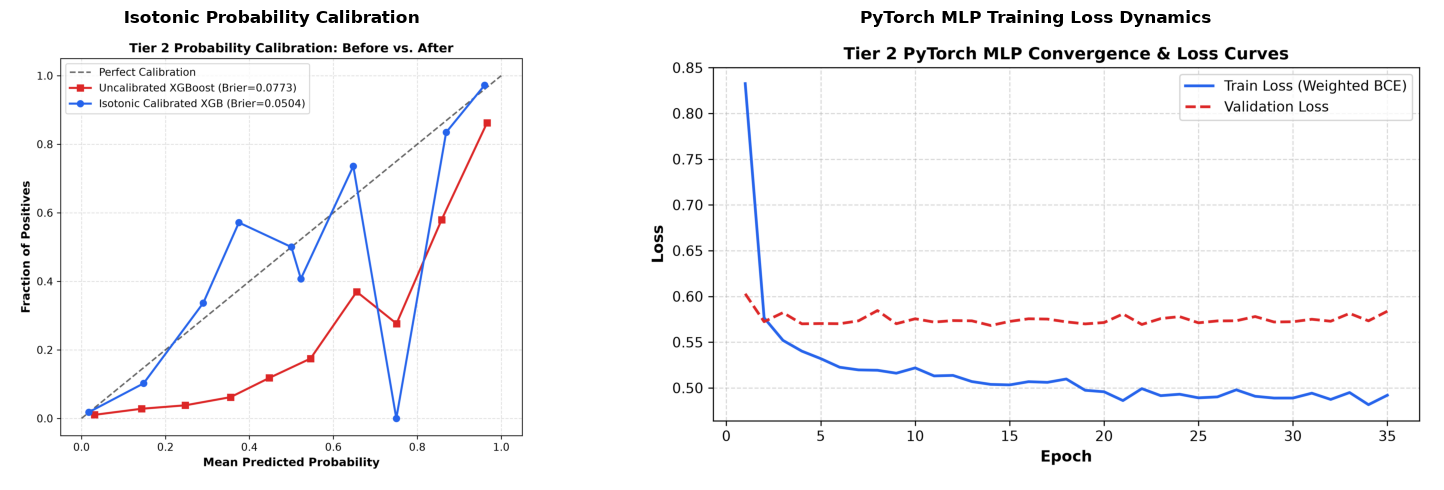

In [18]:
print('=== PyTorch Tier 2 Deep MLP Architecture Specification ===')
print('Input Dimension: 11 tabular features (10 survey/vitals + HbA1c)')
print('Layer 1: Linear(11 -> 64) -> BatchNorm1d(64) -> ReLU() -> Dropout(0.25)')
print('Layer 2: Linear(64 -> 32) -> BatchNorm1d(32) -> ReLU() -> Dropout(0.20)')
print('Layer 3: Linear(32 -> 16) -> ReLU()')
print('Output Layer: Linear(16 -> 1) [BCEWithLogitsLoss with positive weighting = 6.02]')
print('Optimization: Adam (lr=1e-3, weight_decay=1e-4) with validation early stopping\n')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))
im1 = PILImage.open('../reports/figures/tier2_calibration_curves.png')
ax1.imshow(im1)
ax1.axis('off')
ax1.set_title('Isotonic Probability Calibration', fontsize=12, fontweight='bold')

im2 = PILImage.open('../reports/figures/tier2_mlp_training_history.png')
ax2.imshow(im2)
ax2.axis('off')
ax2.set_title('PyTorch MLP Training Loss Dynamics', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

## 18. Tier 2 Dual Operating-Point Analysis: High-Accuracy Mode vs. Screening Mode
Evaluating **Calibrated XGBoost** and **Stacking Ensemble** under:
- **(a) High-Accuracy Mode ($	au_{	ext{acc}}$)**: Threshold chosen on validation to maximize overall accuracy.
- **(b) Screening Mode ($	au_{80}$)**: Threshold chosen on validation to guarantee $\ge 80\%$ recall.

Model,Operating Point,Threshold,Accuracy,Balanced Acc,Precision,Recall,Specificity,F1,TP,FP,TN,FN
Final Calibrated XGBoost,High-Accuracy Mode,0.376,0.935 [0.926-0.945],0.846 [0.824-0.871],0.805 [0.758-0.848],0.722 [0.677-0.772],0.971 [0.963-0.978],0.761 [0.723-0.796],247 [217-275],60 [46-76],"1,990 [1,958-2,024]",95 [76-112]
Final Calibrated XGBoost,Screening Mode (80% Recall),0.290,0.923 [0.912-0.933],0.883 [0.863-0.904],0.692 [0.646-0.733],0.827 [0.788-0.868],0.939 [0.928-0.949],0.754 [0.715-0.787],283 [251-316],126 [106-147],"1,924 [1,887-1,962]",59 [44-73]
Stacking Ensemble,High-Accuracy Mode,0.628,0.936 [0.927-0.946],0.839 [0.813-0.864],0.828 [0.782-0.870],0.702 [0.652-0.754],0.976 [0.969-0.982],0.759 [0.721-0.795],240 [211-268],50 [37-65],"2,000 [1,967-2,036]",102 [83-122]
Stacking Ensemble,Screening Mode (80% Recall),0.233,0.917 [0.906-0.927],0.884 [0.864-0.904],0.666 [0.622-0.709],0.839 [0.800-0.877],0.930 [0.919-0.940],0.743 [0.710-0.774],287 [257-320],144 [123-167],"1,906 [1,869-1,946]",55 [41-70]


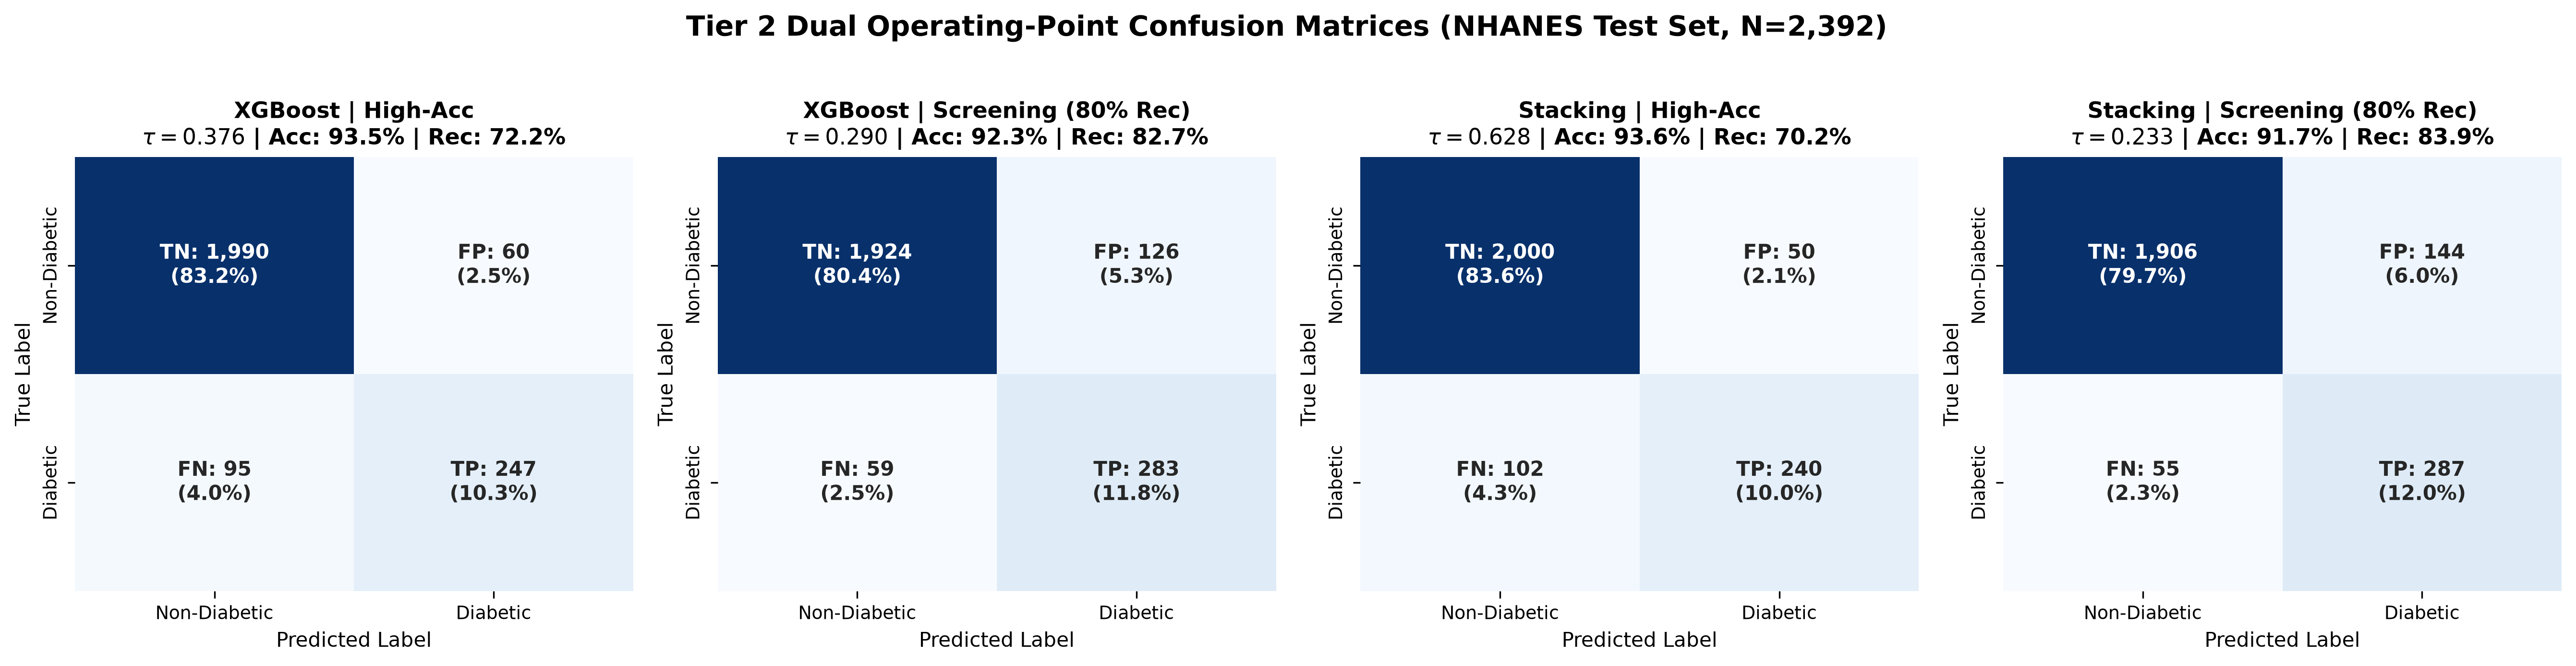

In [19]:
t2_dop_table = pd.read_csv('../reports/tables/tier2_dual_operating_points.csv')
display(HTML('<h4>Table 18: Tier 2 Dual Operating-Point Metrics & 95% Bootstrap CIs</h4>'))
display(HTML(t2_dop_table.to_html(index=False, classes='table table-bordered table-striped table-hover')))

display(Image(filename='../reports/figures/tier2_dual_operating_points_cm.png'))

## 19. Tier 1 vs. Tier 2 Fair Comparison on Identical Rows ($N = 2,392$)
Direct comparison isolating the clinical contribution of laboratory HbA1c on the exact same held-out test cohort.

Metric / Setting,"Tier 1 (No HbA1c, Same Rows)","Tier 2 (With HbA1c, Same Rows)",Absolute Gain (+Delta)
ROC-AUC (Overall Discrimination),0.852,0.946,+0.094
PR-AUC (Precision-Recall Area),0.452,0.801,+0.349
"Brier Score (Reliability, Lower is Better)",0.094,0.050,-0.044
High-Accuracy Mode: Decision Threshold (tau),0.402,0.376,-
High-Accuracy Mode: Accuracy,0.865,0.935,+0.070
High-Accuracy Mode: Recall (Sensitivity),0.272,0.722,+0.450
Screening Mode: Decision Threshold (tau_80),0.142,0.290,-
Screening Mode: Accuracy,0.758,0.923,+0.165
Screening Mode: Recall (Sensitivity),0.827,0.827,+0.000


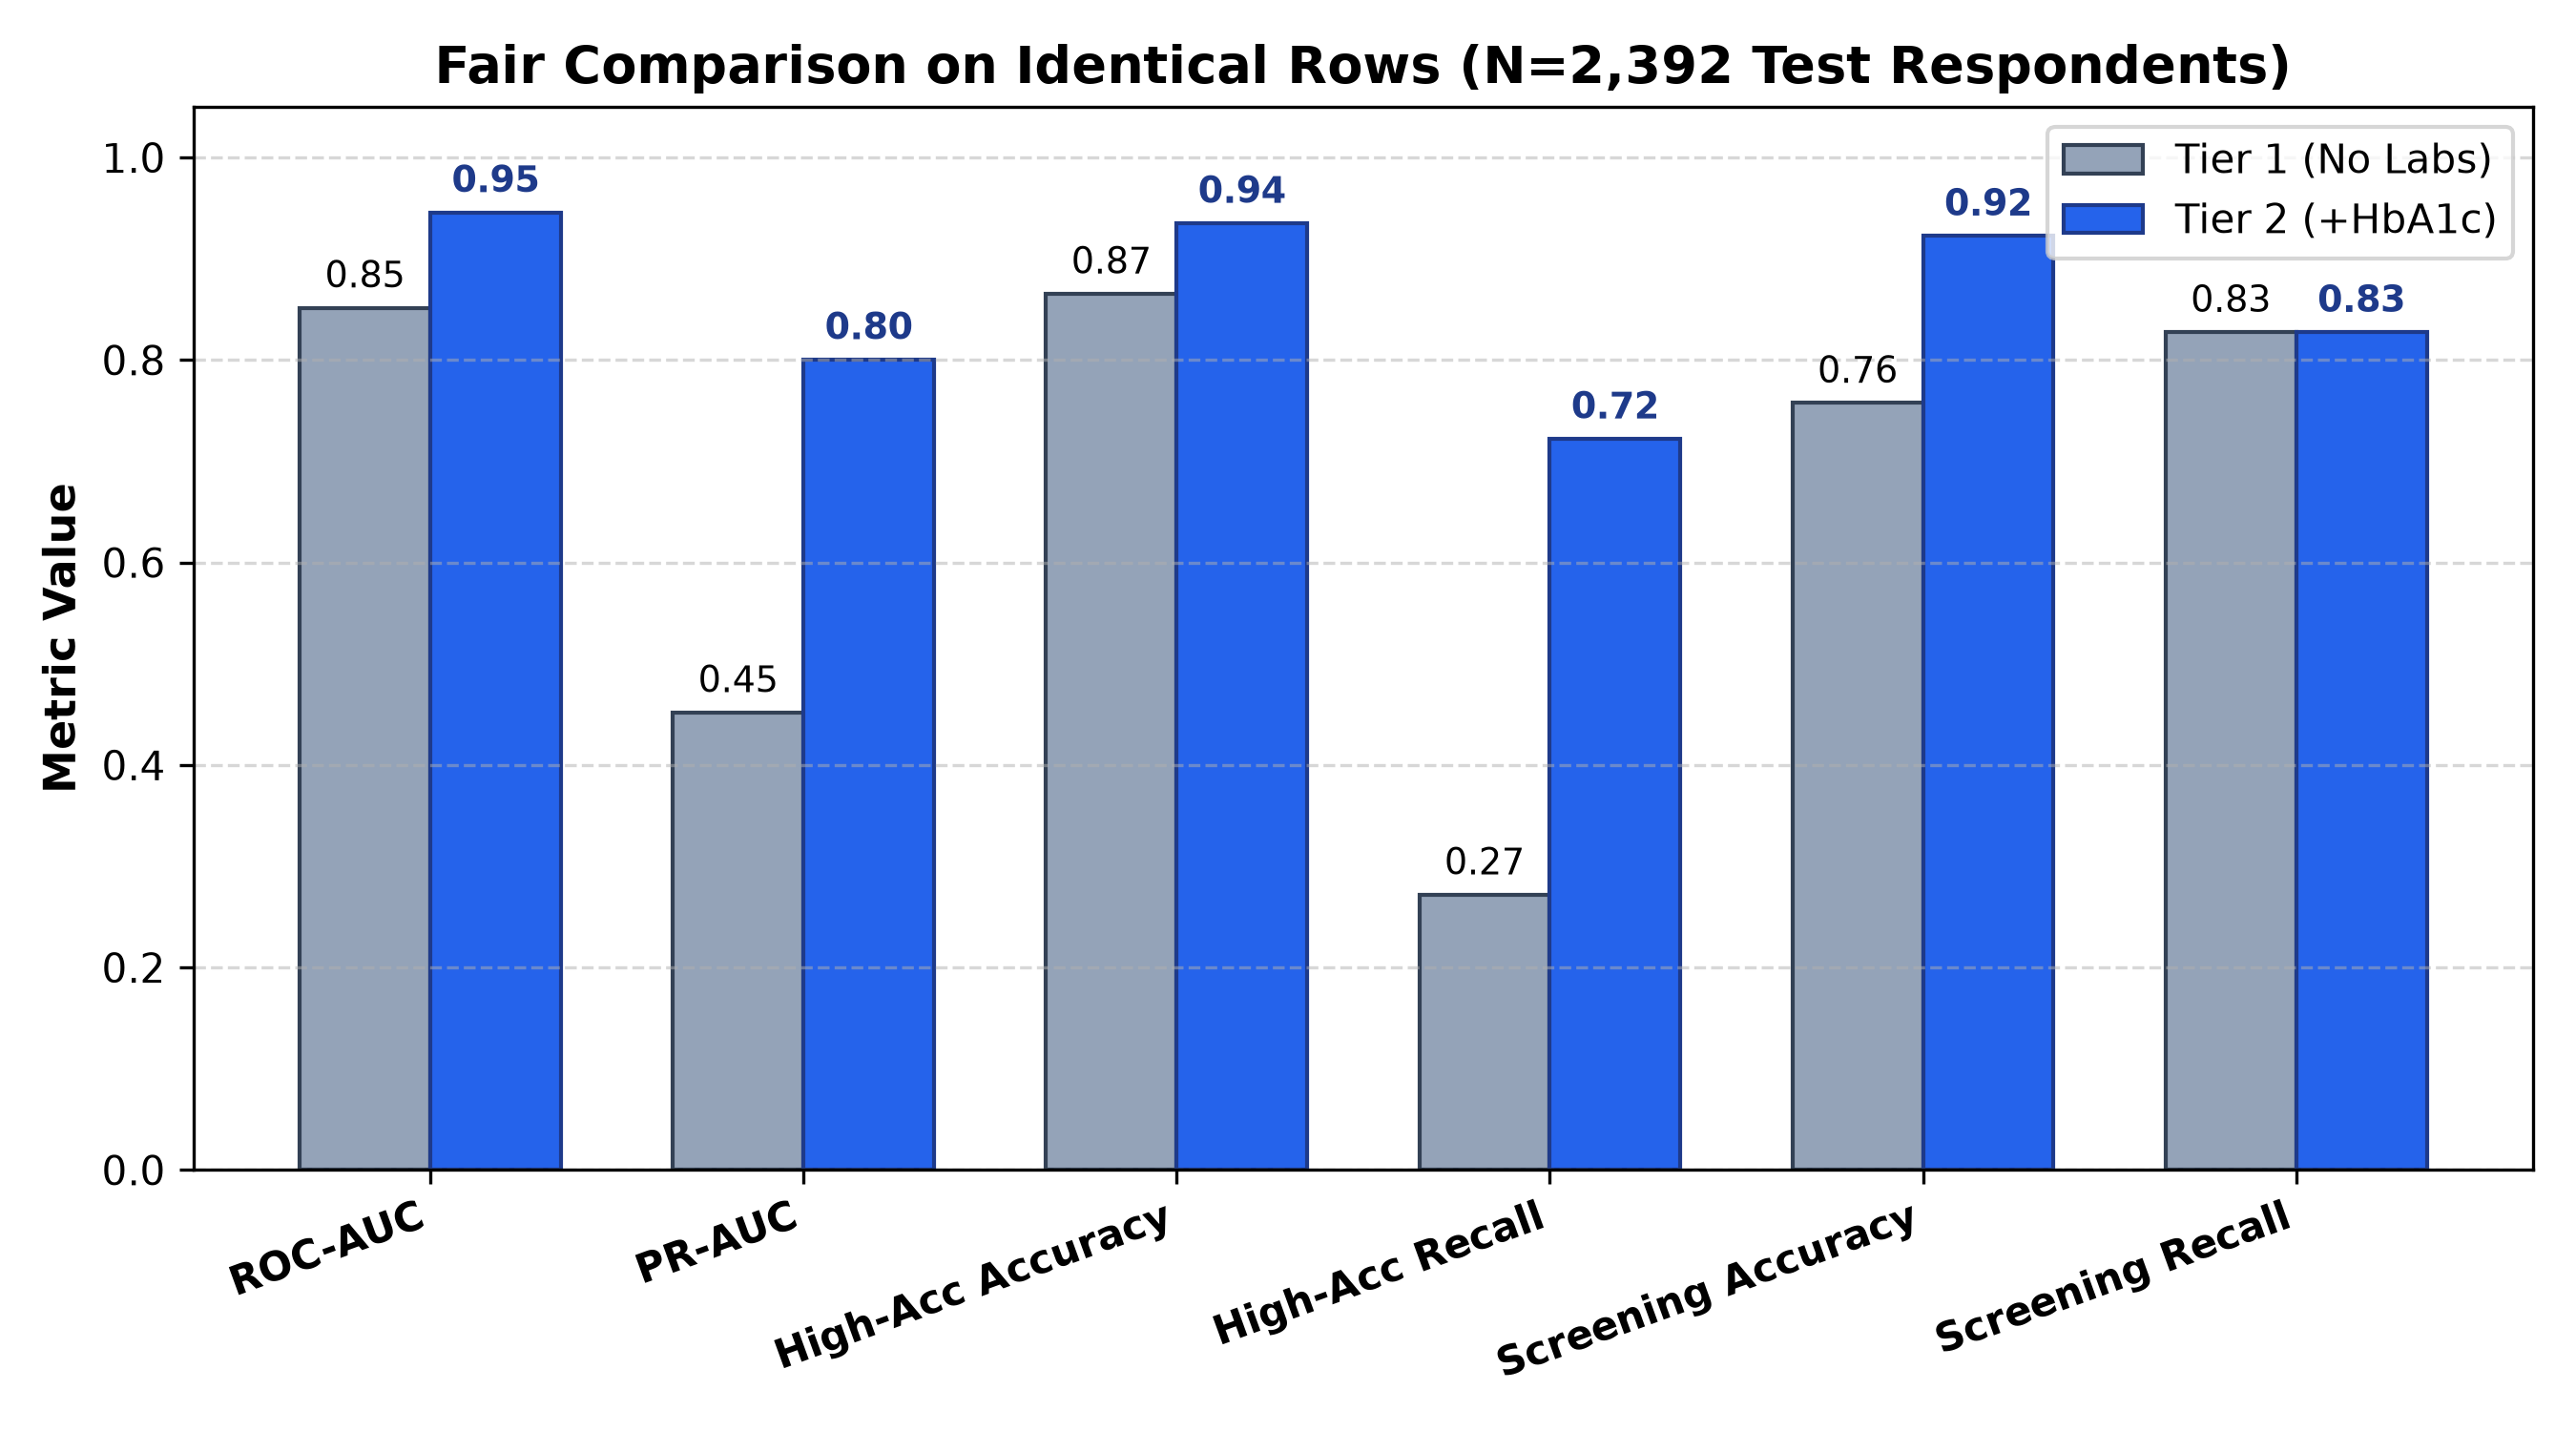

In [20]:
t1_t2_comp = pd.read_csv('../reports/tables/tier2_tier1_vs_tier2_comparison.csv')
display(HTML('<h4>Table 19: Tier 1 vs. Tier 2 Metrics on Identical Test Rows</h4>'))
display(HTML(t1_t2_comp.to_html(index=False, classes='table table-bordered table-hover table-striped')))

display(Image(filename='../reports/figures/tier2_tier1_vs_tier2_comparison.png'))

## 20. Tier 2 Interpretability: Native TreeSHAP & LIME Explanations
Global feature attribution rankings and patient-level waterfall decompositions.

=== Top 5 Tier 2 Global Feature Drivers ===
  Rank 1: hba1c            (Mean |SHAP| = 1.9867)
  Rank 2: age              (Mean |SHAP| = 0.4538)
  Rank 3: family_history   (Mean |SHAP| = 0.4470)
  Rank 4: high_bp          (Mean |SHAP| = 0.3859)
  Rank 5: high_chol        (Mean |SHAP| = 0.2179)

HbA1c Rank: #1 (Overwhelmingly the primary driver)



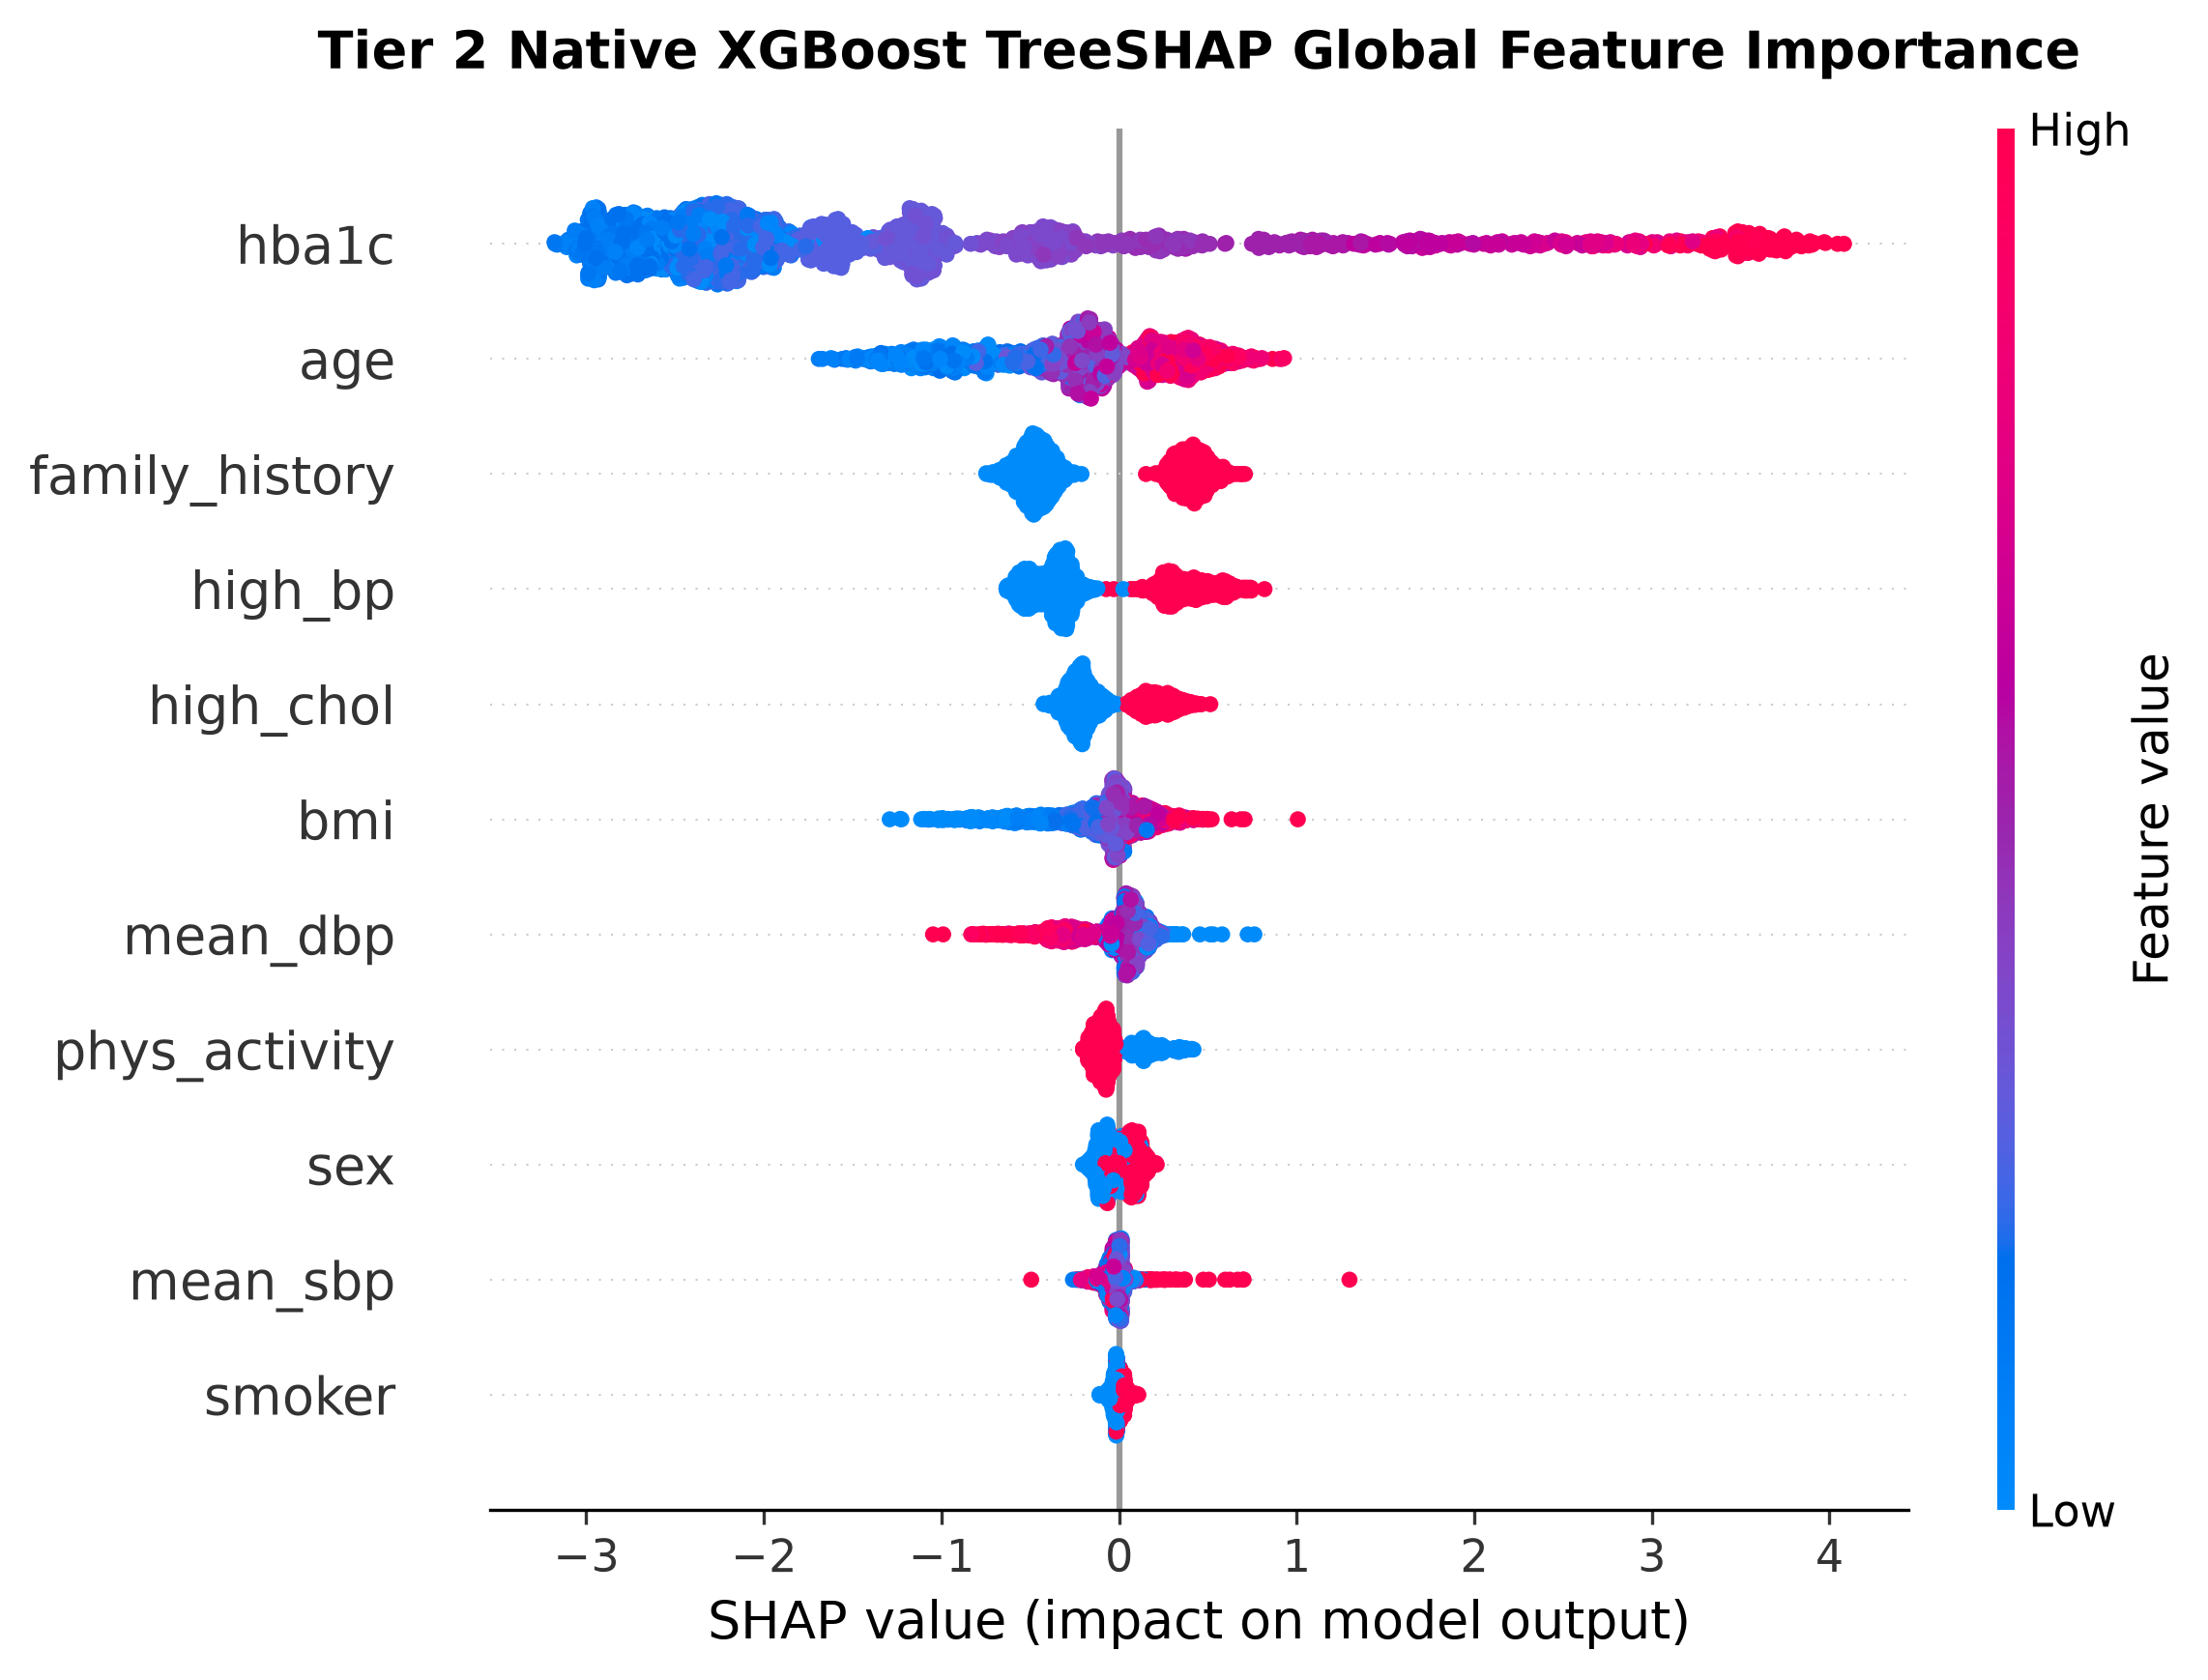

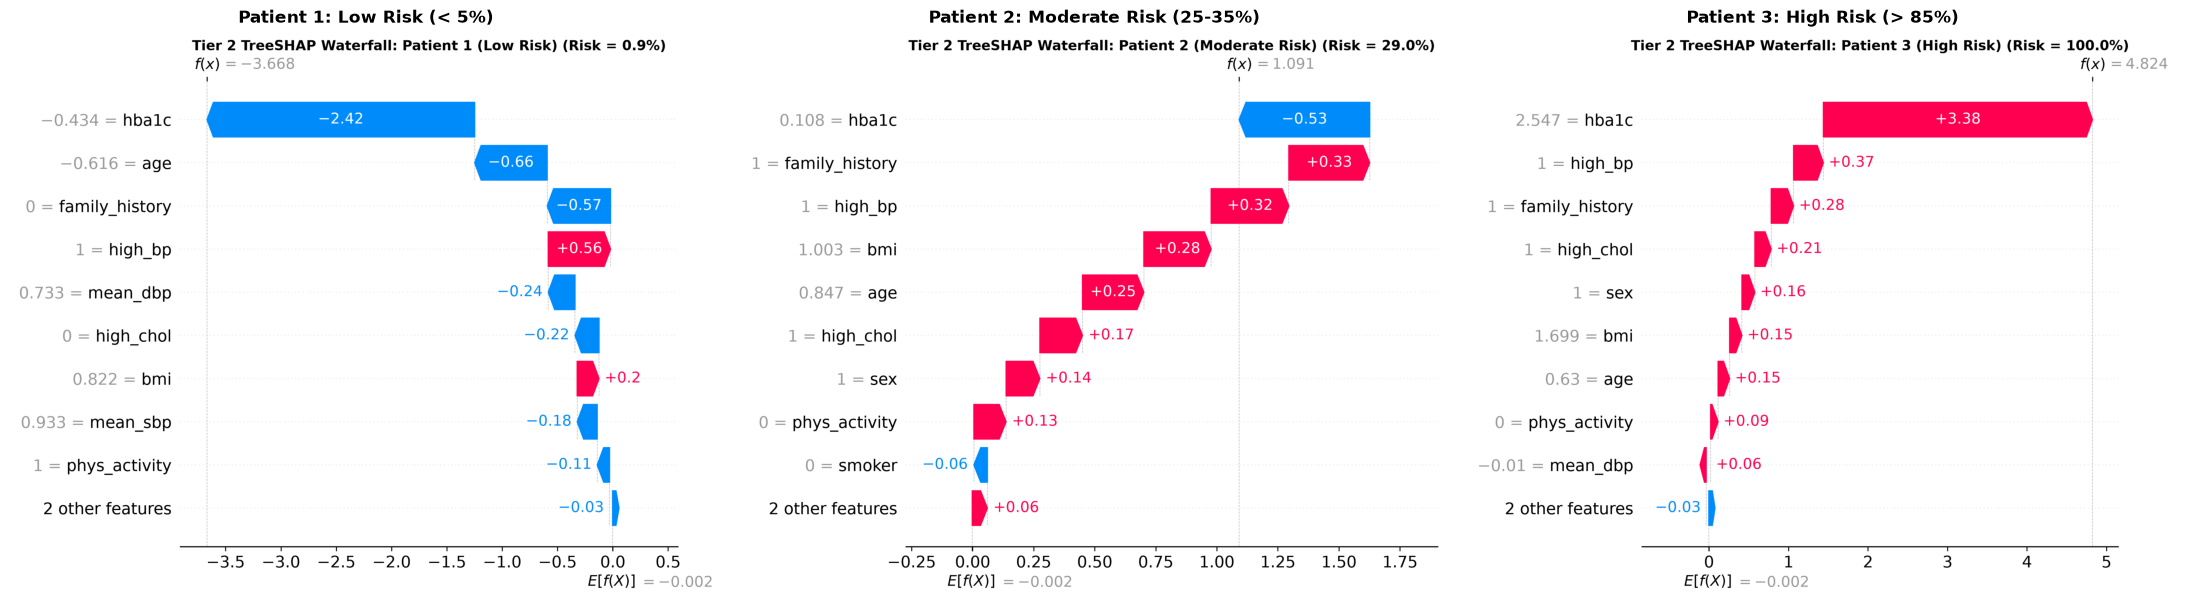

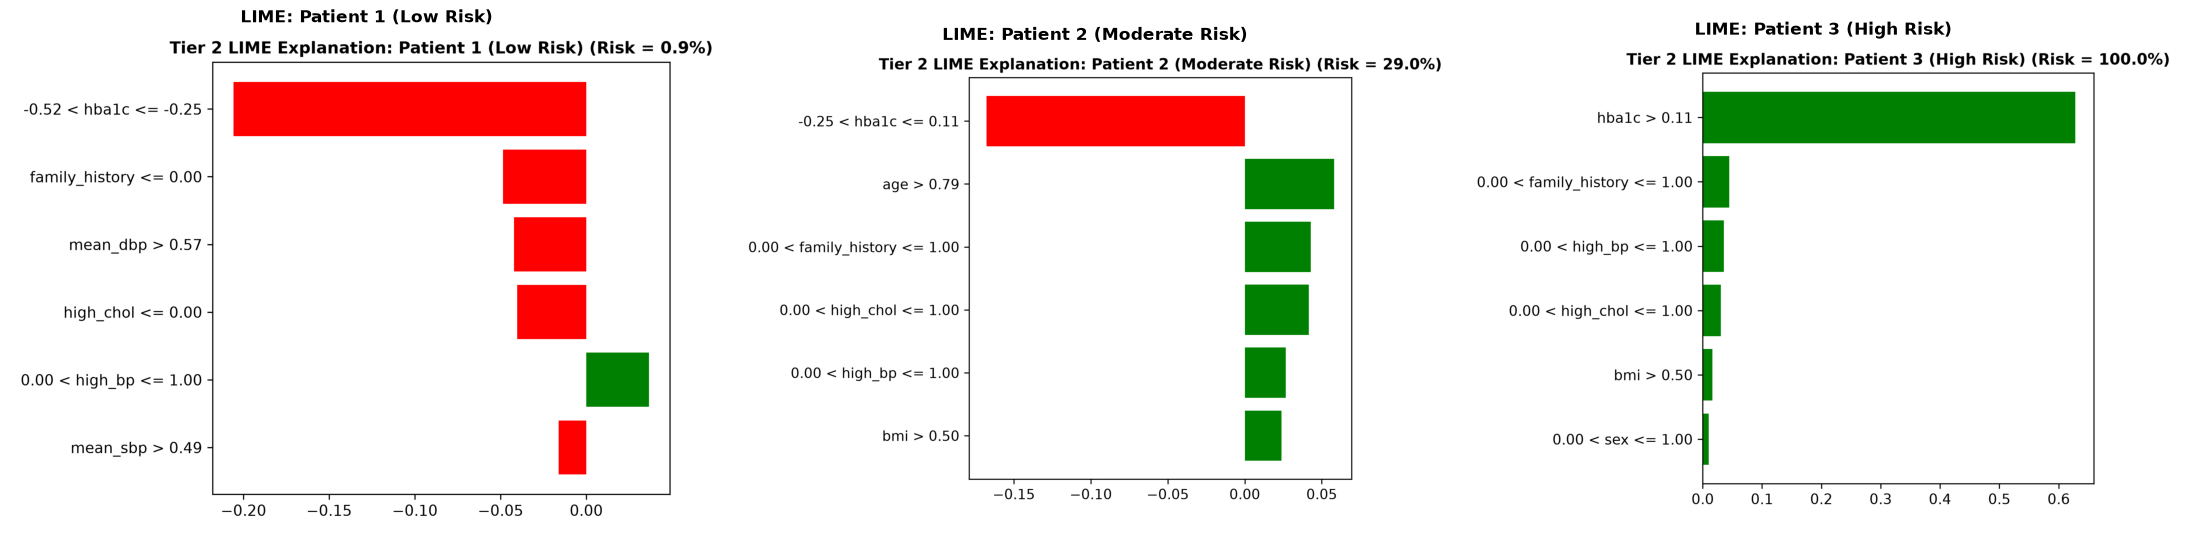

In [21]:
t2_shap_rank = pd.read_csv('../reports/tables/tier2_shap_global_rankings.csv')
print('=== Top 5 Tier 2 Global Feature Drivers ===')
for _, r in t2_shap_rank.head(5).iterrows():
    print(f"  Rank {int(r['Rank'])}: {r['Feature']:<16} (Mean |SHAP| = {r['Mean_Abs_SHAP']:.4f})")
print(f"\nHbA1c Rank: #{int(t2_shap_rank[t2_shap_rank['Feature']=='hba1c']['Rank'].values[0])} (Overwhelmingly the primary driver)\n")

display(Image(filename='../reports/figures/tier2_shap_summary.png'))

display(HTML('<h3>Patient-Level SHAP Waterfall Explanations (Low, Moderate, High Risk)</h3>'))
fig, axes = plt.subplots(1, 3, figsize=(22, 6))
for idx, (f_name, tit) in enumerate([
    ('tier2_shap_waterfall_patient_1.png', 'Patient 1: Low Risk (< 5%)'),
    ('tier2_shap_waterfall_patient_2.png', 'Patient 2: Moderate Risk (25-35%)'),
    ('tier2_shap_waterfall_patient_3.png', 'Patient 3: High Risk (> 85%)')
]):
    im = PILImage.open(f'../reports/figures/{f_name}')
    axes[idx].imshow(im)
    axes[idx].axis('off')
    axes[idx].set_title(tit, fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

display(HTML('<h3>Patient-Level LIME Surrogate Explanations</h3>'))
fig, axes = plt.subplots(1, 3, figsize=(22, 6))
for idx, (f_name, tit) in enumerate([
    ('tier2_lime_patient_1.png', 'LIME: Patient 1 (Low Risk)'),
    ('tier2_lime_patient_2.png', 'LIME: Patient 2 (Moderate Risk)'),
    ('tier2_lime_patient_3.png', 'LIME: Patient 3 (High Risk)')
]):
    im = PILImage.open(f'../reports/figures/{f_name}')
    axes[idx].imshow(im)
    axes[idx].axis('off')
    axes[idx].set_title(tit, fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

## 21. Tier 2 Risk Level Stratification & Observed Diabetes Rates
Distribution of test individuals across Low, Moderate, and High clinical tiers and observed diabetes incidence.

Tier 2 Optimal Screening Threshold: 0.290
Tier 2 High-Accuracy Threshold:    0.376
Low Risk Tier:      < 0.15
Moderate Risk Tier: 0.15 to 0.40
High Risk Tier:     >= 0.40



Risk Tier Level,Score Range,Test Patients (N),Share of Test Cohort,Observed Diabetes Rate
Low Risk,< 0.15,1983,82.90%,2.98%
Moderate Risk,0.15 - 0.40,102,4.26%,35.29%
High Risk,>= 0.40,307,12.83%,80.46%


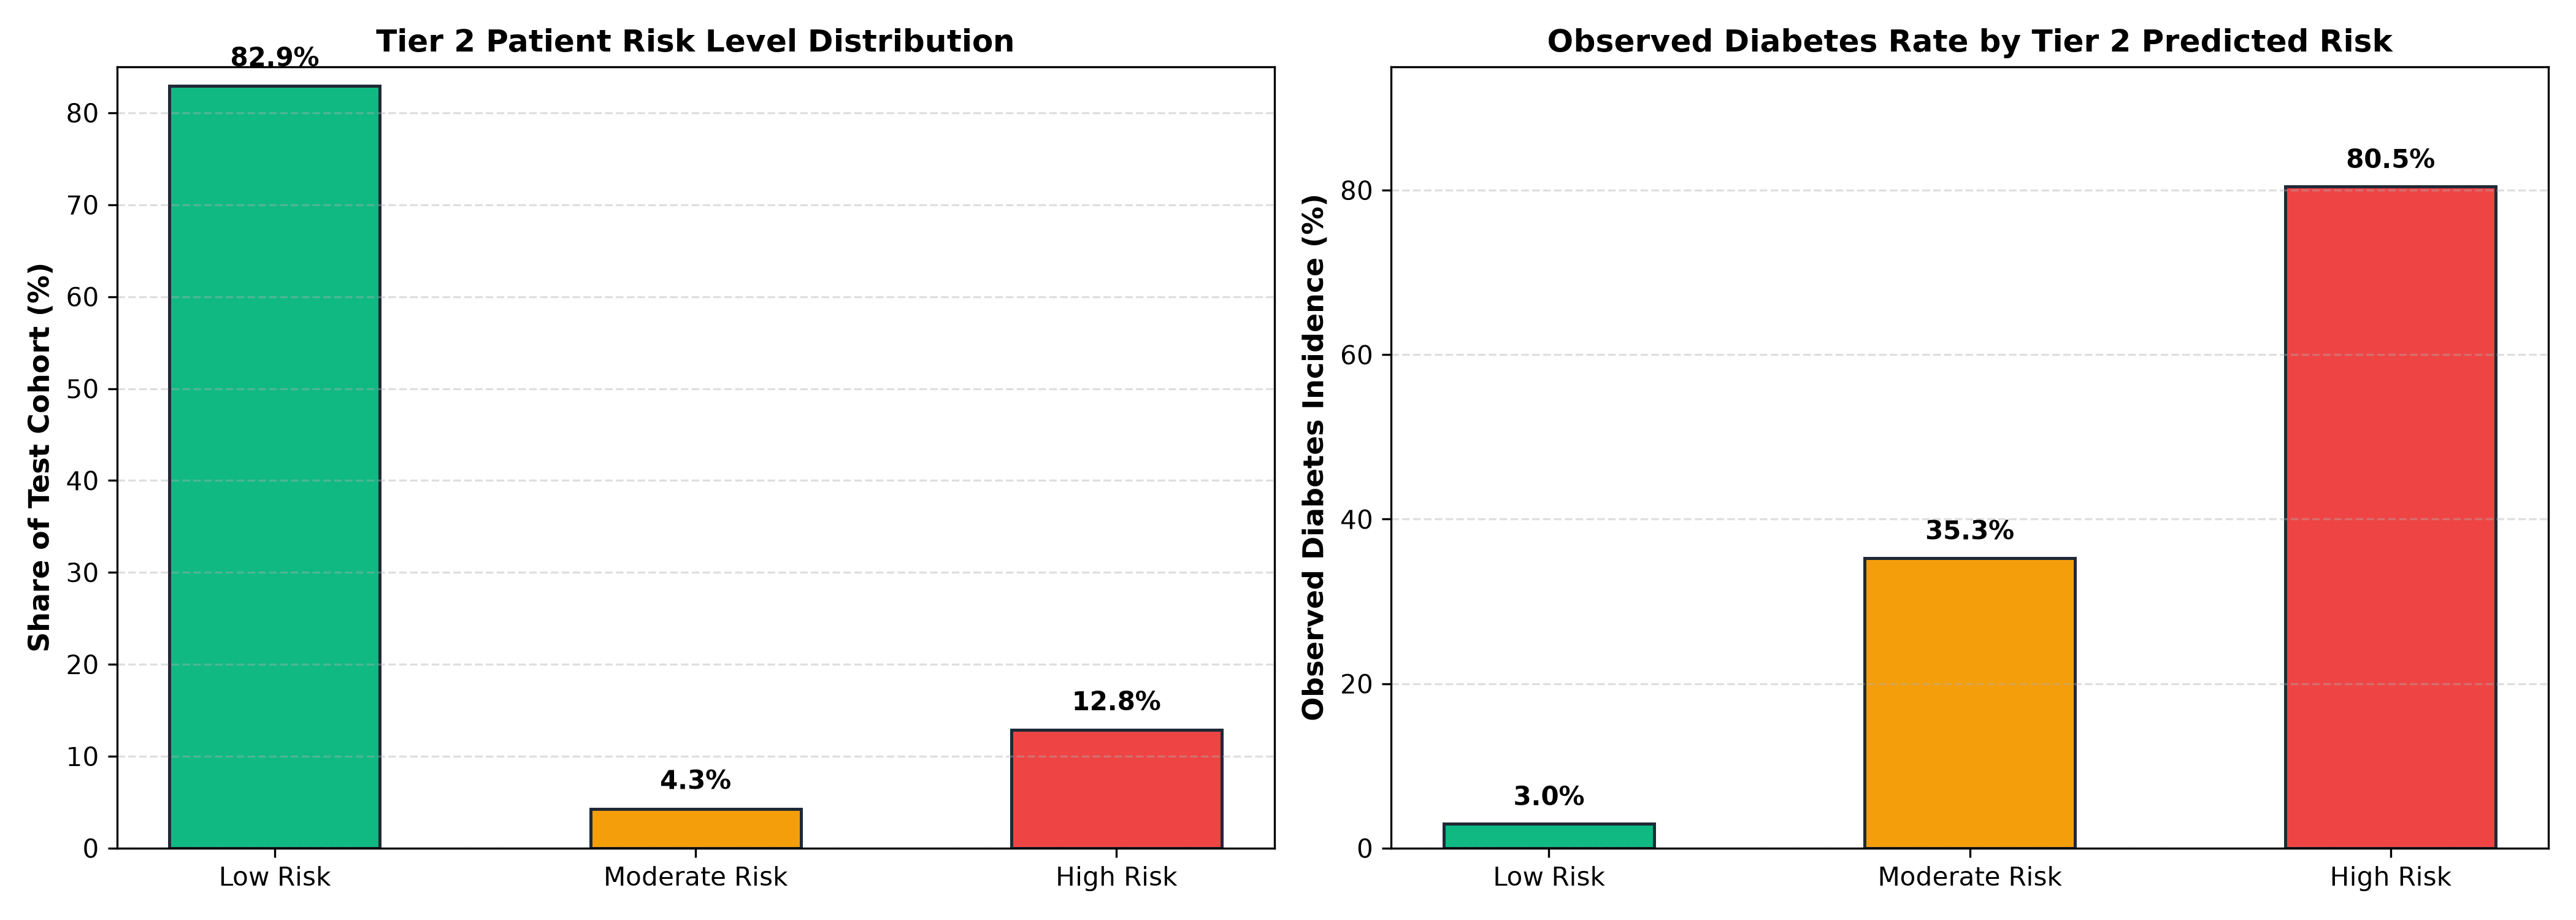

In [22]:
with open('../models/tier2_risk_thresholds.json', 'r') as f:
    t2_risk_meta = json.load(f)

print(f"Tier 2 Optimal Screening Threshold: {t2_risk_meta['decision_threshold']:.3f}")
print(f"Tier 2 High-Accuracy Threshold:    {t2_risk_meta['high_accuracy_threshold']:.3f}")
print(f"Low Risk Tier:      < {t2_risk_meta['threshold_low']:.2f}")
print(f"Moderate Risk Tier: {t2_risk_meta['threshold_low']:.2f} to {t2_risk_meta['threshold_high']:.2f}")
print(f"High Risk Tier:     >= {t2_risk_meta['threshold_high']:.2f}\n")

r_t2_df = pd.DataFrame(t2_risk_meta['risk_summary'])
r_t2_df['share_of_test'] = r_t2_df['share_of_test'].apply(lambda x: f'{x*100:.2f}%')
r_t2_df['observed_diabetes_rate'] = r_t2_df['observed_diabetes_rate'].apply(lambda x: f'{x*100:.2f}%')
r_t2_df.columns = ['Risk Tier Level', 'Score Range', 'Test Patients (N)', 'Share of Test Cohort', 'Observed Diabetes Rate']
display(HTML(r_t2_df.to_html(index=False, classes='table table-bordered table-hover')))

display(Image(filename='../reports/figures/tier2_risk_level_distribution.png'))

## 22. Production API Demonstration: The Unified `/predict` Endpoint
Verification of single-endpoint dispatch across 5 clinical scenarios, demonstrating automatic routing to `tier1_no_labs` or `tier2_with_hba1c`.

In [23]:
with open('../reports/tables/tier2_api_example_outputs.json', 'r') as f:
    api_demo = json.load(f)

demo_rows = []
for item in api_demo:
    sc = item['scenario']
    code = item['status_code']
    resp = item['response']
    model_u = resp.get('model_used', 'N/A (Error)')
    pred_p = resp.get('percentage_risk', 'N/A')
    fin_risk = resp.get('final_risk_level', 'N/A')
    notes = resp.get('escalation_notes', resp.get('detail', 'N/A'))
    if isinstance(notes, list):
        notes = notes[0].get('msg', str(notes))
    demo_rows.append({
        'Scenario': sc,
        'HTTP Status': code,
        'Model Routed': model_u,
        'Predicted Risk': pred_p,
        'Final Risk Tier': fin_risk,
        'Escalation / Error Notes': notes
    })

demo_df = pd.DataFrame(demo_rows)
display(HTML(demo_df.to_html(index=False, classes='table table-bordered table-striped table-hover')))

Scenario,HTTP Status,Model Routed,Predicted Risk,Final Risk Tier,Escalation / Error Notes
Call 1: No HbA1c (Pure Tier 1 Request),200,tier1_no_labs,35.6%,Moderate,ML-predicted risk level maintained.
"Call 2: Normal HbA1c (Tier 2, 5.2%)",200,tier2_with_hba1c,5.1%,Low,ML-predicted risk level maintained.
"Call 3: Prediabetic HbA1c (Tier 2, 5.9%)",200,tier2_with_hba1c,14.9%,Moderate,Escalated from Low to Moderate Risk: Elevated prediabetic laboratory markers detected; confirm with a clinician.
"Call 4: Diabetic-range HbA1c (Tier 2, 8.5%)",200,tier2_with_hba1c,94.4%,High,Escalated to High Risk: Glycemic markers are suggestive of diabetes range; confirm with a clinician.
"Call 5: Invalid HbA1c (Tier 2, 25.0% - Out of Range)",422,N/A (Error),N/A,N/A,"Value error, hba1c if provided must be between 3.0% and 18.0%"


## 23. Combined Clinical Limitations & Future Directions
1. **Scope and Objectives**: Tier 1 is an accessible non-invasive population screening tool. Tier 2 is a lab-augmented clinical risk stratification tool. Because they answer different clinical questions, their metrics must not be conflated.
2. **External Validation Asymmetry**: Tier 1 is validated on CDC BRFSS ($N = 249,049$). Tier 2 cannot be evaluated on BRFSS due to absence of laboratory blood draws in telephone surveys.
3. **Cross-Sectional Prevalence**: Both models estimate current prevalence, not 10-year incident risk. Prospective validation on longitudinal cohorts (e.g. UK Biobank) is recommended for prospective clinical adoption.
4. **Label Noise Integrity**: Ground truth is medical self-report (`DIQ010`), creating structural divergence for pharmacologically treated individuals.